# ⚡ File 7: Retraining Transformer (LR 3e-5) & Evaluasi Generalisasi Dataset Eksternal 2

**Judul Penelitian**: Perbandingan Kinerja RoBERTa-base dan DistilBERT-base untuk Deteksi Phishing URL  
**Eksperimen**: Eksplorasi Hyperparameter Learning Rate ($3 \times 10^{-5}$) & Pengujian Generalisasi *Out-of-Domain* (OOD) External 2  
**Target Environment**: Google Colab (NVIDIA Tesla T4 16GB, CUDA 12.x, FP16/AMP)  
**Storage Backend**: Google Drive (`/content/drive/MyDrive/Skripsi/`)  
**Peneliti**: Tim Riset Skripsi Phishing URL Detection  

---

### 🎯 Tujuan Utama Eksperimen:
1. **Retraining 1-Stage End-to-End dengan Learning Rate $3 \times 10^{-5}$**:
   - Melatih ulang arsitektur **DistilBERT-base** (Custom URLBERT WordPiece Tokenizer $> 30.000$ vocab) dan **RoBERTa-base** (Byte-Pair Encoding standar) dengan `learning_rate = 3e-5` (sebelumnya $2 \times 10^{-5}$).
   - Mempertahankan hyperparameter lainnya secara identik: `epochs=2`, `batch_size=64`, `warmup_ratio=0.10` (linear warmup lalu linear decay), `weight_decay=0.01`, optimizer `AdamW`, dan presisi campuran PyTorch AMP (`torch.amp.autocast('cuda')`).
   - Menyimpan checkpoint model dan tokenizer terbaik (berdasarkan F1-Score validasi) ke direktori baru tanpa menimpa model historis.
2. **Evaluasi In-Domain Independen (Test Set)**:
   - Memuat ulang model yang tersimpan di disk dan mengujinya pada `test.csv` in-domain.
   - Mengukur metrik komprehensif (Accuracy, Precision, Recall, F1-Binary, F1-Macro, ROC-AUC, PR-AUC, Latensi, Throughput, VRAM).
   - Menghitung **Delta In-Domain** terhadap model terdahulu (LR 2e-5) untuk melihat pengaruh langsung pada domain yang sama.
3. **Pengujian Generalisasi Silang Dataset Eksternal 2 (*Cross-Dataset Evaluation*)**:
   - Menguji kedua model baru secara langsung pada dataset real-world eksternal bersih (`external2_clean.csv`).
   - Menerapkan protokol verifikasi *Zero-Leakage* anti-bocor secara ketat sebelum inferensi.
   - Mengukur metrik industri siber: $TPR@FPR \le 0.1\%$, $TPR@FPR \le 1.0\%$, Expected Calibration Error (ECE 15-bin), Brier Score, dan stabilitas prediksi.
4. **Uji Inferensi Statistik & Jawaban Inti "Apakah Ada Peningkatan?"**:
   - Menghitung interval kepercayaan Bootstrap 95% CI (1000 resamples) untuk F1 dan ROC-AUC.
   - Uji signifikansi McNemar berpasangan (*paired contingency table*).
   - Membandingkan performa model baru (LR 3e-5) dengan hasil model terdahulu (LR 2e-5) pada dataset eksternal 2 yang sama (`ext2_evaluation_results.csv`).
   - Menguji klaim peningkatan dengan kaidah ketat: **hanya diklaim meningkat jika $\Delta > +0.005$ DAN rentang 95% CI tidak tumpang tindih (*non-overlapping*)**.

---

### ⚠️ Catatan Metodologis Penting (Pelatihan Unseeded):
> [!WARNING]
> Pelatihan pada notebook ini dijalankan **satu kali per arsitektur tanpa penguncian random seed** (`unseeded run` / tanpa `torch.manual_seed` atau `set_seed`).  
> Hal ini dilakukan untuk mengamati konvergensi alami model pada laju pembelajaran yang lebih dinamis. Karena tidak ada random seed tetap, hasil pelatihan memiliki variansi stokastik dari inisialisasi bobot dan urutan mini-batch, sehingga **hasil tidak dapat direproduksi secara bit-by-bit persis**.  
> Selisih metrik dalam batas toleransi $\pm 0.005$ dianggap sebagai fluktuasi stokastik wajar (*noise*), bukan peningkatan/penurunan riil yang signifikan.


## 1. Setup Lingkungan, Dependensi & GPU Verification

Pada tahap ini, seluruh pustaka deep learning (PyTorch, Transformers, Tokenizers, Accelerate), manipulasi data (Pandas, NumPy), evaluasi (Scikit-Learn, SciPy), dan visualisasi resolusi tinggi (Matplotlib, Seaborn) diinstal dan diimpor. Google Drive dihubungkan untuk persistensi data dan model.


In [1]:
# Instalasi pustaka transformer & visualisasi di Google Colab
!pip install transformers tokenizers torch accelerate scikit-learn pandas numpy tqdm matplotlib seaborn scipy -q

import os
import sys
import gc
import time
import math
import re
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, interpolate

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR
from tqdm.auto import tqdm

# Hugging Face Transformers & Tokenizers
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    PreTrainedTokenizerFast
)
from tokenizers import Tokenizer
from tokenizers.models import WordPiece
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.processors import TemplateProcessing

# Scikit-Learn Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve, brier_score_loss
)

warnings.filterwarnings('ignore')

# Konfigurasi Tampilan Visual Matplotlib & Seaborn (Standar Publikasi Ilmiah 300 DPI)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
sns.set_theme(style="whitegrid", palette="muted")

print("✅ [OK] Seluruh dependensi berhasil diimpor dengan konfigurasi visual 300 DPI.")


✅ [OK] Seluruh dependensi berhasil diimpor dengan konfigurasi visual 300 DPI.


In [2]:
# 1. Mount Google Drive
print("[INFO] Melakukan mounting Google Drive...")
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("✅ [OK] Google Drive berhasil terhubung.")
except Exception as e:
    print(f"⚠️ Melewati drive.mount (berjalan di luar lingkungan standar Colab): {e}")

# 2. Verifikasi Ketersediaan GPU CUDA
print("\n" + "=" * 70)
print("🖥️ PEMERIKSAAN AKSES GPU (NVIDIA CUDA)")
print("=" * 70)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    total_mem = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    cuda_ver = torch.version.cuda
    print(f"✅ GPU Aktif        : {gpu_name}")
    print(f"   Alokasi VRAM     : {total_mem:.2f} GB")
    print(f"   Versi CUDA       : {cuda_ver}")
    print(f"   Target Presisi   : PyTorch AMP (FP16 Accelerated)")
else:
    print("⚠️ CUDA GPU TIDAK TERDETEKSI!")
    print("   Pelatihan Transformer akan berjalan di CPU (sangat lambat).")
    print("   Sangat disarankan mengubah runtime Colab: Runtime -> Change runtime type -> T4 GPU.")


Mounted at /content/drive
✅ [OK] Google Drive berhasil terhubung.

🖥️ PEMERIKSAAN AKSES GPU (NVIDIA CUDA)
✅ GPU Aktif        : NVIDIA A100-SXM4-40GB
   Alokasi VRAM     : 39.49 GB
   Versi CUDA       : 13.0
   Target Presisi   : PyTorch AMP (FP16 Accelerated)


## 2. Konfigurasi Path Proyek & Sel Verifikasi Integritas File

Seluruh jalur direktori dan file masukan diatur secara **hardcoded** sesuai dengan struktur direktori Google Drive yang ditentukan. Tidak ada logika pencarian dinamis atau fallback path alternatif. Jika salah satu file masukan tidak ditemukan, sistem akan segera menghentikan eksekusi dengan pesan kesalahan yang jelas.


In [3]:
# ======================================================================
# ⚙️ KONFIGURASI PATH UTAMA (HARDCODED - NO FALLBACK) & HYPERPARAMETER
# ======================================================================

# Direktori & File Masukan (Input)
BASE_DIR              = "/content/drive/MyDrive/Skripsi"
DATA_DIR              = "/content/drive/MyDrive/Skripsi/new data"
TRAIN_CSV             = "/content/drive/MyDrive/Skripsi/new data/train.csv"
VAL_CSV               = "/content/drive/MyDrive/Skripsi/new data/val.csv"
TEST_CSV              = "/content/drive/MyDrive/Skripsi/new data/test.csv"
CUSTOM_TOKENIZER_DIR  = "/content/drive/MyDrive/Skripsi/custom_url_tokenizer"
VOCAB_MERGED          = "/content/drive/MyDrive/Skripsi/custom_url_tokenizer/vocab_merged.txt"
MODELS_DIR            = "/content/drive/MyDrive/Skripsi/models"
RESULTS_DIR           = "/content/drive/MyDrive/Skripsi/results"
EXTERNAL2_CLEAN_CSV   = "/content/drive/MyDrive/Skripsi/data/external2/external2_clean.csv"
OLD_INDOMAIN_RESULTS  = "/content/drive/MyDrive/Skripsi/results/transformer_training_results.csv"
OLD_EXT2_RESULTS      = "/content/drive/MyDrive/Skripsi/results/ext2_evaluation_results.csv"
LOG_FILE              = "/content/drive/MyDrive/Skripsi/SKRIPSI_LOG.md"

# Path Model Baru (Dibuat saat training, JANGAN menimpa model lama)
DISTIL_SAVE_DIR       = "/content/drive/MyDrive/Skripsi/models/distilbert_lr3e5"
ROBERTA_SAVE_DIR      = "/content/drive/MyDrive/Skripsi/models/roberta_lr3e5"
NEW_INDOMAIN_RESULTS  = "/content/drive/MyDrive/Skripsi/results/lr3e5_training_results.csv"

# Hyperparameter Pelatihan (Target Uji: LR 3e-5)
LEARNING_RATE         = 3e-5       # Diubah dari 2e-5 menjadi 3e-5
EPOCHS                = 2          # 2 Epochs identik dengan Notebook 03
BATCH_SIZE            = 64         # Batch size teroptimasi GPU T4
WARMUP_RATIO          = 0.10       # 10% Linear Warmup dilanjutkan Linear Decay
WEIGHT_DECAY          = 0.01       # AdamW Regularization
MAX_LENGTH            = 128        # Maksimal panjang sekuens token

# Pembuatan Direktori Output Baru jika Belum Ada
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(DISTIL_SAVE_DIR, exist_ok=True)
os.makedirs(ROBERTA_SAVE_DIR, exist_ok=True)

print("✅ [OK] Seluruh variabel konfigurasi berhasil didefinisikan.")
print(f"   Learning Rate      : {LEARNING_RATE}")
print(f"   Epochs             : {EPOCHS}")
print(f"   Batch Size         : {BATCH_SIZE}")
print(f"   Warmup Ratio       : {WARMUP_RATIO*100:.0f}%")
print(f"   Target DistilBERT  : {DISTIL_SAVE_DIR}")
print(f"   Target RoBERTa     : {ROBERTA_SAVE_DIR}")
print(f"   Target In-Domain   : {NEW_INDOMAIN_RESULTS}")


✅ [OK] Seluruh variabel konfigurasi berhasil didefinisikan.
   Learning Rate      : 3e-05
   Epochs             : 2
   Batch Size         : 64
   Warmup Ratio       : 10%
   Target DistilBERT  : /content/drive/MyDrive/Skripsi/models/distilbert_lr3e5
   Target RoBERTa     : /content/drive/MyDrive/Skripsi/models/roberta_lr3e5
   Target In-Domain   : /content/drive/MyDrive/Skripsi/results/lr3e5_training_results.csv


In [4]:
# ======================================================================
# 🔍 SEL VERIFIKASI KEBERADAAN SELURUH FILE DAN DIREKTORI INPUT
# ======================================================================
print("=" * 70)
print("🔍 MEMERIKSA KEBERADAAN FILE INPUT WAJIB")
print("=" * 70)

input_checks = [
    ("Train Dataset (train.csv)", TRAIN_CSV, False),
    ("Validation Dataset (val.csv)", VAL_CSV, False),
    ("Test Dataset (test.csv)", TEST_CSV, False),
    ("Kosakata Tokenizer (vocab_merged.txt)", VOCAB_MERGED, False),
    ("Hasil In-Domain Lama (transformer_training_results.csv)", OLD_INDOMAIN_RESULTS, False),
    ("Dataset External 2 Bersih (external2_clean.csv)", EXTERNAL2_CLEAN_CSV, True),
    ("Hasil External 2 Lama (ext2_evaluation_results.csv)", OLD_EXT2_RESULTS, True),
]

all_passed = True
for label, path, is_ext2_file in input_checks:
    exists = os.path.exists(path)
    status_icon = "✅" if exists else "❌"
    print(f"{status_icon} [{label:<52}]: {path}")
    if not exists:
        all_passed = False
        if is_ext2_file:
            raise FileNotFoundError(
                f"❌ Jalankan dulu notebook 06 versi terbaru (dataset url_features_extracted1.csv) agar file ini terbentuk.\nPath: {path}"
            )
        else:
            raise FileNotFoundError(
                f"❌ File input wajib tidak ditemukan: {path}\nPastikan Google Drive ter-mount dan path sesuai."
            )

print("\n" + "=" * 70)
print("✅ [PASS] Seluruh file input terverifikasi lengkap dan siap diproses!")
print("=" * 70)


🔍 MEMERIKSA KEBERADAAN FILE INPUT WAJIB
✅ [Train Dataset (train.csv)                           ]: /content/drive/MyDrive/Skripsi/new data/train.csv
✅ [Validation Dataset (val.csv)                        ]: /content/drive/MyDrive/Skripsi/new data/val.csv
✅ [Test Dataset (test.csv)                             ]: /content/drive/MyDrive/Skripsi/new data/test.csv
✅ [Kosakata Tokenizer (vocab_merged.txt)               ]: /content/drive/MyDrive/Skripsi/custom_url_tokenizer/vocab_merged.txt
✅ [Hasil In-Domain Lama (transformer_training_results.csv)]: /content/drive/MyDrive/Skripsi/results/transformer_training_results.csv
✅ [Dataset External 2 Bersih (external2_clean.csv)     ]: /content/drive/MyDrive/Skripsi/data/external2/external2_clean.csv
✅ [Hasil External 2 Lama (ext2_evaluation_results.csv) ]: /content/drive/MyDrive/Skripsi/results/ext2_evaluation_results.csv

✅ [PASS] Seluruh file input terverifikasi lengkap dan siap diproses!


## 3. Pemuatan Dataset In-Domain & Delimiter-Spacing Preprocessing

Pada bagian ini, dataset `train.csv`, `val.csv`, dan `test.csv` dimuat. Preprocessing dilakukan sesuai spesifikasi model:
- **DistilBERT-base**: Menggunakan representasi teks `url_spaced` yang dihasilkan dari fungsi `preprocess_delimiter_spacing(url_norm)`. Fungsi ini menambahkan spasi di sekitar delimiter URL (`://`, `/`, `?`, `=`, `&`, `.`, `-`) agar WordPiece tokenizer dapat mengenali token domain, path, dan parameter secara terisolasi tanpa terpotong sembarangan.
- **RoBERTa-base**: Menggunakan representasi teks `url_norm` langsung (mengandalkan kemampuan Byte-Pair Encoding subword standar RoBERTa).


In [5]:
print("[INFO] Memuat dataset Train, Val, dan Test...")

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

print(f"[OK] Train Set : {len(train_df):,} sampel")
print(f"[OK] Val Set   : {len(val_df):,} sampel")
print(f"[OK] Test Set  : {len(test_df):,} sampel")

def preprocess_delimiter_spacing(url_str: str) -> str:
    '''
    Menambahkan spasi di sekitar delimiter URL agar WordPiece tokenizer
    dapat membedakan token subword spesifik domain, path, dan parameter.
    '''
    if not isinstance(url_str, str):
        return ""
    u = url_str.strip()
    u = u.replace('://', ' :// ')
    u = u.replace('/', ' / ')
    u = u.replace('?', ' ? ')
    u = u.replace('=', ' = ')
    u = u.replace('&', ' & ')
    u = u.replace('.', ' . ')
    u = u.replace('-', ' - ')
    return re.sub(r'\s+', ' ', u).strip()

text_col = 'url_norm' if 'url_norm' in train_df.columns else 'url'
print(f"[INFO] Menggunakan kolom teks acuan: '{text_col}'...")

# DistilBERT menggunakan url_spaced (WordPiece dengan spasi delimiter)
print("[INFO] Membuat kolom 'url_spaced' untuk DistilBERT WordPiece...")
train_df['url_spaced'] = train_df[text_col].apply(preprocess_delimiter_spacing)
val_df['url_spaced'] = val_df[text_col].apply(preprocess_delimiter_spacing)
test_df['url_spaced'] = test_df[text_col].apply(preprocess_delimiter_spacing)

# Pastikan kolom url_norm tersedia untuk input RoBERTa
if 'url_norm' not in train_df.columns:
    train_df['url_norm'] = train_df[text_col]
if 'url_norm' not in val_df.columns:
    val_df['url_norm'] = val_df[text_col]
if 'url_norm' not in test_df.columns:
    test_df['url_norm'] = test_df[text_col]

print("\nContoh Perbandingan URL Asli/Norm vs Delimiter-Spaced:")
for i in range(2):
    print(f" [{i+1}] Asli/Norm : {train_df['url_norm'].iloc[i]}")
    print(f"     Spaced    : {train_df['url_spaced'].iloc[i]}\n")

print(f"Distribusi Kelas Train : {dict(train_df['label'].value_counts())}")
print(f"Distribusi Kelas Val   : {dict(val_df['label'].value_counts())}")
print(f"Distribusi Kelas Test  : {dict(test_df['label'].value_counts())}")


[INFO] Memuat dataset Train, Val, dan Test...
[OK] Train Set : 927,898 sampel
[OK] Val Set   : 198,052 sampel
[OK] Test Set  : 222,316 sampel
[INFO] Menggunakan kolom teks acuan: 'url_norm'...
[INFO] Membuat kolom 'url_spaced' untuk DistilBERT WordPiece...

Contoh Perbandingan URL Asli/Norm vs Delimiter-Spaced:
 [1] Asli/Norm : bs-369.com/views/account/login.aspx?returnurl=
     Spaced    : bs - 369 . com / views / account / login . aspx ? returnurl =

 [2] Asli/Norm : amelihair.ru/images/6550054213/745353769679
     Spaced    : amelihair . ru / images / 6550054213 / 745353769679

Distribusi Kelas Train : {0: np.int64(478671), 1: np.int64(449227)}
Distribusi Kelas Val   : {0: np.int64(100051), 1: np.int64(98001)}
Distribusi Kelas Test  : {0: np.int64(120335), 1: np.int64(101981)}


## 4. Inisialisasi Tokenizer Kustom (Custom URLBERT WordPiece & RoBERTa BPE)

1. **Custom URLBERT WordPiece Tokenizer**: Dibangun langsung dari file kosakata gabungan `vocab_merged.txt` (> 30.000 kata/subword spesifik domain siber dan URL). Pre-tokenizer dikonfigurasi menggunakan `Whitespace` dan post-processor membubuhkan token khusus `[CLS]` dan `[SEP]`.
2. **RoBERTa-base Tokenizer**: Memuat tokenizer resmi `roberta-base` berbasis *Byte-Pair Encoding* (BPE) dengan kosakata ~50.265 token.


In [6]:
print("[INFO] Membangun Custom URLBERT Tokenizer dari Google Drive...")

if not os.path.exists(VOCAB_MERGED):
    raise FileNotFoundError(
        f"❌ File kosakata tidak ditemukan di {CUSTOM_TOKENIZER_DIR}!\n"
        f"Pastikan vocab_merged.txt berada di: {VOCAB_MERGED}"
    )

print(f"[OK] Memuat file kosakata kustom: {VOCAB_MERGED}")

# 1. Bangun WordPiece model dari file vocab_merged.txt
wp_model = WordPiece.from_file(VOCAB_MERGED, unk_token="[UNK]")
raw_tokenizer = Tokenizer(wp_model)

# 2. Pre-tokenizer menggunakan Whitespace
raw_tokenizer.pre_tokenizer = Whitespace()

# 3. Post-processor [CLS] dan [SEP]
cls_id = raw_tokenizer.token_to_id("[CLS]")
sep_id = raw_tokenizer.token_to_id("[SEP]")

if cls_id is not None and sep_id is not None:
    raw_tokenizer.post_processor = TemplateProcessing(
        single="[CLS] $A [SEP]",
        pair="[CLS] $A [SEP] $B:1 [SEP]:1",
        special_tokens=[
            ("[CLS]", cls_id),
            ("[SEP]", sep_id)
        ]
    )

# 4. Bungkus dengan PreTrainedTokenizerFast Hugging Face
custom_tokenizer = PreTrainedTokenizerFast(
    tokenizer_object=raw_tokenizer,
    unk_token="[UNK]",
    sep_token="[SEP]",
    pad_token="[PAD]",
    cls_token="[CLS]",
    mask_token="[MASK]",
    do_lower_case=True
)

# 5. Asersi Validasi Ukuran Kosakata
print(f"[INFO] Jumlah kosakata tokenizer kustom: {len(custom_tokenizer):,}")
assert len(custom_tokenizer) > 30000, f"❌ Vocab size terlalu kecil ({len(custom_tokenizer)})! Harap periksa file vocab."
print("✅ [PASS] Asersi Berhasil: len(custom_tokenizer) > 30,000 (Vocab collapse dicegah).")

# Tokenizer untuk RoBERTa (Byte-Pair Encoding standar)
print("\n[INFO] Memuat tokenizer Byte-Pair Encoding untuk RoBERTa-base...")
roberta_tokenizer = AutoTokenizer.from_pretrained("roberta-base")
print(f"✅ [OK] RoBERTa Tokenizer siap: {len(roberta_tokenizer):,} vocab.")


[INFO] Membangun Custom URLBERT Tokenizer dari Google Drive...
[OK] Memuat file kosakata kustom: /content/drive/MyDrive/Skripsi/custom_url_tokenizer/vocab_merged.txt
[INFO] Jumlah kosakata tokenizer kustom: 30,372
✅ [PASS] Asersi Berhasil: len(custom_tokenizer) > 30,000 (Vocab collapse dicegah).

[INFO] Memuat tokenizer Byte-Pair Encoding untuk RoBERTa-base...


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

✅ [OK] RoBERTa Tokenizer siap: 50,265 vocab.


## 5. Konstruksi PyTorch Dataset & Engine Pelatihan 1-Stage AMP

Di bawah ini didefinisikan modul-modul inti pelatihan yang disalin persis dari arsitektur Notebook 03:
- **`URLDataset`**: Dataset PyTorch dengan padding dan pemotongan sekuens dinamis `max_length=128`.
- **`get_linear_warmup_scheduler`**: Penjadwal laju pembelajaran dengan fase pemanasan linier (*warmup*) 10% dan penurunan linier (*decay*) hingga akhir pelatihan.
- **`evaluate_model` & `compute_metrics`**: Mesin evaluasi inferensi batch berpresisi campuran FP16 yang menghitung metrik lengkap.
- **`train_one_stage_model`**: Loop pelatihan PyTorch AMP 1-stage end-to-end yang telah diperbarui menggunakan `torch.amp.GradScaler('cuda')` dan `torch.amp.autocast('cuda')` untuk mengeliminasi `FutureWarning` pada versi PyTorch terbaru, serta menyimpan riwayat *loss* per epoch untuk analisis kurva pembelajaran.


In [7]:
class URLDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = self.labels[idx]

        encoding = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt'
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(label, dtype=torch.long)
        }

def create_dataloaders(train_texts, train_labels, val_texts, val_labels, test_texts, test_labels, tokenizer, batch_size=64):
    train_dataset = URLDataset(train_texts, train_labels, tokenizer)
    val_dataset = URLDataset(val_texts, val_labels, tokenizer)
    test_dataset = URLDataset(test_texts, test_labels, tokenizer)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=True, num_workers=2)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, pin_memory=True, num_workers=2)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, pin_memory=True, num_workers=2)

    return train_loader, val_loader, test_loader

def get_linear_warmup_scheduler(optimizer, num_warmup_steps, num_training_steps):
    def lr_lambda(current_step):
        if current_step < num_warmup_steps:
            return float(current_step) / float(max(1, num_warmup_steps))
        return max(
            0.0,
            float(num_training_steps - current_step) / float(max(1, num_training_steps - num_warmup_steps))
        )
    return LambdaLR(optimizer, lr_lambda)

def evaluate_model(model, dataloader, device):
    model.eval()
    total_loss = 0.0
    all_preds = []
    all_labels = []
    all_probs = []

    use_cuda = torch.cuda.is_available()
    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            if hasattr(torch, 'amp') and hasattr(torch.amp, 'autocast'):
                autocast_ctx = torch.amp.autocast('cuda', enabled=use_cuda)
            else:
                autocast_ctx = torch.cuda.amp.autocast(enabled=use_cuda)

            with autocast_ctx:
                outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
                loss = outputs.loss

            total_loss += loss.item()
            logits = outputs.logits
            probs = torch.softmax(logits, dim=-1)
            preds = torch.argmax(logits, dim=-1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs[:, 1].cpu().numpy())

    avg_loss = total_loss / len(dataloader)
    return avg_loss, np.array(all_labels), np.array(all_preds), np.array(all_probs)

def compute_metrics(y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1_bin = f1_score(y_true, y_pred, average='binary', zero_division=0)
    f1_mac = f1_score(y_true, y_pred, average='macro', zero_division=0)
    try:
        roc_auc = roc_auc_score(y_true, y_prob)
    except Exception:
        roc_auc = np.nan
    try:
        pr_auc = average_precision_score(y_true, y_prob)
    except Exception:
        pr_auc = np.nan

    return {
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1_binary': f1_bin,
        'f1_macro': f1_mac,
        'roc_auc': roc_auc,
        'pr_auc': pr_auc
    }

def train_one_stage_model(
    model, train_loader, val_loader, tokenizer,
    save_dir, model_name="DistilBERT",
    epochs=2, lr=3e-5, warmup_ratio=0.10, weight_decay=0.01,
    device=device
):
    print(f"\n======================================================================")
    print(f"🚀 [1-STAGE FINE-TUNING] {model_name} (End-to-End FP16/AMP)")
    print(f"   Epochs: {epochs} | LR: {lr} | Warmup: {warmup_ratio*100:.0f}% | WD: {weight_decay}")
    print(f"   Target Save Directory: {save_dir}")
    print(f"======================================================================")

    model.to(device)
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    total_steps = len(train_loader) * epochs
    warmup_steps = int(warmup_ratio * total_steps)
    scheduler = get_linear_warmup_scheduler(optimizer, warmup_steps, total_steps)

    # PyTorch AMP Scaler bebas FutureWarning
    use_cuda = torch.cuda.is_available()
    if hasattr(torch, 'amp') and hasattr(torch.amp, 'GradScaler'):
        scaler = torch.amp.GradScaler('cuda', enabled=use_cuda)
    else:
        scaler = torch.cuda.amp.GradScaler(enabled=use_cuda)

    best_val_f1 = -1.0
    t_start_train = time.perf_counter()
    history = {'epochs': [], 'train_loss': [], 'val_loss': [], 'val_f1': []}

    for epoch in range(1, epochs + 1):
        model.train()
        total_train_loss = 0.0

        for step, batch in enumerate(train_loader):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            optimizer.zero_grad()
            if hasattr(torch, 'amp') and hasattr(torch.amp, 'autocast'):
                autocast_ctx = torch.amp.autocast('cuda', enabled=use_cuda)
            else:
                autocast_ctx = torch.cuda.amp.autocast(enabled=use_cuda)

            with autocast_ctx:
                outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
                loss = outputs.loss

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            total_train_loss += loss.item()

            if (step + 1) % 500 == 0 or (step + 1) == len(train_loader):
                cur_loss = total_train_loss / (step + 1)
                print(f"   [Epoch {epoch}/{epochs}] Step {step+1}/{len(train_loader)} | Train Loss: {cur_loss:.4f}")

        epoch_train_loss = total_train_loss / len(train_loader)

        # Evaluasi Akhir Epoch pada Validation Set
        val_loss, val_true, val_pred, val_prob = evaluate_model(model, val_loader, device)
        val_metrics = compute_metrics(val_true, val_pred, val_prob)
        print(f"   >> [Val Epoch {epoch}] Loss: {val_loss:.4f} | Acc: {val_metrics['accuracy']*100:.2f}% | F1-Binary: {val_metrics['f1_binary']:.4f} | ROC-AUC: {val_metrics['roc_auc']:.4f}")

        history['epochs'].append(epoch)
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(val_loss)
        history['val_f1'].append(val_metrics['f1_binary'])

        # Simpan checkpoint jika F1 meningkat
        if val_metrics['f1_binary'] > best_val_f1:
            best_val_f1 = val_metrics['f1_binary']
            os.makedirs(save_dir, exist_ok=True)
            model.save_pretrained(save_dir)
            tokenizer.save_pretrained(save_dir)
            print(f"   ⭐ Checkpoint terbaik disimpan ke: {save_dir} (Val F1: {best_val_f1:.4f})")

    train_duration = time.perf_counter() - t_start_train
    peak_vram_gb = torch.cuda.max_memory_allocated() / (1024**3) if torch.cuda.is_available() else 0.0
    print(f"\n[OK] Pelatihan selesai dalam {train_duration:.2f} dtk ({train_duration/60:.2f} menit) | Peak VRAM: {peak_vram_gb:.3f} GB")

    return history, train_duration, peak_vram_gb

print("✅ [OK] Kelas URLDataset, Evaluator, dan Engine Pelatihan 1-Stage AMP siap digunakan.")


✅ [OK] Kelas URLDataset, Evaluator, dan Engine Pelatihan 1-Stage AMP siap digunakan.


## 6. Eksekusi Pelatihan DistilBERT-base & RoBERTa-base (LR = 3e-5)

> [!NOTE]
> Pelatihan dilakukan satu kali per arsitektur secara berurutan tanpa set_seed.  
> Setelah tiap model selesai dilatih dan checkpoint terbaik disimpan ke disk, seluruh objek memori dan cache GPU langsung dibersihkan (`del model`, `torch.cuda.empty_cache()`, `gc.collect()`) agar tidak terjadi penumpukan VRAM.


In [8]:
# ======================================================================
# 1. PELATIHAN DISTILBERT-BASE DENGAN LEARNING RATE 3e-5 # [DIUBAH]
# ======================================================================
print("\n" + "=" * 70)
print("🚀 MEMULAI PELATIHAN: DistilBERT-base (Learning Rate = 3e-5)")
print("=" * 70)

# Persiapkan DataLoader untuk DistilBERT (menggunakan url_spaced)
train_loader_distil, val_loader_distil, test_loader_distil = create_dataloaders(
    train_df['url_spaced'], train_df['label'],
    val_df['url_spaced'], val_df['label'],
    test_df['url_spaced'], test_df['label'],
    custom_tokenizer,
    batch_size=BATCH_SIZE
)

# Inisialisasi Arsitektur DistilBERT-base
model_distil = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

# Resize embedding layer untuk mengakomodasi kosakata kustom (> 30.000)
model_distil.resize_token_embeddings(len(custom_tokenizer))

distil_history, distil_train_time, distil_peak_vram = train_one_stage_model(
    model=model_distil,
    train_loader=train_loader_distil,
    val_loader=val_loader_distil,
    tokenizer=custom_tokenizer,
    save_dir=DISTIL_SAVE_DIR,
    model_name="DistilBERT-base (LR 3e-5)",
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    warmup_ratio=WARMUP_RATIO,
    weight_decay=WEIGHT_DECAY,
    device=device
)

# Verifikasi Isi Folder Checkpoint DistilBERT
print(f"\n📂 Verifikasi Isi Folder Simpan DistilBERT: {DISTIL_SAVE_DIR}")
distil_files = os.listdir(DISTIL_SAVE_DIR)
for f_name in sorted(distil_files):
    f_path = os.path.join(DISTIL_SAVE_DIR, f_name)
    f_size_mb = os.path.getsize(f_path) / (1024 * 1024)
    print(f"   - {f_name:<30} ({f_size_mb:.2f} MB)")

# [DIUBAH] Simpan metadata training DistilBERT ke file JSON di RESULTS_DIR
distil_meta_path = os.path.join(RESULTS_DIR, "lr3e5_distil_meta.json") # [DIUBAH]
distil_meta = { # [DIUBAH]
    'history': distil_history, # [DIUBAH]
    'train_time': distil_train_time, # [DIUBAH]
    'peak_vram': distil_peak_vram # [DIUBAH]
} # [DIUBAH]
with open(distil_meta_path, "w", encoding="utf-8") as f: # [DIUBAH]
    json.dump(distil_meta, f, indent=2) # [DIUBAH]
print(f"💾 [SUKSES] Metadata DistilBERT tersimpan ke: {distil_meta_path}") # [DIUBAH]

# Bersihkan memori GPU
del model_distil
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()
print("🧹 [CLEANUP] Memori GPU dan objek DistilBERT berhasil dibersihkan.")



🚀 MEMULAI PELATIHAN: DistilBERT-base (Learning Rate = 3e-5)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



🚀 [1-STAGE FINE-TUNING] DistilBERT-base (LR 3e-5) (End-to-End FP16/AMP)
   Epochs: 2 | LR: 3e-05 | Warmup: 10% | WD: 0.01
   Target Save Directory: /content/drive/MyDrive/Skripsi/models/distilbert_lr3e5
   [Epoch 1/2] Step 500/14499 | Train Loss: 0.6139
   [Epoch 1/2] Step 1000/14499 | Train Loss: 0.4789
   [Epoch 1/2] Step 1500/14499 | Train Loss: 0.3945
   [Epoch 1/2] Step 2000/14499 | Train Loss: 0.3402
   [Epoch 1/2] Step 2500/14499 | Train Loss: 0.2980
   [Epoch 1/2] Step 3000/14499 | Train Loss: 0.2657
   [Epoch 1/2] Step 3500/14499 | Train Loss: 0.2395
   [Epoch 1/2] Step 4000/14499 | Train Loss: 0.2184
   [Epoch 1/2] Step 4500/14499 | Train Loss: 0.2002
   [Epoch 1/2] Step 5000/14499 | Train Loss: 0.1853
   [Epoch 1/2] Step 5500/14499 | Train Loss: 0.1728
   [Epoch 1/2] Step 6000/14499 | Train Loss: 0.1616
   [Epoch 1/2] Step 6500/14499 | Train Loss: 0.1520
   [Epoch 1/2] Step 7000/14499 | Train Loss: 0.1437
   [Epoch 1/2] Step 7500/14499 | Train Loss: 0.1362
   [Epoch 1/2] St

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   ⭐ Checkpoint terbaik disimpan ke: /content/drive/MyDrive/Skripsi/models/distilbert_lr3e5 (Val F1: 0.8967)
   [Epoch 2/2] Step 500/14499 | Train Loss: 0.0107
   [Epoch 2/2] Step 1000/14499 | Train Loss: 0.0105
   [Epoch 2/2] Step 1500/14499 | Train Loss: 0.0108
   [Epoch 2/2] Step 2000/14499 | Train Loss: 0.0106
   [Epoch 2/2] Step 2500/14499 | Train Loss: 0.0103
   [Epoch 2/2] Step 3000/14499 | Train Loss: 0.0105
   [Epoch 2/2] Step 3500/14499 | Train Loss: 0.0104
   [Epoch 2/2] Step 4000/14499 | Train Loss: 0.0104
   [Epoch 2/2] Step 4500/14499 | Train Loss: 0.0104
   [Epoch 2/2] Step 5000/14499 | Train Loss: 0.0104
   [Epoch 2/2] Step 5500/14499 | Train Loss: 0.0104
   [Epoch 2/2] Step 6000/14499 | Train Loss: 0.0102
   [Epoch 2/2] Step 6500/14499 | Train Loss: 0.0101
   [Epoch 2/2] Step 7000/14499 | Train Loss: 0.0101
   [Epoch 2/2] Step 7500/14499 | Train Loss: 0.0098
   [Epoch 2/2] Step 8000/14499 | Train Loss: 0.0097
   [Epoch 2/2] Step 8500/14499 | Train Loss: 0.0096
   [Epoc

In [9]:
# ======================================================================
# 2. PELATIHAN ROBERTA-BASE DENGAN LEARNING RATE 3e-5 # [DIUBAH]
# ======================================================================
print("\n" + "=" * 70)
print("🚀 MEMULAI PELATIHAN: RoBERTa-base (Learning Rate = 3e-5)")
print("=" * 70)

# Persiapkan DataLoader untuk RoBERTa (menggunakan url_norm)
train_loader_rob, val_loader_rob, test_loader_rob = create_dataloaders(
    train_df['url_norm'], train_df['label'],
    val_df['url_norm'], val_df['label'],
    test_df['url_norm'], test_df['label'],
    roberta_tokenizer,
    batch_size=BATCH_SIZE
)

# Inisialisasi Arsitektur RoBERTa-base
model_rob = AutoModelForSequenceClassification.from_pretrained(
    "roberta-base",
    num_labels=2
)

roberta_history, roberta_train_time, roberta_peak_vram = train_one_stage_model(
    model=model_rob,
    train_loader=train_loader_rob,
    val_loader=val_loader_rob,
    tokenizer=roberta_tokenizer,
    save_dir=ROBERTA_SAVE_DIR,
    model_name="RoBERTa-base (LR 3e-5)",
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    warmup_ratio=WARMUP_RATIO,
    weight_decay=WEIGHT_DECAY,
    device=device
)

# Verifikasi Isi Folder Checkpoint RoBERTa
print(f"\n📂 Verifikasi Isi Folder Simpan RoBERTa: {ROBERTA_SAVE_DIR}")
roberta_files = os.listdir(ROBERTA_SAVE_DIR)
for f_name in sorted(roberta_files):
    f_path = os.path.join(ROBERTA_SAVE_DIR, f_name)
    f_size_mb = os.path.getsize(f_path) / (1024 * 1024)
    print(f"   - {f_name:<30} ({f_size_mb:.2f} MB)")

# [DIUBAH] Simpan metadata training RoBERTa ke file JSON di RESULTS_DIR
roberta_meta_path = os.path.join(RESULTS_DIR, "lr3e5_roberta_meta.json") # [DIUBAH]
roberta_meta = { # [DIUBAH]
    'history': roberta_history, # [DIUBAH]
    'train_time': roberta_train_time, # [DIUBAH]
    'peak_vram': roberta_peak_vram # [DIUBAH]
} # [DIUBAH]
with open(roberta_meta_path, "w", encoding="utf-8") as f: # [DIUBAH]
    json.dump(roberta_meta, f, indent=2) # [DIUBAH]
print(f"💾 [SUKSES] Metadata RoBERTa tersimpan ke: {roberta_meta_path}") # [DIUBAH]

# Bersihkan memori GPU
del model_rob
if torch.cuda.is_available():
    torch.cuda.empty_cache()
gc.collect()
print("🧹 [CLEANUP] Memori GPU dan objek RoBERTa berhasil dibersihkan.")



🚀 MEMULAI PELATIHAN: RoBERTa-base (Learning Rate = 3e-5)


model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



🚀 [1-STAGE FINE-TUNING] RoBERTa-base (LR 3e-5) (End-to-End FP16/AMP)
   Epochs: 2 | LR: 3e-05 | Warmup: 10% | WD: 0.01
   Target Save Directory: /content/drive/MyDrive/Skripsi/models/roberta_lr3e5
   [Epoch 1/2] Step 500/14499 | Train Loss: 0.3767
   [Epoch 1/2] Step 1000/14499 | Train Loss: 0.2562
   [Epoch 1/2] Step 1500/14499 | Train Loss: 0.2059
   [Epoch 1/2] Step 2000/14499 | Train Loss: 0.1766
   [Epoch 1/2] Step 2500/14499 | Train Loss: 0.1585
   [Epoch 1/2] Step 3000/14499 | Train Loss: 0.1458
   [Epoch 1/2] Step 3500/14499 | Train Loss: 0.1346
   [Epoch 1/2] Step 4000/14499 | Train Loss: 0.1253
   [Epoch 1/2] Step 4500/14499 | Train Loss: 0.1173
   [Epoch 1/2] Step 5000/14499 | Train Loss: 0.1107
   [Epoch 1/2] Step 5500/14499 | Train Loss: 0.1050
   [Epoch 1/2] Step 6000/14499 | Train Loss: 0.0996
   [Epoch 1/2] Step 6500/14499 | Train Loss: 0.0952
   [Epoch 1/2] Step 7000/14499 | Train Loss: 0.0911
   [Epoch 1/2] Step 7500/14499 | Train Loss: 0.0875
   [Epoch 1/2] Step 800

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   ⭐ Checkpoint terbaik disimpan ke: /content/drive/MyDrive/Skripsi/models/roberta_lr3e5 (Val F1: 0.9647)
   [Epoch 2/2] Step 500/14499 | Train Loss: 0.0148
   [Epoch 2/2] Step 1000/14499 | Train Loss: 0.0157
   [Epoch 2/2] Step 1500/14499 | Train Loss: 0.0151
   [Epoch 2/2] Step 2000/14499 | Train Loss: 0.0146
   [Epoch 2/2] Step 2500/14499 | Train Loss: 0.0145
   [Epoch 2/2] Step 3000/14499 | Train Loss: 0.0146
   [Epoch 2/2] Step 3500/14499 | Train Loss: 0.0142
   [Epoch 2/2] Step 4000/14499 | Train Loss: 0.0138
   [Epoch 2/2] Step 4500/14499 | Train Loss: 0.0138
   [Epoch 2/2] Step 5000/14499 | Train Loss: 0.0137
   [Epoch 2/2] Step 5500/14499 | Train Loss: 0.0135
   [Epoch 2/2] Step 6000/14499 | Train Loss: 0.0133
   [Epoch 2/2] Step 6500/14499 | Train Loss: 0.0132
   [Epoch 2/2] Step 7000/14499 | Train Loss: 0.0129
   [Epoch 2/2] Step 7500/14499 | Train Loss: 0.0127
   [Epoch 2/2] Step 8000/14499 | Train Loss: 0.0125
   [Epoch 2/2] Step 8500/14499 | Train Loss: 0.0123
   [Epoch 2

## 7. Evaluasi In-Domain (Test Set) dari Checkpoint Tersimpan

Sesuai metodologi eksperimen, model dievaluasi **bukan dari memori pelatihan**, melainkan dimuat ulang secara independen dari folder penyimpanannya di Google Drive (`DISTIL_SAVE_DIR` dan `ROBERTA_SAVE_DIR`). Hal ini menjamin bahwa checkpoint yang tersimpan benar-benar valid, lengkap, dan siap digunakan untuk inferensi.


In [10]:
print("======================================================================")
print("📊 EVALUASI INDOMAIN TEST SET (MEMUAT MODEL DARI DISK)")
print("======================================================================")

# [DIUBAH] Pemuatan fallback metadata training dari file JSON jika sesi runtime Colab terputus
distil_meta_path = os.path.join(RESULTS_DIR, "lr3e5_distil_meta.json") # [DIUBAH]
if ('distil_history' not in locals() or 'distil_train_time' not in locals() or 'distil_peak_vram' not in locals()): # [DIUBAH]
    if os.path.exists(distil_meta_path): # [DIUBAH]
        print(f"[INFO] Memuat metadata DistilBERT dari file: {distil_meta_path}...") # [DIUBAH]
        with open(distil_meta_path, "r", encoding="utf-8") as f: # [DIUBAH]
            _dmeta = json.load(f) # [DIUBAH]
        distil_history = _dmeta.get('history', {'epochs': [1, 2], 'train_loss': [], 'val_loss': []}) # [DIUBAH]
        distil_train_time = _dmeta.get('train_time', 0.0) # [DIUBAH]
        distil_peak_vram = _dmeta.get('peak_vram', 0.0) # [DIUBAH]
    else: # [DIUBAH]
        distil_history = {'epochs': [1, 2], 'train_loss': [], 'val_loss': []} # [DIUBAH]
        distil_train_time = 0.0 # [DIUBAH]
        distil_peak_vram = 0.0 # [DIUBAH]

roberta_meta_path = os.path.join(RESULTS_DIR, "lr3e5_roberta_meta.json") # [DIUBAH]
if ('roberta_history' not in locals() or 'roberta_train_time' not in locals() or 'roberta_peak_vram' not in locals()): # [DIUBAH]
    if os.path.exists(roberta_meta_path): # [DIUBAH]
        print(f"[INFO] Memuat metadata RoBERTa dari file: {roberta_meta_path}...") # [DIUBAH]
        with open(roberta_meta_path, "r", encoding="utf-8") as f: # [DIUBAH]
            _rmeta = json.load(f) # [DIUBAH]
        roberta_history = _rmeta.get('history', {'epochs': [1, 2], 'train_loss': [], 'val_loss': []}) # [DIUBAH]
        roberta_train_time = _rmeta.get('train_time', 0.0) # [DIUBAH]
        roberta_peak_vram = _rmeta.get('peak_vram', 0.0) # [DIUBAH]
    else: # [DIUBAH]
        roberta_history = {'epochs': [1, 2], 'train_loss': [], 'val_loss': []} # [DIUBAH]
        roberta_train_time = 0.0 # [DIUBAH]
        roberta_peak_vram = 0.0 # [DIUBAH]

# [DIUBAH] Rekonstruksi Test DataLoader jika variabel loader tidak ada di memori
if 'test_loader_distil' not in locals(): # [DIUBAH]
    test_ds_distil = URLDataset(test_df['url_spaced'], test_df['label'], custom_tokenizer) # [DIUBAH]
    test_loader_distil = DataLoader(test_ds_distil, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True) # [DIUBAH]
if 'test_loader_rob' not in locals(): # [DIUBAH]
    test_ds_rob = URLDataset(test_df['url_norm'], test_df['label'], roberta_tokenizer) # [DIUBAH]
    test_loader_rob = DataLoader(test_ds_rob, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True) # [DIUBAH]

indomain_results = []
indomain_predictions = {}

eval_targets = [
    {
        'name': 'DistilBERT-base (LR 3e-5)',
        'save_dir': DISTIL_SAVE_DIR,
        'loader': test_loader_distil,
        'train_time': distil_train_time,
        'peak_vram': distil_peak_vram,
        'history': distil_history
    },
    {
        'name': 'RoBERTa-base (LR 3e-5)',
        'save_dir': ROBERTA_SAVE_DIR,
        'loader': test_loader_rob,
        'train_time': roberta_train_time,
        'peak_vram': roberta_peak_vram,
        'history': roberta_history
    }
]

for tgt in eval_targets:
    m_name = tgt['name']
    s_dir = tgt['save_dir']
    loader = tgt['loader']

    print(f"\n[INFO] Memuat checkpoint model {m_name} dari: {s_dir}...")
    loaded_model = AutoModelForSequenceClassification.from_pretrained(s_dir)
    loaded_model.to(device)

    # Hitung jumlah parameter
    total_params = sum(p.numel() for p in loaded_model.parameters())

    # Benchmark Latensi & Throughput Inferensi
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    t0_inf = time.perf_counter()
    test_loss, y_true, y_pred, y_prob = evaluate_model(loaded_model, loader, device)
    total_inf_time = time.perf_counter() - t0_inf

    latency_ms = (total_inf_time / len(y_true)) * 1000.0
    throughput = len(y_true) / max(total_inf_time, 1e-6)
    eval_vram = torch.cuda.max_memory_allocated() / (1024**3) if torch.cuda.is_available() else 0.0

    metrics = compute_metrics(y_true, y_pred, y_prob)
    metrics['model'] = m_name
    metrics['test_loss'] = round(test_loss, 4)
    metrics['training_time_s'] = round(tgt['train_time'], 2)
    metrics['peak_vram_gb'] = round(tgt['peak_vram'], 3)
    metrics['latency_ms'] = round(latency_ms, 4)
    metrics['throughput_sps'] = round(throughput, 1)
    metrics['total_params'] = total_params

    indomain_results.append(metrics)
    indomain_predictions[m_name] = {
        'y_true': y_true,
        'y_pred': y_pred,
        'y_prob': y_prob,
        'history': tgt['history']
    }

    print(f"   Accuracy         : {metrics['accuracy']*100:.2f}%")
    print(f"   Precision        : {metrics['precision']:.4f}")
    print(f"   Recall           : {metrics['recall']:.4f}")
    print(f"   F1-Score (Binary): {metrics['f1_binary']:.4f}")
    print(f"   ROC-AUC          : {metrics['roc_auc']:.4f}")
    print(f"   PR-AUC           : {metrics['pr_auc']:.4f}")
    print(f"   Inference Latency: {latency_ms:.4f} ms/sampel")
    print(f"   Throughput       : {throughput:,.1f} sampel/detik")

    del loaded_model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
gc.collect()

# Susun DataFrame Hasil In-Domain Baru
df_indomain_new = pd.DataFrame(indomain_results)
cols_order = [
    'model', 'accuracy', 'precision', 'recall', 'f1_binary', 'f1_macro',
    'roc_auc', 'pr_auc', 'latency_ms', 'throughput_sps', 'peak_vram_gb',
    'total_params', 'training_time_s'
]
df_indomain_new = df_indomain_new[[c for c in cols_order if c in df_indomain_new.columns]]

# Simpan ke CSV di Google Drive
df_indomain_new.to_csv(NEW_INDOMAIN_RESULTS, index=False)
print(f"\n✅ [SUKSES] Tabel hasil evaluasi In-Domain tersimpan ke: {NEW_INDOMAIN_RESULTS}")
display(df_indomain_new)


📊 EVALUASI INDOMAIN TEST SET (MEMUAT MODEL DARI DISK)

[INFO] Memuat checkpoint model DistilBERT-base (LR 3e-5) dari: /content/drive/MyDrive/Skripsi/models/distilbert_lr3e5...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

   Accuracy         : 91.66%
   Precision        : 0.8593
   Recall           : 0.9784
   F1-Score (Binary): 0.9150
   ROC-AUC          : 0.9791
   PR-AUC           : 0.9624
   Inference Latency: 0.1555 ms/sampel
   Throughput       : 6,429.0 sampel/detik

[INFO] Memuat checkpoint model RoBERTa-base (LR 3e-5) dari: /content/drive/MyDrive/Skripsi/models/roberta_lr3e5...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

   Accuracy         : 96.92%
   Precision        : 0.9465
   Recall           : 0.9887
   F1-Score (Binary): 0.9672
   ROC-AUC          : 0.9964
   PR-AUC           : 0.9947
   Inference Latency: 0.2551 ms/sampel
   Throughput       : 3,920.6 sampel/detik

✅ [SUKSES] Tabel hasil evaluasi In-Domain tersimpan ke: /content/drive/MyDrive/Skripsi/results/lr3e5_training_results.csv


,model,accuracy,precision,recall,f1_binary,f1_macro,roc_auc,pr_auc,latency_ms,throughput_sps,peak_vram_gb,total_params,training_time_s
0,DistilBERT-base (LR 3e-5),0.916601,0.859277,0.978427,0.914990,0.916571,0.979111,0.962409,0.1555,6429.0,2.459,66839810,987.77
1,RoBERTa-base (LR 3e-5),0.969201,0.946529,0.988714,0.967162,0.969082,0.996436,0.994708,0.2551,3920.6,4.728,124647170,1870.88


[INFO] Membuat visualisasi in-domain 300 DPI (Kurva Loss, Confusion Matrix, ROC-PR, Bar Chart)...


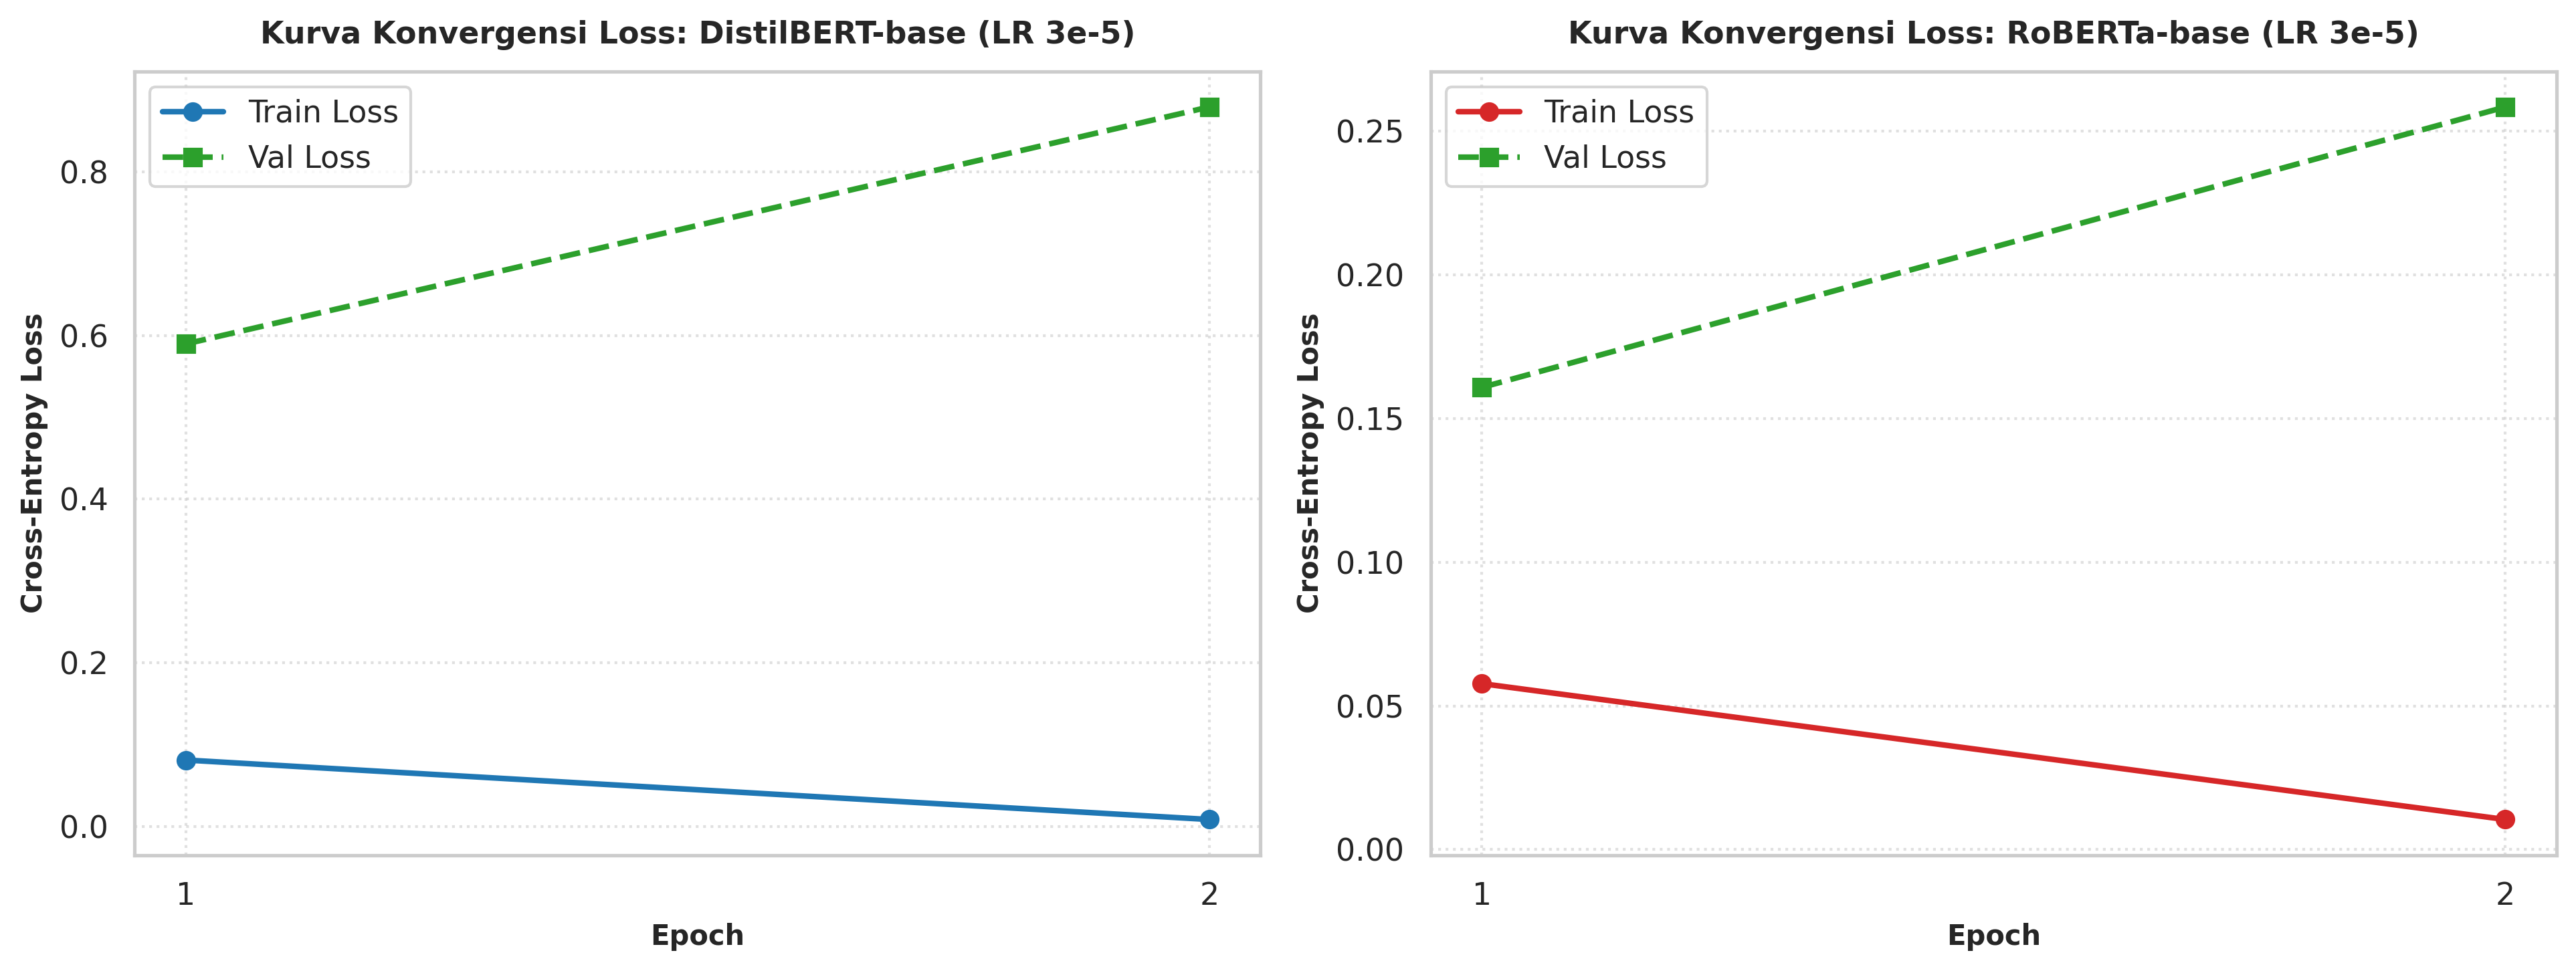

✅ Plot 1 tersimpan ke: /content/drive/MyDrive/Skripsi/results/lr3e5_01_training_curves.png


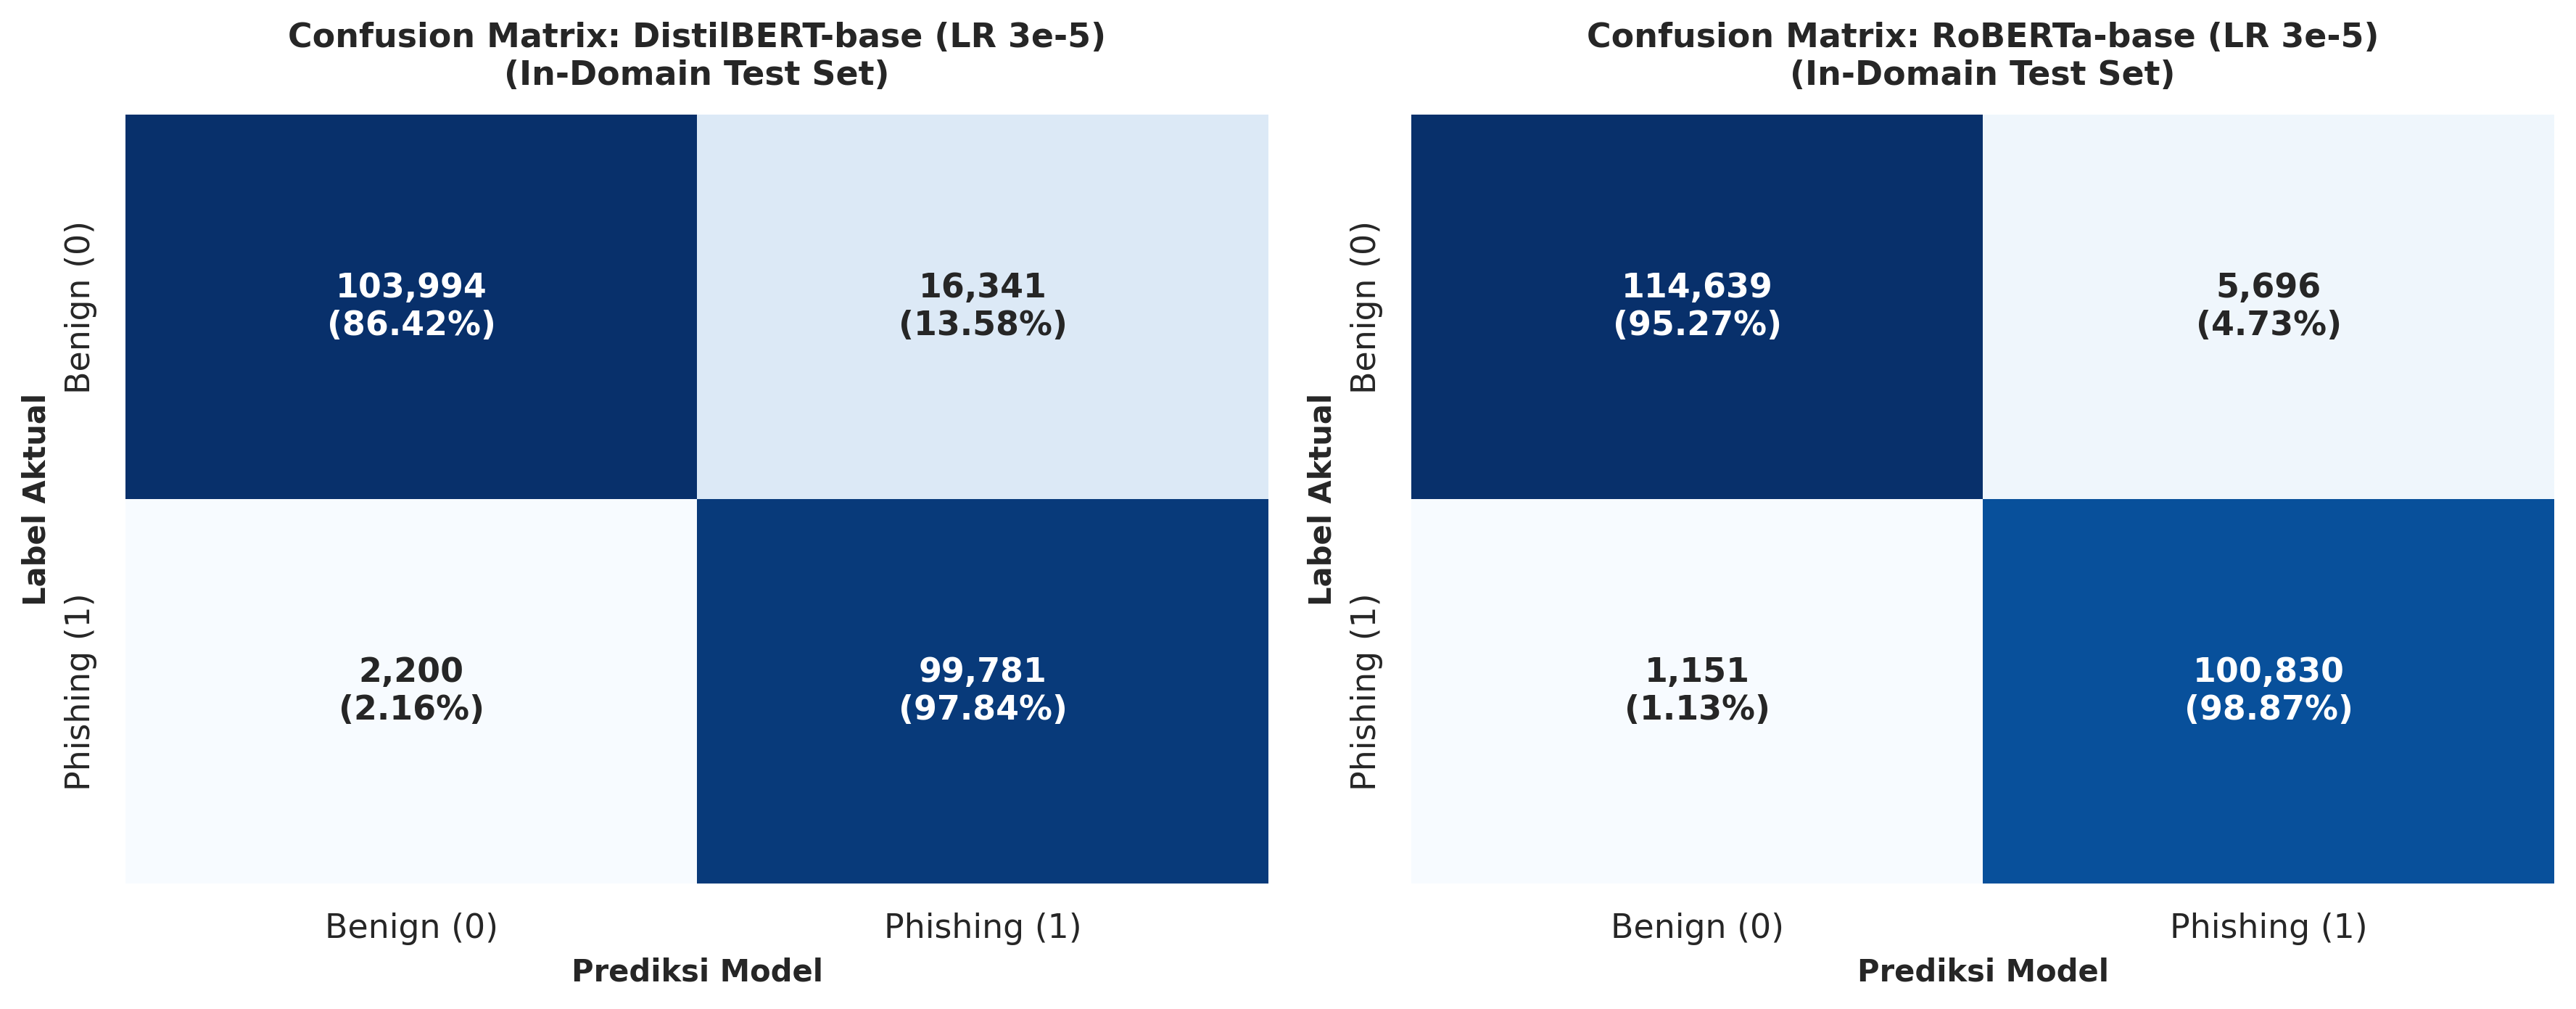

✅ Plot 2 tersimpan ke: /content/drive/MyDrive/Skripsi/results/lr3e5_02_indomain_confusion_matrices.png


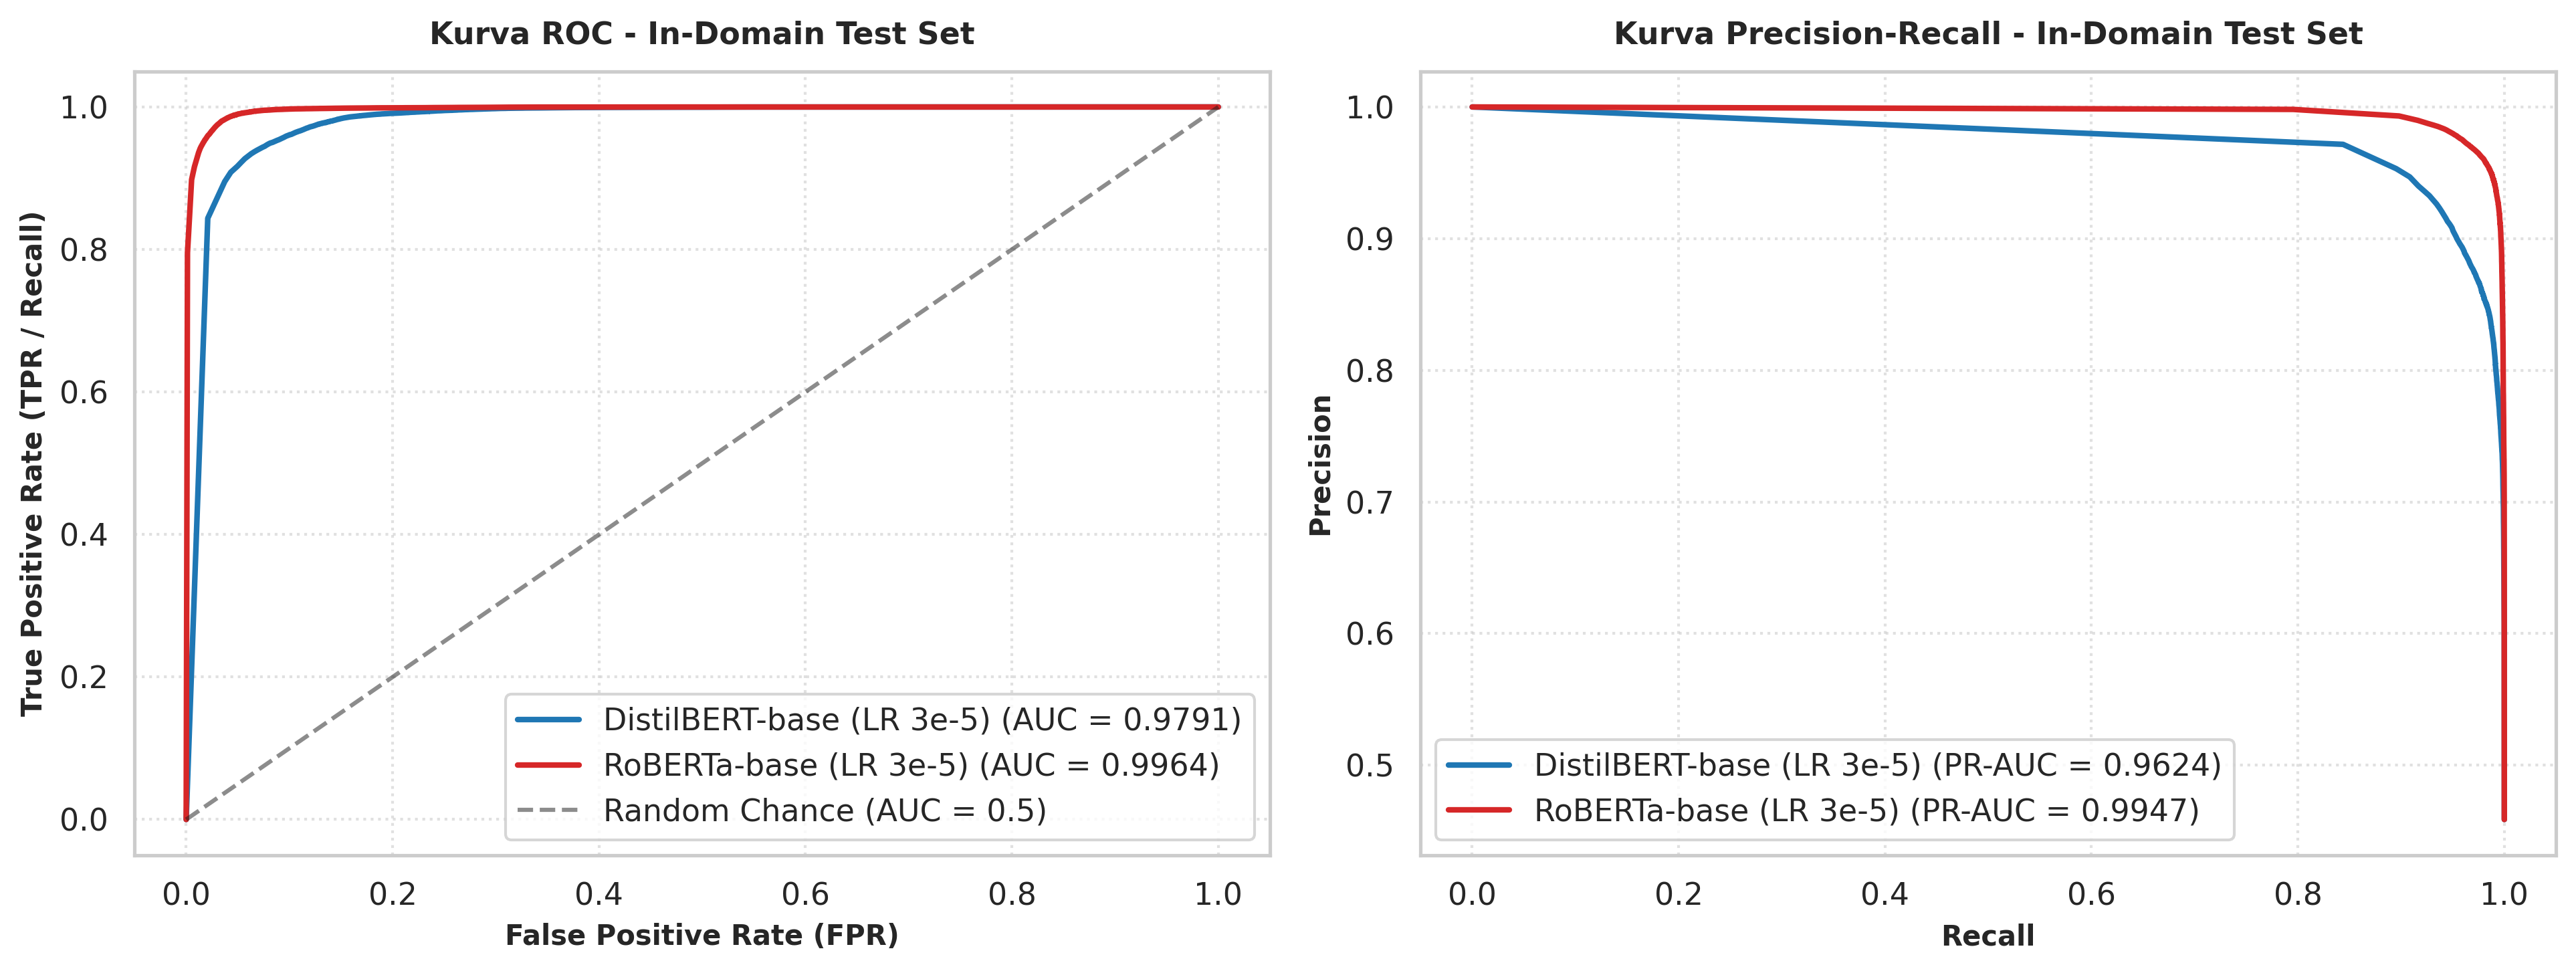

✅ Plot 3 tersimpan ke: /content/drive/MyDrive/Skripsi/results/lr3e5_03_indomain_roc_pr_curves.png


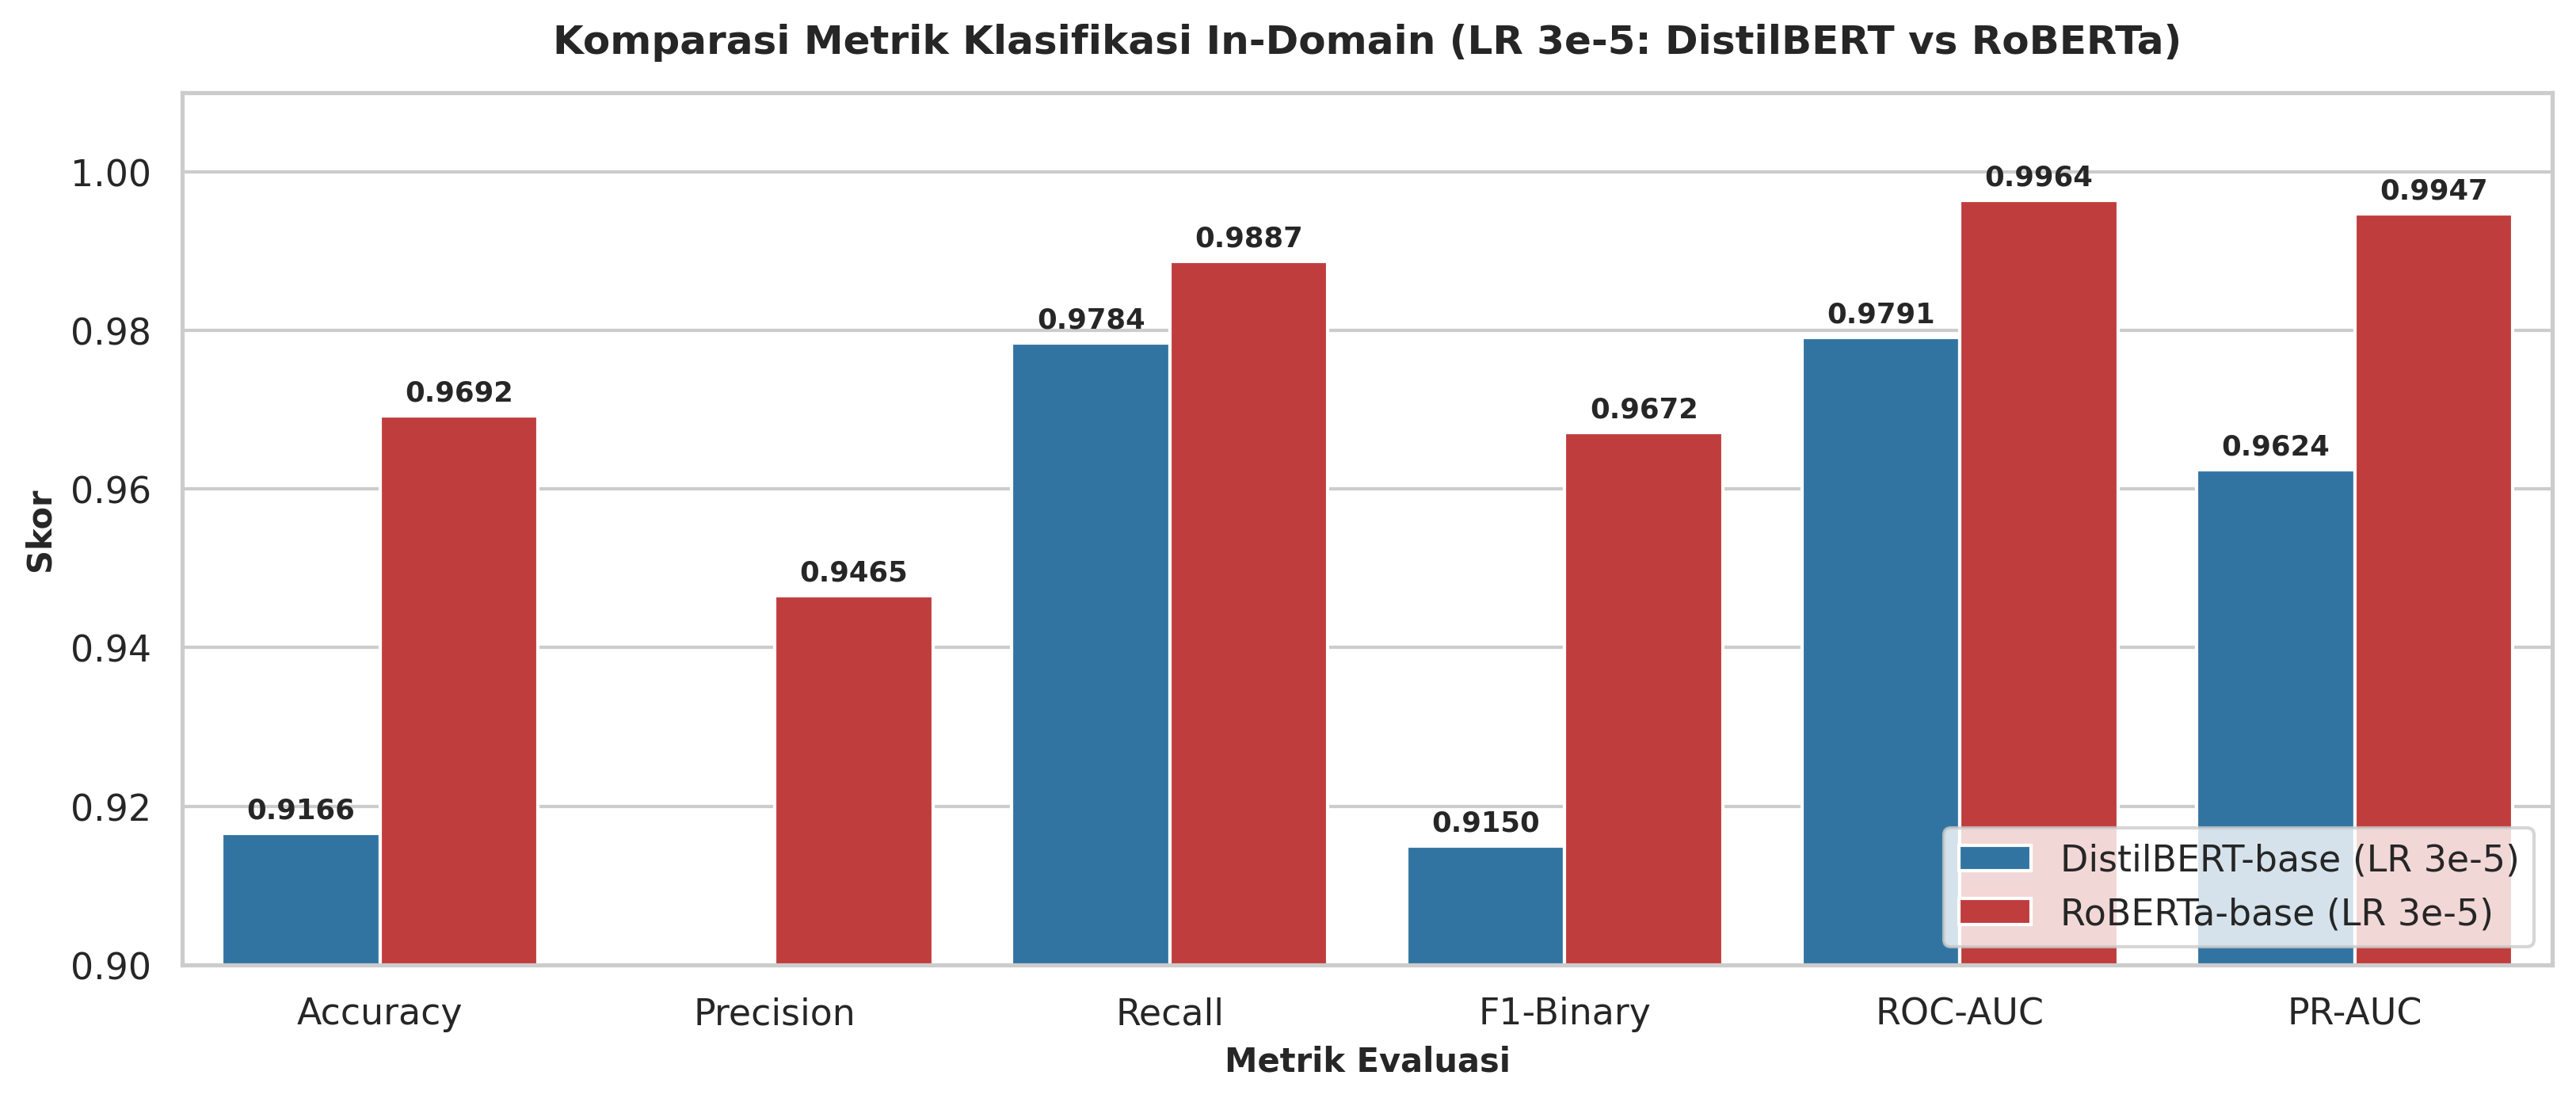

✅ Plot 4 tersimpan ke: /content/drive/MyDrive/Skripsi/results/lr3e5_04_indomain_metrics_barchart.png


In [11]:
print("[INFO] Membuat visualisasi in-domain 300 DPI (Kurva Loss, Confusion Matrix, ROC-PR, Bar Chart)...")

# ---------------------------------------------------------------------
# PLOT 1: Kurva Loss Pelatihan vs Validasi per Epoch
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=300)
models_list = ['DistilBERT-base (LR 3e-5)', 'RoBERTa-base (LR 3e-5)']
colors = ['#1f77b4', '#d62728']

for ax, m_name, col in zip(axes, models_list, colors):
    hist = indomain_predictions[m_name]['history']
    eps = hist['epochs']
    ax.plot(eps, hist['train_loss'], marker='o', color=col, linewidth=2, label='Train Loss')
    ax.plot(eps, hist['val_loss'], marker='s', color='#2ca02c', linewidth=2, linestyle='--', label='Val Loss')
    ax.set_title(f"Kurva Konvergensi Loss: {m_name}", fontsize=11, fontweight='bold', pad=10)
    ax.set_xlabel("Epoch", fontsize=10, fontweight='bold')
    ax.set_ylabel("Cross-Entropy Loss", fontsize=10, fontweight='bold')
    ax.set_xticks(eps)
    ax.legend(frameon=True)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
p1_path = os.path.join(RESULTS_DIR, "lr3e5_01_training_curves.png")
plt.savefig(p1_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Plot 1 tersimpan ke: {p1_path}")

# ---------------------------------------------------------------------
# PLOT 2: Confusion Matrix Berdampingan (Angka + Persentase Baris)
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), dpi=300)
for ax, m_name in zip(axes, models_list):
    y_t = indomain_predictions[m_name]['y_true']
    y_p = indomain_predictions[m_name]['y_pred']
    cm = confusion_matrix(y_t, y_p)
    cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

    annot = np.empty_like(cm, dtype=object)
    for i in range(2):
        for j in range(2):
            annot[i, j] = f"{cm[i, j]:,}\n({cm_pct[i, j]:.2f}%)"

    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Benign (0)', 'Phishing (1)'],
                yticklabels=['Benign (0)', 'Phishing (1)'],
                annot_kws={'fontsize': 11, 'fontweight': 'bold'})
    ax.set_title(f"Confusion Matrix: {m_name}\n(In-Domain Test Set)", fontsize=11, fontweight='bold', pad=10)
    ax.set_xlabel("Prediksi Model", fontsize=10, fontweight='bold')
    ax.set_ylabel("Label Aktual", fontsize=10, fontweight='bold')

plt.tight_layout()
p2_path = os.path.join(RESULTS_DIR, "lr3e5_02_indomain_confusion_matrices.png")
plt.savefig(p2_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Plot 2 tersimpan ke: {p2_path}")

# ---------------------------------------------------------------------
# PLOT 3: Kurva ROC & Precision-Recall Berdampingan
# ---------------------------------------------------------------------
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

palette = {'DistilBERT-base (LR 3e-5)': '#1f77b4', 'RoBERTa-base (LR 3e-5)': '#d62728'}

for m_name in models_list:
    y_t = indomain_predictions[m_name]['y_true']
    y_pr = indomain_predictions[m_name]['y_prob']

    # ROC
    fpr, tpr, _ = roc_curve(y_t, y_pr)
    auc_v = roc_auc_score(y_t, y_pr)
    ax_roc.plot(fpr, tpr, label=f"{m_name} (AUC = {auc_v:.4f})", color=palette[m_name], linewidth=2)

    # PR
    prec_arr, rec_arr, _ = precision_recall_curve(y_t, y_pr)
    pr_auc_v = average_precision_score(y_t, y_pr)
    ax_pr.plot(rec_arr, prec_arr, label=f"{m_name} (PR-AUC = {pr_auc_v:.4f})", color=palette[m_name], linewidth=2)

ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance (AUC = 0.5)')
ax_roc.set_title("Kurva ROC - In-Domain Test Set", fontsize=11, fontweight='bold', pad=10)
ax_roc.set_xlabel("False Positive Rate (FPR)", fontsize=10, fontweight='bold')
ax_roc.set_ylabel("True Positive Rate (TPR / Recall)", fontsize=10, fontweight='bold')
ax_roc.legend(loc='lower right', frameon=True)
ax_roc.grid(True, linestyle=':', alpha=0.6)

ax_pr.set_title("Kurva Precision-Recall - In-Domain Test Set", fontsize=11, fontweight='bold', pad=10)
ax_pr.set_xlabel("Recall", fontsize=10, fontweight='bold')
ax_pr.set_ylabel("Precision", fontsize=10, fontweight='bold')
ax_pr.legend(loc='lower left', frameon=True)
ax_pr.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
p3_path = os.path.join(RESULTS_DIR, "lr3e5_03_indomain_roc_pr_curves.png")
plt.savefig(p3_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Plot 3 tersimpan ke: {p3_path}")

# ---------------------------------------------------------------------
# PLOT 4: Bar Chart Perbandingan Metrik Utama In-Domain
# ---------------------------------------------------------------------
metrics_to_plot = ['accuracy', 'precision', 'recall', 'f1_binary', 'roc_auc', 'pr_auc']
metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Binary', 'ROC-AUC', 'PR-AUC']

plot_df = df_indomain_new.melt(
    id_vars=['model'],
    value_vars=metrics_to_plot,
    var_name='metric',
    value_name='score'
)
plot_df['metric'] = plot_df['metric'].map(dict(zip(metrics_to_plot, metric_labels)))

plt.figure(figsize=(11, 4.8), dpi=300)
ax = sns.barplot(data=plot_df, x='metric', y='score', hue='model', palette=['#1f77b4', '#d62728'])
plt.title("Komparasi Metrik Klasifikasi In-Domain (LR 3e-5: DistilBERT vs RoBERTa)", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Metrik Evaluasi", fontsize=10, fontweight='bold')
plt.ylabel("Skor", fontsize=10, fontweight='bold')
plt.ylim(0.90, 1.01)

# Anotasi angka di atas bar
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.4f}", (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=8.5, xytext=(0, 3),
                    textcoords='offset points', fontweight='semibold')

plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
p4_path = os.path.join(RESULTS_DIR, "lr3e5_04_indomain_metrics_barchart.png")
plt.savefig(p4_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Plot 4 tersimpan ke: {p4_path}")


## 8. Analisis Komparatif In-Domain (LR 3e-5 Baru vs LR 2e-5 Lama)

Pada bagian ini, hasil pelatihan In-Domain model baru (`LR 3e-5`) dibandingkan secara langsung dengan hasil historis model lama (`LR 2e-5`) yang tersimpan di `OLD_INDOMAIN_RESULTS` (`transformer_training_results.csv`).
- **DistilBERT**: Dibandingkan terhadap **DistilBERT (Seed 42)** model lama.
- **RoBERTa**: Dibandingkan terhadap **RoBERTa-base (Seed 42)** model lama.
- **Kaidah Status Delta** (Ambang Batas $\pm 0.005$):
  - $\Delta > +0.005$: status **⬆️ Meningkat** (hijau)
  - $\Delta < -0.005$: status **⬇️ Menurun** (merah)
  - $-0.005 \le \Delta \le +0.005$: status **➖ Stabil** (kuning/netral)


In [12]:
print("======================================================================")
print("🔍 KOMPARASI IN-DOMAIN: LR 3e-5 (BARU) VS LR 2e-5 (LAMA)")
print("======================================================================")

if not os.path.exists(OLD_INDOMAIN_RESULTS):
    raise FileNotFoundError(f"❌ File hasil in-domain lama tidak ditemukan: {OLD_INDOMAIN_RESULTS}")

df_indomain_old = pd.read_csv(OLD_INDOMAIN_RESULTS)
print(f"[OK] Memuat hasil in-domain lama dari: {OLD_INDOMAIN_RESULTS}")
print(f"     Kolom tersedia: {list(df_indomain_old.columns)}")

# [DIUBAH] Ekstraksi 3 seed DistilBERT lama (42, 123, 999) dan RoBERTa-base
distil_old_rows = df_indomain_old[df_indomain_old['model'].astype(str).str.contains('distilbert', case=False, na=False)] # [DIUBAH]
if 'seed' in distil_old_rows.columns: # [DIUBAH]
    distil_s42_row = distil_old_rows[distil_old_rows['seed'] == 42].iloc[0] if 42 in distil_old_rows['seed'].values else distil_old_rows.iloc[0] # [DIUBAH]
else: # [DIUBAH]
    distil_s42_row = distil_old_rows.iloc[0] # [DIUBAH]

roberta_old_sub = df_indomain_old[df_indomain_old['model'].astype(str).str.contains('roberta', case=False, na=False)] # [DIUBAH]
roberta_old_row = roberta_old_sub.iloc[0] # [DIUBAH]

print(f"[OK] DistilBERT lama (Seed 42) : model={distil_s42_row.get('model', 'DistilBERT')} | total seed={len(distil_old_rows)}") # [DIUBAH]
print(f"[OK] RoBERTa-base lama         : model={roberta_old_row.get('model', 'RoBERTa')}") # [DIUBAH]

comparison_records = []
target_models_map = [
    ("DistilBERT-base", "DistilBERT-base (LR 3e-5)", distil_s42_row, distil_old_rows), # [DIUBAH]
    ("RoBERTa-base", "RoBERTa-base (LR 3e-5)", roberta_old_row, None) # [DIUBAH]
]

for base_label, new_model_name, s42_row, all_old_rows in target_models_map:
    new_sub = df_indomain_new[df_indomain_new['model'] == new_model_name]
    if new_sub.empty:
        continue
    new_row = new_sub.iloc[0]

    for m_col, m_label in [('accuracy', 'Accuracy'), ('f1_binary', 'F1-Score (Binary)'), ('roc_auc', 'ROC-AUC')]:
        val_new = float(new_row[m_col])
        val_s42 = float(s42_row[m_col])
        delta = val_new - val_s42

        # [DIUBAH] Tampilkan min dan max ketiga seed untuk DistilBERT
        if all_old_rows is not None and m_col in all_old_rows.columns: # [DIUBAH]
            val_min = float(all_old_rows[m_col].min()) # [DIUBAH]
            val_max = float(all_old_rows[m_col].max()) # [DIUBAH]
            min_max_str = f"[{val_min:.4f}, {val_max:.4f}]" # [DIUBAH]
        else: # [DIUBAH]
            val_min = val_s42 # [DIUBAH]
            val_max = val_s42 # [DIUBAH]
            min_max_str = "-" # [DIUBAH]

        if delta > 0.005:
            status = "⬆️ Meningkat"
        elif delta < -0.005:
            status = "⬇️ Menurun"
        else:
            status = "➖ Stabil"

        comparison_records.append({ # [DIUBAH]
            'Arsitektur': base_label, # [DIUBAH]
            'Metrik': m_label, # [DIUBAH]
            'Lama (Seed 42)': round(val_s42, 4), # [DIUBAH]
            'Lama (Min - Max 3 Seed)': min_max_str, # [DIUBAH]
            'Baru (LR 3e-5)': round(val_new, 4), # [DIUBAH]
            'Delta (vs Seed 42)': round(delta, 4), # [DIUBAH]
            'Status Perubahan': status # [DIUBAH]
        }) # [DIUBAH]

df_comp_indomain = pd.DataFrame(comparison_records)

# [DIUBAH] Styler dengan urutan aman: Menurun dicek pertama (merah), Meningkat kedua (hijau)
def style_delta_indomain(val): # [DIUBAH]
    if isinstance(val, str): # [DIUBAH]
        if "Menurun" in val: # [DIUBAH]
            return 'background-color: #f8d7da; color: #721c24; font-weight: bold;' # [DIUBAH]
        elif "Meningkat" in val: # [DIUBAH]
            return 'background-color: #d4edda; color: #155724; font-weight: bold;' # [DIUBAH]
        elif "Stabil" in val: # [DIUBAH]
            return 'background-color: #fff3cd; color: #856404; font-weight: bold;' # [DIUBAH]
    elif isinstance(val, (int, float)): # [DIUBAH]
        if val < -0.005: # [DIUBAH]
            return 'color: #721c24; font-weight: bold;' # [DIUBAH]
        elif val > 0.005: # [DIUBAH]
            return 'color: #155724; font-weight: bold;' # [DIUBAH]
        else: # [DIUBAH]
            return 'color: #856404;' # [DIUBAH]
    return '' # [DIUBAH]

# [DIUBAH] Pemanggilan Styler yang kompatibel: pakai .map jika ada, fallback ke .applymap
styler_comp = df_comp_indomain.style # [DIUBAH]
styled_comp = ( # [DIUBAH]
    styler_comp.map(style_delta_indomain, subset=['Delta (vs Seed 42)', 'Status Perubahan']) # [DIUBAH]
    if hasattr(styler_comp, 'map') # [DIUBAH] Pandas >= 2.1.0
    else styler_comp.applymap(style_delta_indomain, subset=['Delta (vs Seed 42)', 'Status Perubahan']) # [DIUBAH]
)
display(styled_comp)

print("\n📝 Ringkasan Komparasi In-Domain:")
for _, r in df_comp_indomain.iterrows():
    seed_info = f" [Rentang 3 Seed: {r['Lama (Min - Max 3 Seed)']}]" if r['Lama (Min - Max 3 Seed)'] != '-' else ''
    print(f" - [{r['Arsitektur']}] {r['Metrik']:<20}: Seed 42 = {r['Lama (Seed 42)']:.4f}{seed_info} -> Baru = {r['Baru (LR 3e-5)']:.4f} (Delta: {r['Delta (vs Seed 42)']:+.4f}) [{r['Status Perubahan']}]")


🔍 KOMPARASI IN-DOMAIN: LR 3e-5 (BARU) VS LR 2e-5 (LAMA)
[OK] Memuat hasil in-domain lama dari: /content/drive/MyDrive/Skripsi/results/transformer_training_results.csv
     Kolom tersedia: ['model', 'seed', 'accuracy', 'precision', 'recall', 'f1_binary', 'f1_macro', 'roc_auc', 'pr_auc', 'training_time_s', 'peak_vram_gb', 'latency_ms', 'throughput_sps']
[OK] DistilBERT lama (Seed 42) : model=DistilBERT-base | total seed=3
[OK] RoBERTa-base lama         : model=RoBERTa-base


,Arsitektur,Metrik,Lama (Seed 42),Lama (Min - Max 3 Seed),Baru (LR 3e-5),Delta (vs Seed 42),Status Perubahan
0,DistilBERT-base,Accuracy,0.923800,"[0.9117, 0.9238]",0.916600,-0.007200,⬇️ Menurun
1,DistilBERT-base,F1-Score (Binary),0.921500,"[0.9106, 0.9215]",0.915000,-0.006500,⬇️ Menurun
2,DistilBERT-base,ROC-AUC,0.980600,"[0.9769, 0.9861]",0.979100,-0.001500,➖ Stabil
3,RoBERTa-base,Accuracy,0.972200,-,0.969200,-0.003000,➖ Stabil
4,RoBERTa-base,F1-Score (Binary),0.970100,-,0.967200,-0.003000,➖ Stabil
5,RoBERTa-base,ROC-AUC,0.995200,-,0.996400,0.001200,➖ Stabil



📝 Ringkasan Komparasi In-Domain:
 - [DistilBERT-base] Accuracy            : Seed 42 = 0.9238 [Rentang 3 Seed: [0.9117, 0.9238]] -> Baru = 0.9166 (Delta: -0.0072) [⬇️ Menurun]
 - [DistilBERT-base] F1-Score (Binary)   : Seed 42 = 0.9215 [Rentang 3 Seed: [0.9106, 0.9215]] -> Baru = 0.9150 (Delta: -0.0065) [⬇️ Menurun]
 - [DistilBERT-base] ROC-AUC             : Seed 42 = 0.9806 [Rentang 3 Seed: [0.9769, 0.9861]] -> Baru = 0.9791 (Delta: -0.0015) [➖ Stabil]
 - [RoBERTa-base] Accuracy            : Seed 42 = 0.9722 -> Baru = 0.9692 (Delta: -0.0030) [➖ Stabil]
 - [RoBERTa-base] F1-Score (Binary)   : Seed 42 = 0.9701 -> Baru = 0.9672 (Delta: -0.0030) [➖ Stabil]
 - [RoBERTa-base] ROC-AUC             : Seed 42 = 0.9952 -> Baru = 0.9964 (Delta: +0.0012) [➖ Stabil]


## 9. Pengujian Generalisasi Dataset Eksternal 2: Pemuatan Model & Protokol Zero-Leak

Tahap akhir adalah menguji kedua checkpoint model baru (`LR 3e-5`) pada dataset independen dunia nyata **External 2** (`external2_clean.csv`).
- **Verifikasi Anti-Bocor (*Zero-Leak Protocol*)**: Memastikan secara komputasional bahwa tidak ada URL di dataset eksternal yang pernah muncul pada data latih (*Train*), validasi (*Val*), maupun uji (*Test*), label berupa biner murni {0, 1}, dan tidak ada URL duplikat.
- **Proteksi Out-of-Vocab (OOV)**: Menggunakan kelas `EvalURLDataset` yang memetakan setiap `input_id >= vocab_size` ke `unk_token_id` untuk mencegah *index out of bounds* pada tokenizer kustom.


In [13]:
# ======================================================================
# 1. PEMUATAN DATASET EKSTERNAL 2 BERSIH & VERIFIKASI ZERO-LEAK
# ======================================================================
print("======================================================================")
print("🛡️ PROTOKOL VERIFIKASI ZERO-LEAK DATASET EKSTERNAL 2")
print("======================================================================")

if not os.path.exists(EXTERNAL2_CLEAN_CSV):
    raise FileNotFoundError(
        f"❌ Jalankan dulu notebook 06 versi terbaru (dataset url_features_extracted1.csv) agar file ini terbentuk.\n"
        f"Path: {EXTERNAL2_CLEAN_CSV}"
    )

print(f"[INFO] Membaca dataset External 2 bersih dari: {EXTERNAL2_CLEAN_CSV}...")
df_ext2 = pd.read_csv(EXTERNAL2_CLEAN_CSV)
print(f"[OK] Berhasil memuat {len(df_ext2):,} baris sampel.")
print(f"     Kolom tersedia: {list(df_ext2.columns)}")

# [DIUBAH] Guard Dataset: Pemeriksaan keberadaan kolom metadata wajib external2_clean.csv
for req_col in ['has_ip_address', 'suspicious_file_extension']: # [DIUBAH]
    if req_col not in df_ext2.columns: # [DIUBAH]
        raise KeyError( # [DIUBAH]
            f"❌ Kolom '{req_col}' tidak ditemukan di {EXTERNAL2_CLEAN_CSV}!\n" # [DIUBAH]
            f"external2_clean.csv kemungkinan versi lama; jalankan ulang notebook 06 terbaru." # [DIUBAH]
        ) # [DIUBAH]
print("✅ [PASS] Kolom metadata wajib 'has_ip_address' dan 'suspicious_file_extension' terverifikasi ada.") # [DIUBAH]

# [DIUBAH] Pemeriksaan jumlah baris dataset External 2
n_ext2_rows = len(df_ext2) # [DIUBAH]
print(f"[INFO] Jumlah baris terdeteksi: {n_ext2_rows:,}") # [DIUBAH]
if n_ext2_rows == 45430: # [DIUBAH]
    print(f"⚠️ [PERINGATAN] Jumlah baris ({n_ext2_rows:,}) SAMA PERSIS dengan jumlah dataset lama (45,430)!") # [DIUBAH]
    print("   Pastikan file ini berasal dari dataset url_features_extracted1.csv terbaru, bukan run dataset lama.") # [DIUBAH]

# Bangun kolom url_spaced jika belum ada
if 'url_spaced' not in df_ext2.columns:
    print("[INFO] Kolom 'url_spaced' belum ada di external2. Membangun dari url_norm...")
    df_ext2['url_spaced'] = df_ext2['url_norm'].apply(preprocess_delimiter_spacing)

# 2. Himpunan URL Historis In-Domain
train_urls = set(train_df['url_norm'].dropna().astype(str).str.strip().tolist())
val_urls   = set(val_df['url_norm'].dropna().astype(str).str.strip().tolist())
test_urls  = set(test_df['url_norm'].dropna().astype(str).str.strip().tolist())
ext2_urls  = set(df_ext2['url_norm'].dropna().astype(str).str.strip().tolist())

# Eksekusi Asersi Zero-Leak
leak_train = ext2_urls.intersection(train_urls)
leak_val   = ext2_urls.intersection(val_urls)
leak_test  = ext2_urls.intersection(test_urls)

assert len(leak_train) == 0, f"❌ Terjadi kebocoran data! Ditemukan {len(leak_train)} URL overlap dengan Train Set."
assert len(leak_val) == 0,   f"❌ Terjadi kebocoran data! Ditemukan {len(leak_val)} URL overlap dengan Val Set."
assert len(leak_test) == 0,  f"❌ Terjadi kebocoran data! Ditemukan {len(leak_test)} URL overlap dengan Test Set."
assert set(df_ext2['label'].unique()).issubset({0, 1}), f"❌ Label tidak valid: {df_ext2['label'].unique()}"
assert df_ext2['url_norm'].duplicated().sum() == 0, f"❌ Ditemukan {df_ext2['url_norm'].duplicated().sum()} URL duplikat!"

print("✅ [PASS] Asersi Zero-Leak Berhasil: 0% data overlap dengan data in-domain.")
print("✅ [PASS] Asersi Validitas Label: Label biner murni {0, 1}.")
print("✅ [PASS] Asersi Deduplikasi: Tidak ada URL duplikat pada External 2.")

# Cetak Distribusi Sampel
n_ext2_total = len(df_ext2)
n_benign = (df_ext2['label'] == 0).sum()
n_phish = (df_ext2['label'] == 1).sum()
print(f"\n📊 DISTRIBUSI KELAS DATASET EKSTERNAL 2:")
print(f"   - Total Sampel      : {n_ext2_total:,} URL")
print(f"   - Benign (0)        : {n_benign:,} ({n_benign/n_ext2_total*100:.2f}%)")
print(f"   - Phishing/Mal (1)  : {n_phish:,} ({n_phish/n_ext2_total*100:.2f}%)")

# ======================================================================
# 2. DEFINISI EVAL DATASET DENGAN PROTEKSI OUT-OF-VOCAB (OOV)
# ======================================================================
class EvalURLDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=128, vocab_size=None):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.vocab_size = vocab_size
        self.unk_id = tokenizer.unk_token_id if tokenizer.unk_token_id is not None else 0

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = self.labels[idx]
        encoding = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt'
        )
        input_ids = encoding['input_ids'].squeeze(0)
        # Proteksi OOV: Ganti token index >= vocab_size dengan unk_id
        if self.vocab_size is not None:
            input_ids = torch.where(
                input_ids >= self.vocab_size,
                torch.tensor(self.unk_id, dtype=torch.long),
                input_ids
            )

        attention_mask = encoding['attention_mask'].squeeze(0)
        return {
            'input_ids': input_ids,
            'attention_mask': attention_mask,
            'labels': torch.tensor(label, dtype=torch.long)
        }

print("✅ [OK] EvalURLDataset dengan proteksi OOV siap digunakan.")


🛡️ PROTOKOL VERIFIKASI ZERO-LEAK DATASET EKSTERNAL 2
[INFO] Membaca dataset External 2 bersih dari: /content/drive/MyDrive/Skripsi/data/external2/external2_clean.csv...
[OK] Berhasil memuat 96,177 baris sampel.
     Kolom tersedia: ['url', 'url_norm', 'url_spaced', 'domain_group', 'label', 'has_ip_address', 'suspicious_file_extension']
✅ [PASS] Kolom metadata wajib 'has_ip_address' dan 'suspicious_file_extension' terverifikasi ada.
[INFO] Jumlah baris terdeteksi: 96,177
✅ [PASS] Asersi Zero-Leak Berhasil: 0% data overlap dengan data in-domain.
✅ [PASS] Asersi Validitas Label: Label biner murni {0, 1}.
✅ [PASS] Asersi Deduplikasi: Tidak ada URL duplikat pada External 2.

📊 DISTRIBUSI KELAS DATASET EKSTERNAL 2:
   - Total Sampel      : 96,177 URL
   - Benign (0)        : 35,874 (37.30%)
   - Phishing/Mal (1)  : 60,303 (62.70%)
✅ [OK] EvalURLDataset dengan proteksi OOV siap digunakan.


## 10. Evaluasi Menyeluruh Dataset Eksternal 2 untuk Model Baru

Pada tahap ini dilakukan:
1. Inferensi PyTorch FP16 AMP pada seluruh sampel `external2_clean.csv`.
2. Perhitungan metrik industri siber: $TPR@FPR \le 0.1\%$, $TPR@FPR \le 1.0\%$, FPR, FNR, Expected Calibration Error (ECE 15-bin), Brier Score, Latensi inferensi, dan Throughput.
3. Ekspor artefak evaluasi CSV (`lr3e5_ext2_evaluation_results.csv`, `lr3e5_ext2_predictions.csv`, `lr3e5_ext2_error_analysis_samples.csv`).
4. Pembuatan 6 grafik komparatif standar publikasi 300 DPI.


In [14]:
# ======================================================================
# FUNGSI HELPER METRIK INDUSTRI (ECE, BRIER, TPR@LOW-FPR)
# ======================================================================
def compute_ece(y_true, y_prob, n_bins=15):
    bin_limits = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        bin_lower = bin_limits[i]
        bin_upper = bin_limits[i + 1]
        in_bin = (y_prob >= bin_lower) & (y_prob <= bin_upper) if i == n_bins - 1 else (y_prob >= bin_lower) & (y_prob < bin_upper)
        prop_in_bin = np.mean(in_bin)
        if prop_in_bin > 0:
            acc_in_bin = np.mean(y_true[in_bin])
            conf_in_bin = np.mean(y_prob[in_bin])
            ece += np.abs(conf_in_bin - acc_in_bin) * prop_in_bin
    return float(ece)

ext2_model_targets = [
    {
        'label': 'DistilBERT-base (LR 3e-5)',
        'dir': DISTIL_SAVE_DIR,
        'texts': df_ext2['url_spaced']
    },
    {
        'label': 'RoBERTa-base (LR 3e-5)',
        'dir': ROBERTA_SAVE_DIR,
        'texts': df_ext2['url_norm']
    }
]

ext2_summary_records = []
ext2_eval_predictions = {}
labels_ext2 = df_ext2['label'].values

for tgt in ext2_model_targets:
    m_lbl = tgt['label']
    m_dir = tgt['dir']
    texts_in = tgt['texts']

    print(f"\n======================================================================")
    print(f"🔍 Evaluasi External 2: {m_lbl} ({len(texts_in):,} sampel)...")
    print(f"   Checkpoint: {m_dir}")
    print(f"======================================================================")

    tok = AutoTokenizer.from_pretrained(m_dir)
    mdl = AutoModelForSequenceClassification.from_pretrained(m_dir)
    vocab_sz = getattr(mdl.config, 'vocab_size', None)
    total_params = sum(p.numel() for p in mdl.parameters())

    eval_ds = EvalURLDataset(texts_in, labels_ext2, tok, max_length=MAX_LENGTH, vocab_size=vocab_sz)
    eval_ld = DataLoader(eval_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

    mdl.eval()
    mdl.to(device)

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    # Warmup 1 batch (4 sampel) untuk stabilisasi CUDA context
    with torch.no_grad():
        for b in eval_ld:
            _ = mdl(b['input_ids'][:4].to(device), b['attention_mask'][:4].to(device))
            break

    preds_list, probs_list = [], []
    use_cuda = torch.cuda.is_available()

    t_start = time.perf_counter()
    with torch.no_grad():
        for b in eval_ld:
            inp = b['input_ids'].to(device)
            att = b['attention_mask'].to(device)

            if hasattr(torch, 'amp') and hasattr(torch.amp, 'autocast'):
                ctx = torch.amp.autocast('cuda', enabled=use_cuda)
            else:
                ctx = torch.cuda.amp.autocast(enabled=use_cuda)

            with ctx:
                out = mdl(inp, attention_mask=att)

            logits = out.logits
            probs = torch.softmax(logits, dim=-1)
            preds = torch.argmax(logits, dim=-1)

            preds_list.extend(preds.cpu().numpy())
            probs_list.extend(probs[:, 1].cpu().numpy())

    total_time = time.perf_counter() - t_start
    peak_vram = torch.cuda.max_memory_allocated() / (1024**3) if torch.cuda.is_available() else 0.0

    y_true_arr = np.array(labels_ext2)
    y_pred_arr = np.array(preds_list)
    y_prob_arr = np.array(probs_list)

    latency_ms = (total_time / len(y_true_arr)) * 1000.0
    throughput = len(y_true_arr) / max(total_time, 1e-6)

    # Bersihkan memori GPU
    del mdl
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()

    # Hitung Metrik Evaluasi
    acc = accuracy_score(y_true_arr, y_pred_arr)
    prec = precision_score(y_true_arr, y_pred_arr, zero_division=0)
    rec = recall_score(y_true_arr, y_pred_arr, zero_division=0)
    f1_bin = f1_score(y_true_arr, y_pred_arr, average='binary', zero_division=0)
    f1_mac = f1_score(y_true_arr, y_pred_arr, average='macro', zero_division=0)

    try:
        roc_auc = roc_auc_score(y_true_arr, y_prob_arr)
    except Exception:
        roc_auc = np.nan
    try:
        pr_auc = average_precision_score(y_true_arr, y_prob_arr)
    except Exception:
        pr_auc = np.nan

    cm = confusion_matrix(y_true_arr, y_pred_arr, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel() if cm.shape == (2, 2) else (0, 0, 0, 0)
    fpr_val = fp / max(fp + tn, 1)
    fnr_val = fn / max(fn + tp, 1)

    # TPR @ low FPR (<= 0.1% dan <= 1.0%)
    try:
        fpr_arr, tpr_arr, _ = roc_curve(y_true_arr, y_prob_arr)
        interp_tpr = interpolate.interp1d(fpr_arr, tpr_arr, bounds_error=False, fill_value=(0.0, 1.0))
        tpr_at_01 = float(interp_tpr(0.001))
        tpr_at_1 = float(interp_tpr(0.010))
    except Exception:
        tpr_at_01 = np.nan
        tpr_at_1 = np.nan

    ece_val = compute_ece(y_true_arr, y_prob_arr, n_bins=15)
    brier_val = float(brier_score_loss(y_true_arr, y_prob_arr))

    record = {
        'model': m_lbl,
        'accuracy': round(acc, 4),
        'precision': round(prec, 4),
        'recall': round(rec, 4),
        'f1_binary': round(f1_bin, 4),
        'f1_macro': round(f1_mac, 4),
        'roc_auc': round(roc_auc, 4) if not np.isnan(roc_auc) else np.nan,
        'pr_auc': round(pr_auc, 4) if not np.isnan(pr_auc) else np.nan,
        'tpr_at_fpr_0.1pct': round(tpr_at_01, 4) if not np.isnan(tpr_at_01) else np.nan,
        'tpr_at_fpr_1.0pct': round(tpr_at_1, 4) if not np.isnan(tpr_at_1) else np.nan,
        'fpr': round(fpr_val, 4),
        'fnr': round(fnr_val, 4),
        'ece': round(ece_val, 4),
        'brier_score': round(brier_val, 4),
        'latency_ms': round(latency_ms, 4),
        'throughput_sps': round(throughput, 1),
        'peak_vram_gb': round(peak_vram, 3),
        'total_params': total_params
    }
    ext2_summary_records.append(record)

    ext2_eval_predictions[m_lbl] = {
        'y_true': y_true_arr,
        'y_pred': y_pred_arr,
        'y_prob': y_prob_arr,
        'confusion_matrix': cm
    }

    print(f"   Accuracy            : {acc*100:.2f}%")
    print(f"   F1-Score (Binary)   : {f1_bin:.4f}")
    print(f"   Recall              : {rec:.4f}")
    print(f"   ROC-AUC             : {roc_auc:.4f}")
    print(f"   PR-AUC              : {pr_auc:.4f}")
    print(f"   TPR @ FPR <= 0.1%   : {tpr_at_01*100:.2f}%")
    print(f"   TPR @ FPR <= 1.0%   : {tpr_at_1*100:.2f}%")
    print(f"   ECE (15 Bins)       : {ece_val:.4f}")
    print(f"   Latency             : {latency_ms:.4f} ms/sampel")

# 1. Ekspor Tabel Ringkasan ke CSV
df_ext2_summary = pd.DataFrame(ext2_summary_records)
ext2_summary_csv = os.path.join(RESULTS_DIR, "lr3e5_ext2_evaluation_results.csv")
df_ext2_summary.to_csv(ext2_summary_csv, index=False)
print(f"\n✅ [SUKSES] Ringkasan metrik External 2 tersimpan ke: {ext2_summary_csv}")
display(df_ext2_summary)

# 2. Ekspor Prediksi Lengkap ke CSV
df_ext2_preds = df_ext2[['url', 'url_norm', 'label']].copy()
df_ext2_preds['pred_distilbert'] = ext2_eval_predictions['DistilBERT-base (LR 3e-5)']['y_pred']
df_ext2_preds['prob_distilbert'] = ext2_eval_predictions['DistilBERT-base (LR 3e-5)']['y_prob']
df_ext2_preds['pred_roberta']    = ext2_eval_predictions['RoBERTa-base (LR 3e-5)']['y_pred']
df_ext2_preds['prob_roberta']    = ext2_eval_predictions['RoBERTa-base (LR 3e-5)']['y_prob']

ext2_preds_csv = os.path.join(RESULTS_DIR, "lr3e5_ext2_predictions.csv")
df_ext2_preds.to_csv(ext2_preds_csv, index=False)
print(f"✅ [SUKSES] File prediksi per-URL External 2 tersimpan ke: {ext2_preds_csv}")



🔍 Evaluasi External 2: DistilBERT-base (LR 3e-5) (96,177 sampel)...
   Checkpoint: /content/drive/MyDrive/Skripsi/models/distilbert_lr3e5


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

   Accuracy            : 63.82%
   F1-Score (Binary)   : 0.7688
   Recall              : 0.9595
   ROC-AUC             : 0.7802
   PR-AUC              : 0.8378
   TPR @ FPR <= 0.1%   : 0.53%
   TPR @ FPR <= 1.0%   : 5.27%
   ECE (15 Bins)       : 0.3479
   Latency             : 0.1594 ms/sampel

🔍 Evaluasi External 2: RoBERTa-base (LR 3e-5) (96,177 sampel)...
   Checkpoint: /content/drive/MyDrive/Skripsi/models/roberta_lr3e5


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

   Accuracy            : 64.35%
   F1-Score (Binary)   : 0.7703
   Recall              : 0.9532
   ROC-AUC             : 0.9125
   PR-AUC              : 0.9556
   TPR @ FPR <= 0.1%   : 7.24%
   TPR @ FPR <= 1.0%   : 72.39%
   ECE (15 Bins)       : 0.3260
   Latency             : 0.2596 ms/sampel

✅ [SUKSES] Ringkasan metrik External 2 tersimpan ke: /content/drive/MyDrive/Skripsi/results/lr3e5_ext2_evaluation_results.csv


,model,accuracy,precision,recall,f1_binary,f1_macro,roc_auc,pr_auc,tpr_at_fpr_0.1pct,tpr_at_fpr_1.0pct,fpr,fnr,ece,brier_score,latency_ms,throughput_sps,peak_vram_gb,total_params
0,DistilBERT-base (LR 3e-5),0.6382,0.6414,0.9595,0.7688,0.4686,0.7802,0.8378,0.0053,0.0527,0.9019,0.0405,0.3479,0.3475,0.1594,6272.5,0.518,66839810
1,RoBERTa-base (LR 3e-5),0.6435,0.6463,0.9532,0.7703,0.4875,0.9125,0.9556,0.0724,0.7239,0.8769,0.0468,0.3260,0.3147,0.2596,3852.1,0.840,124647170


✅ [SUKSES] File prediksi per-URL External 2 tersimpan ke: /content/drive/MyDrive/Skripsi/results/lr3e5_ext2_predictions.csv


[INFO] Membuat 6 grafik visualisasi External 2 standar 300 DPI...


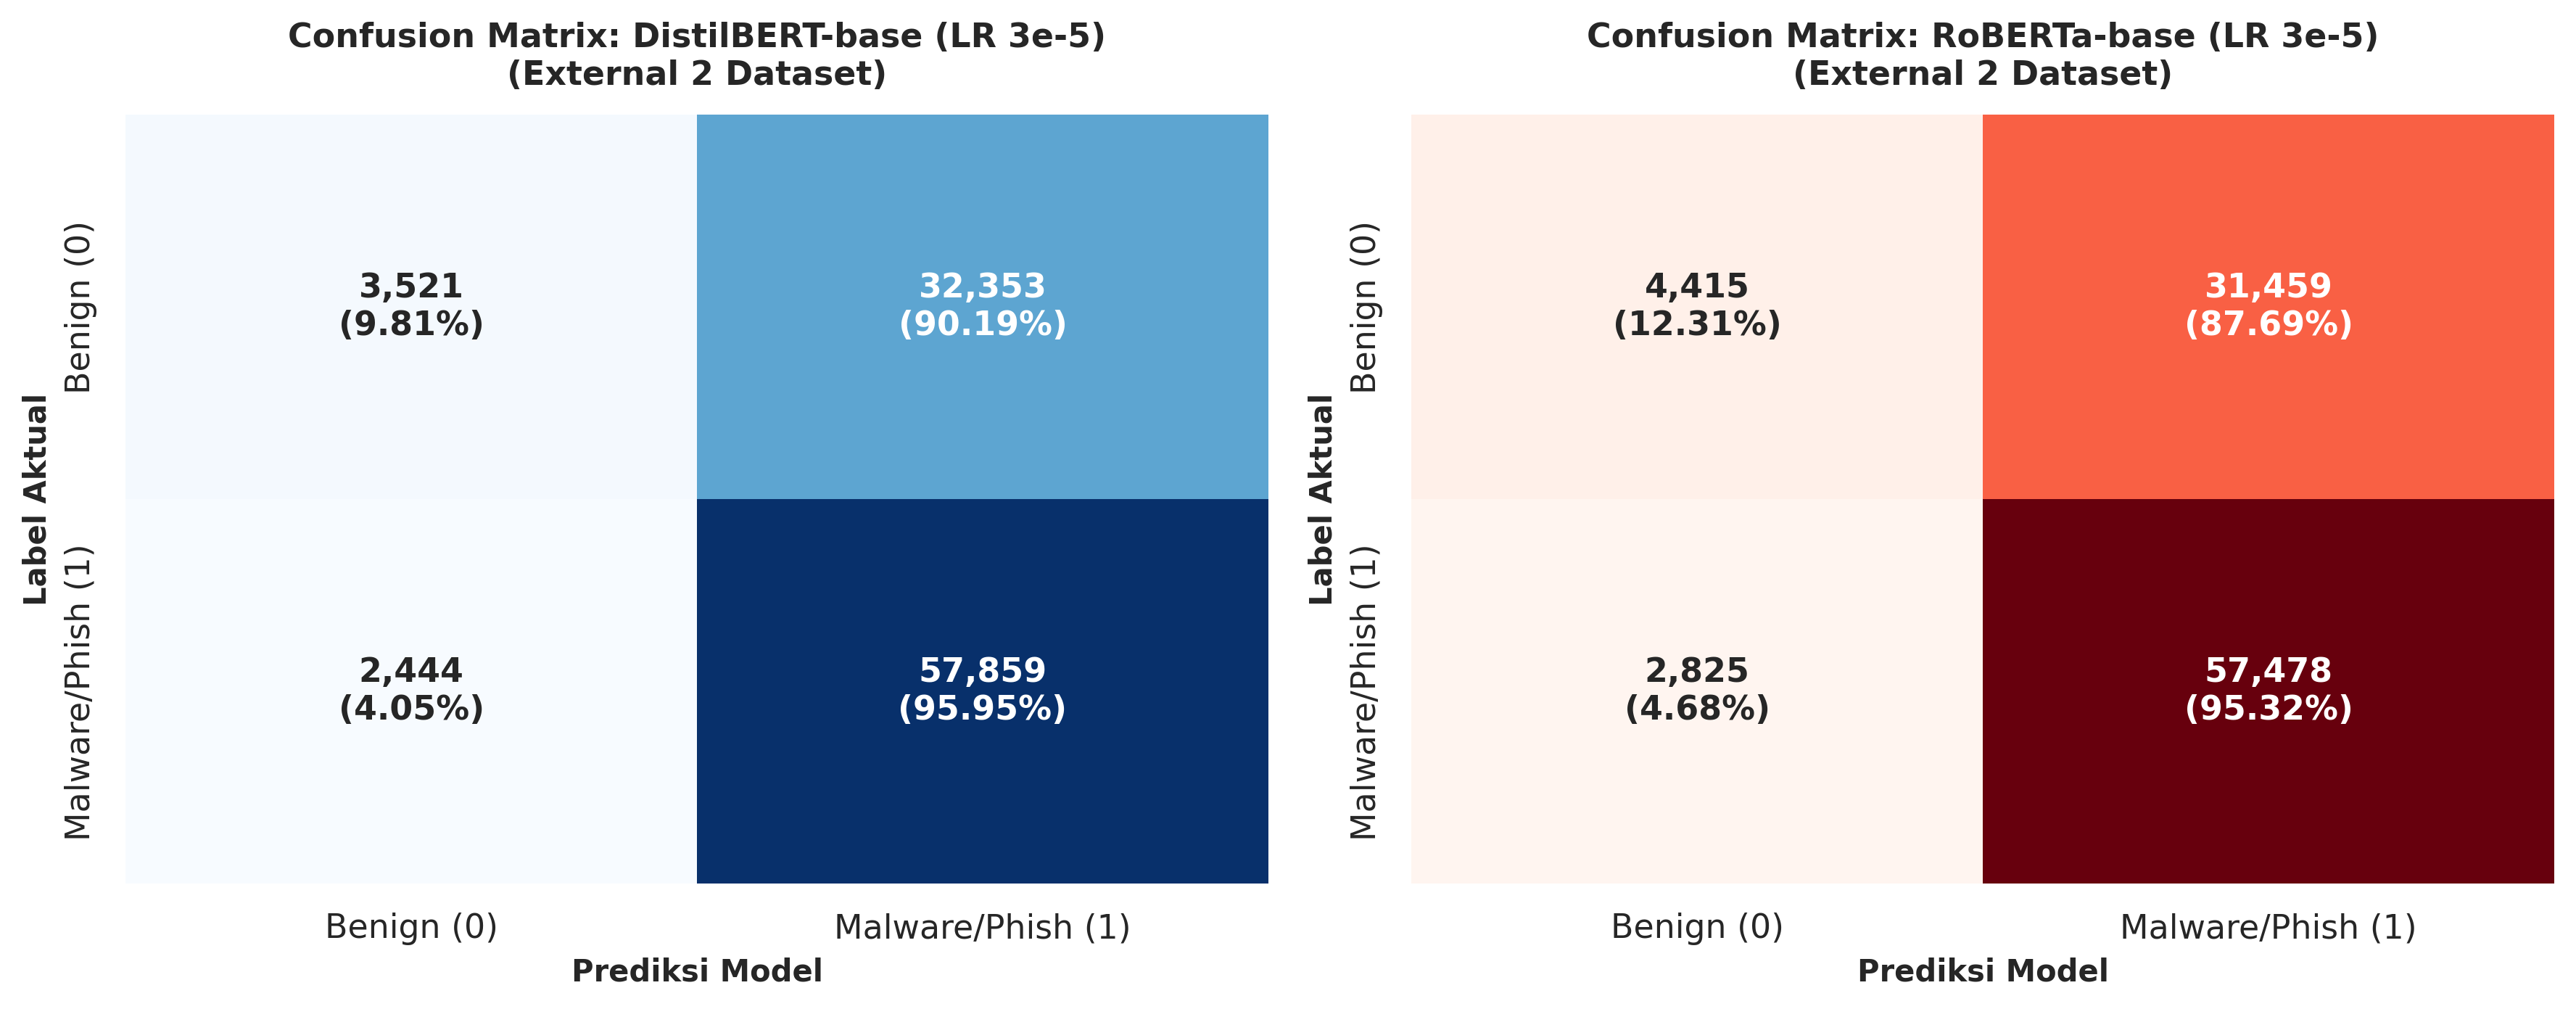

✅ Plot 1 tersimpan ke: /content/drive/MyDrive/Skripsi/results/lr3e5_ext2_01_confusion_matrices.png


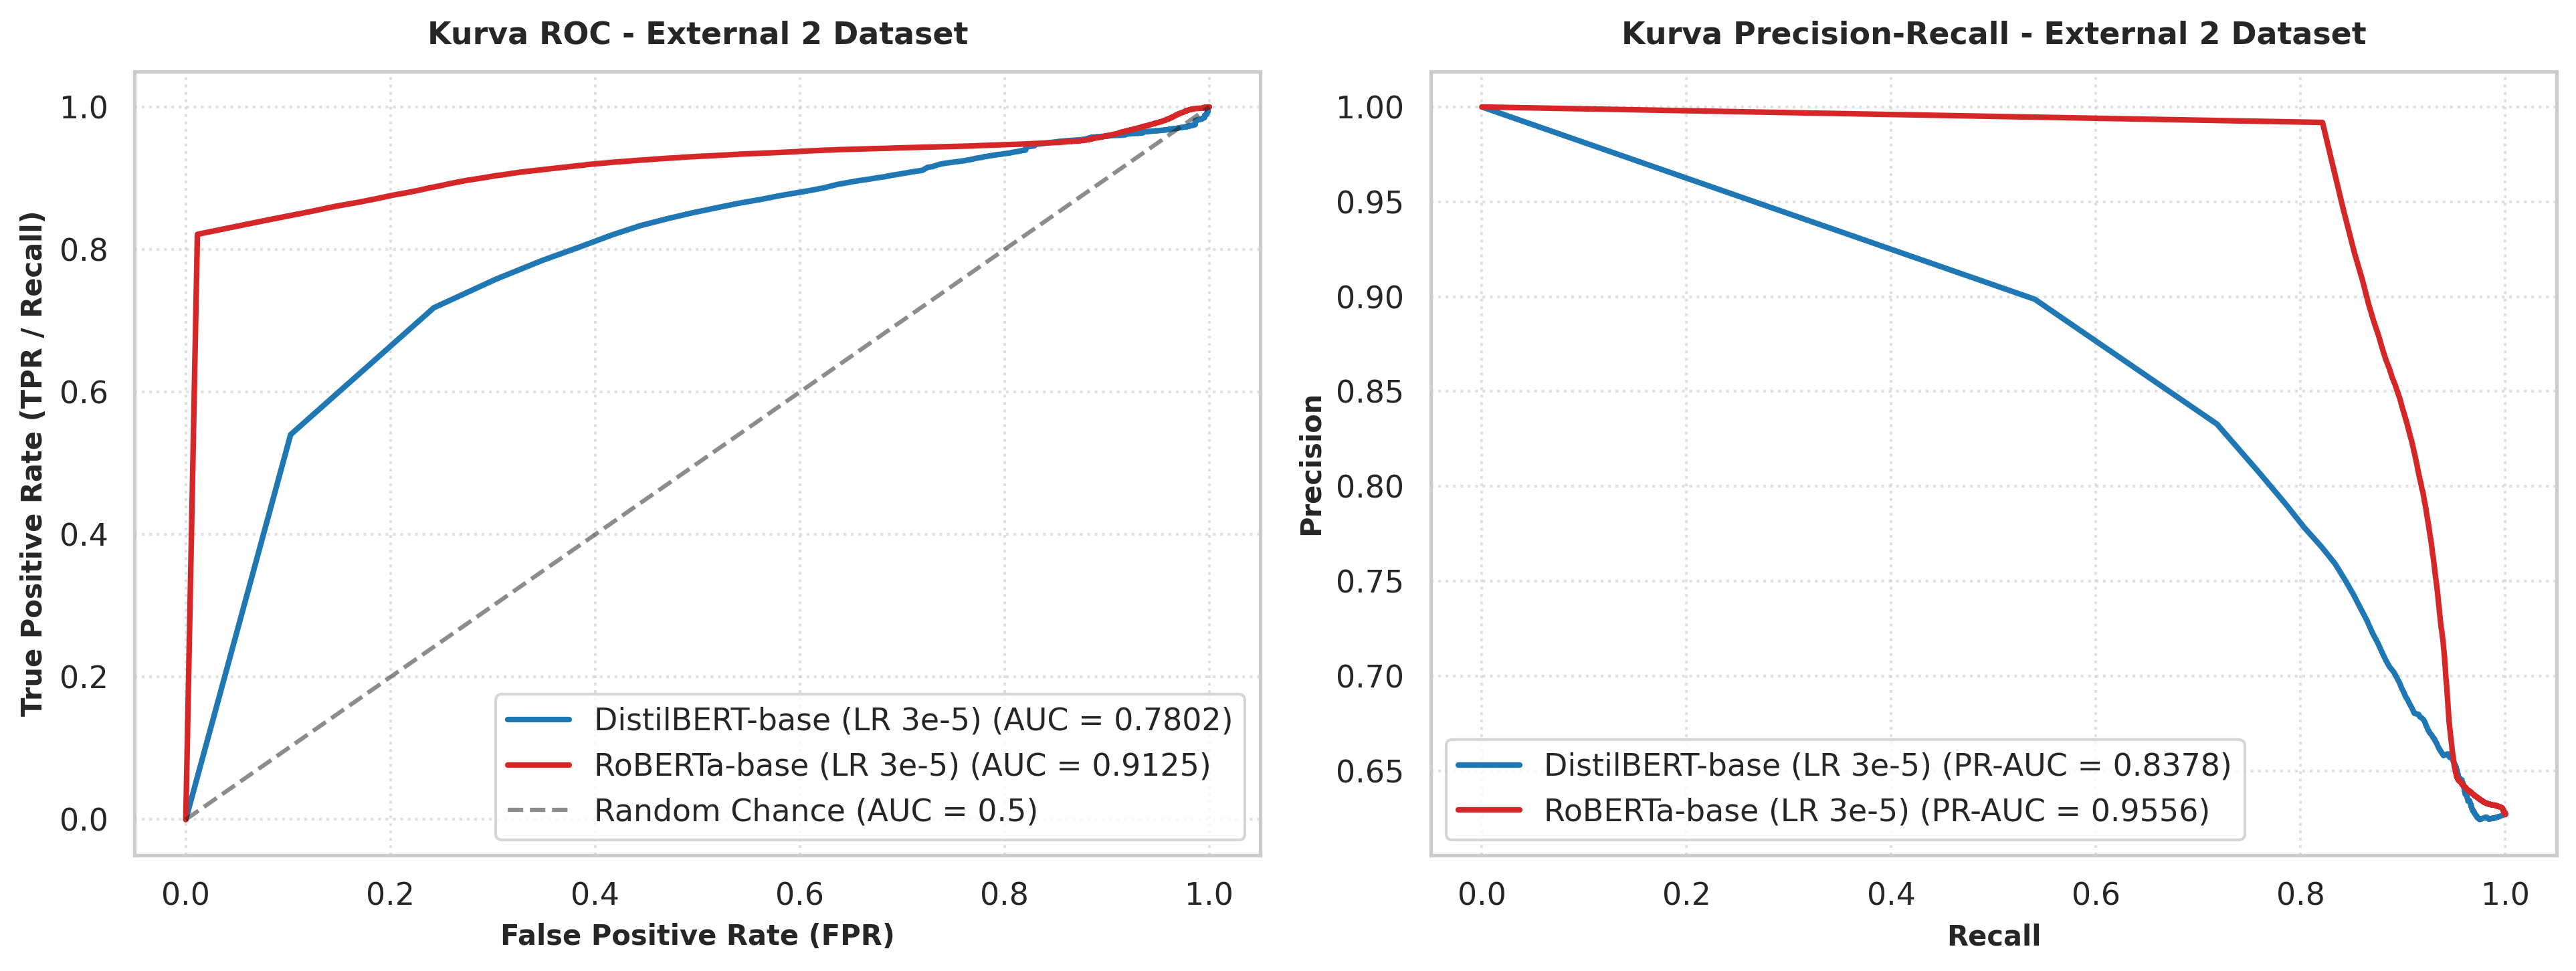

✅ Plot 2 tersimpan ke: /content/drive/MyDrive/Skripsi/results/lr3e5_ext2_02_roc_pr_curves.png


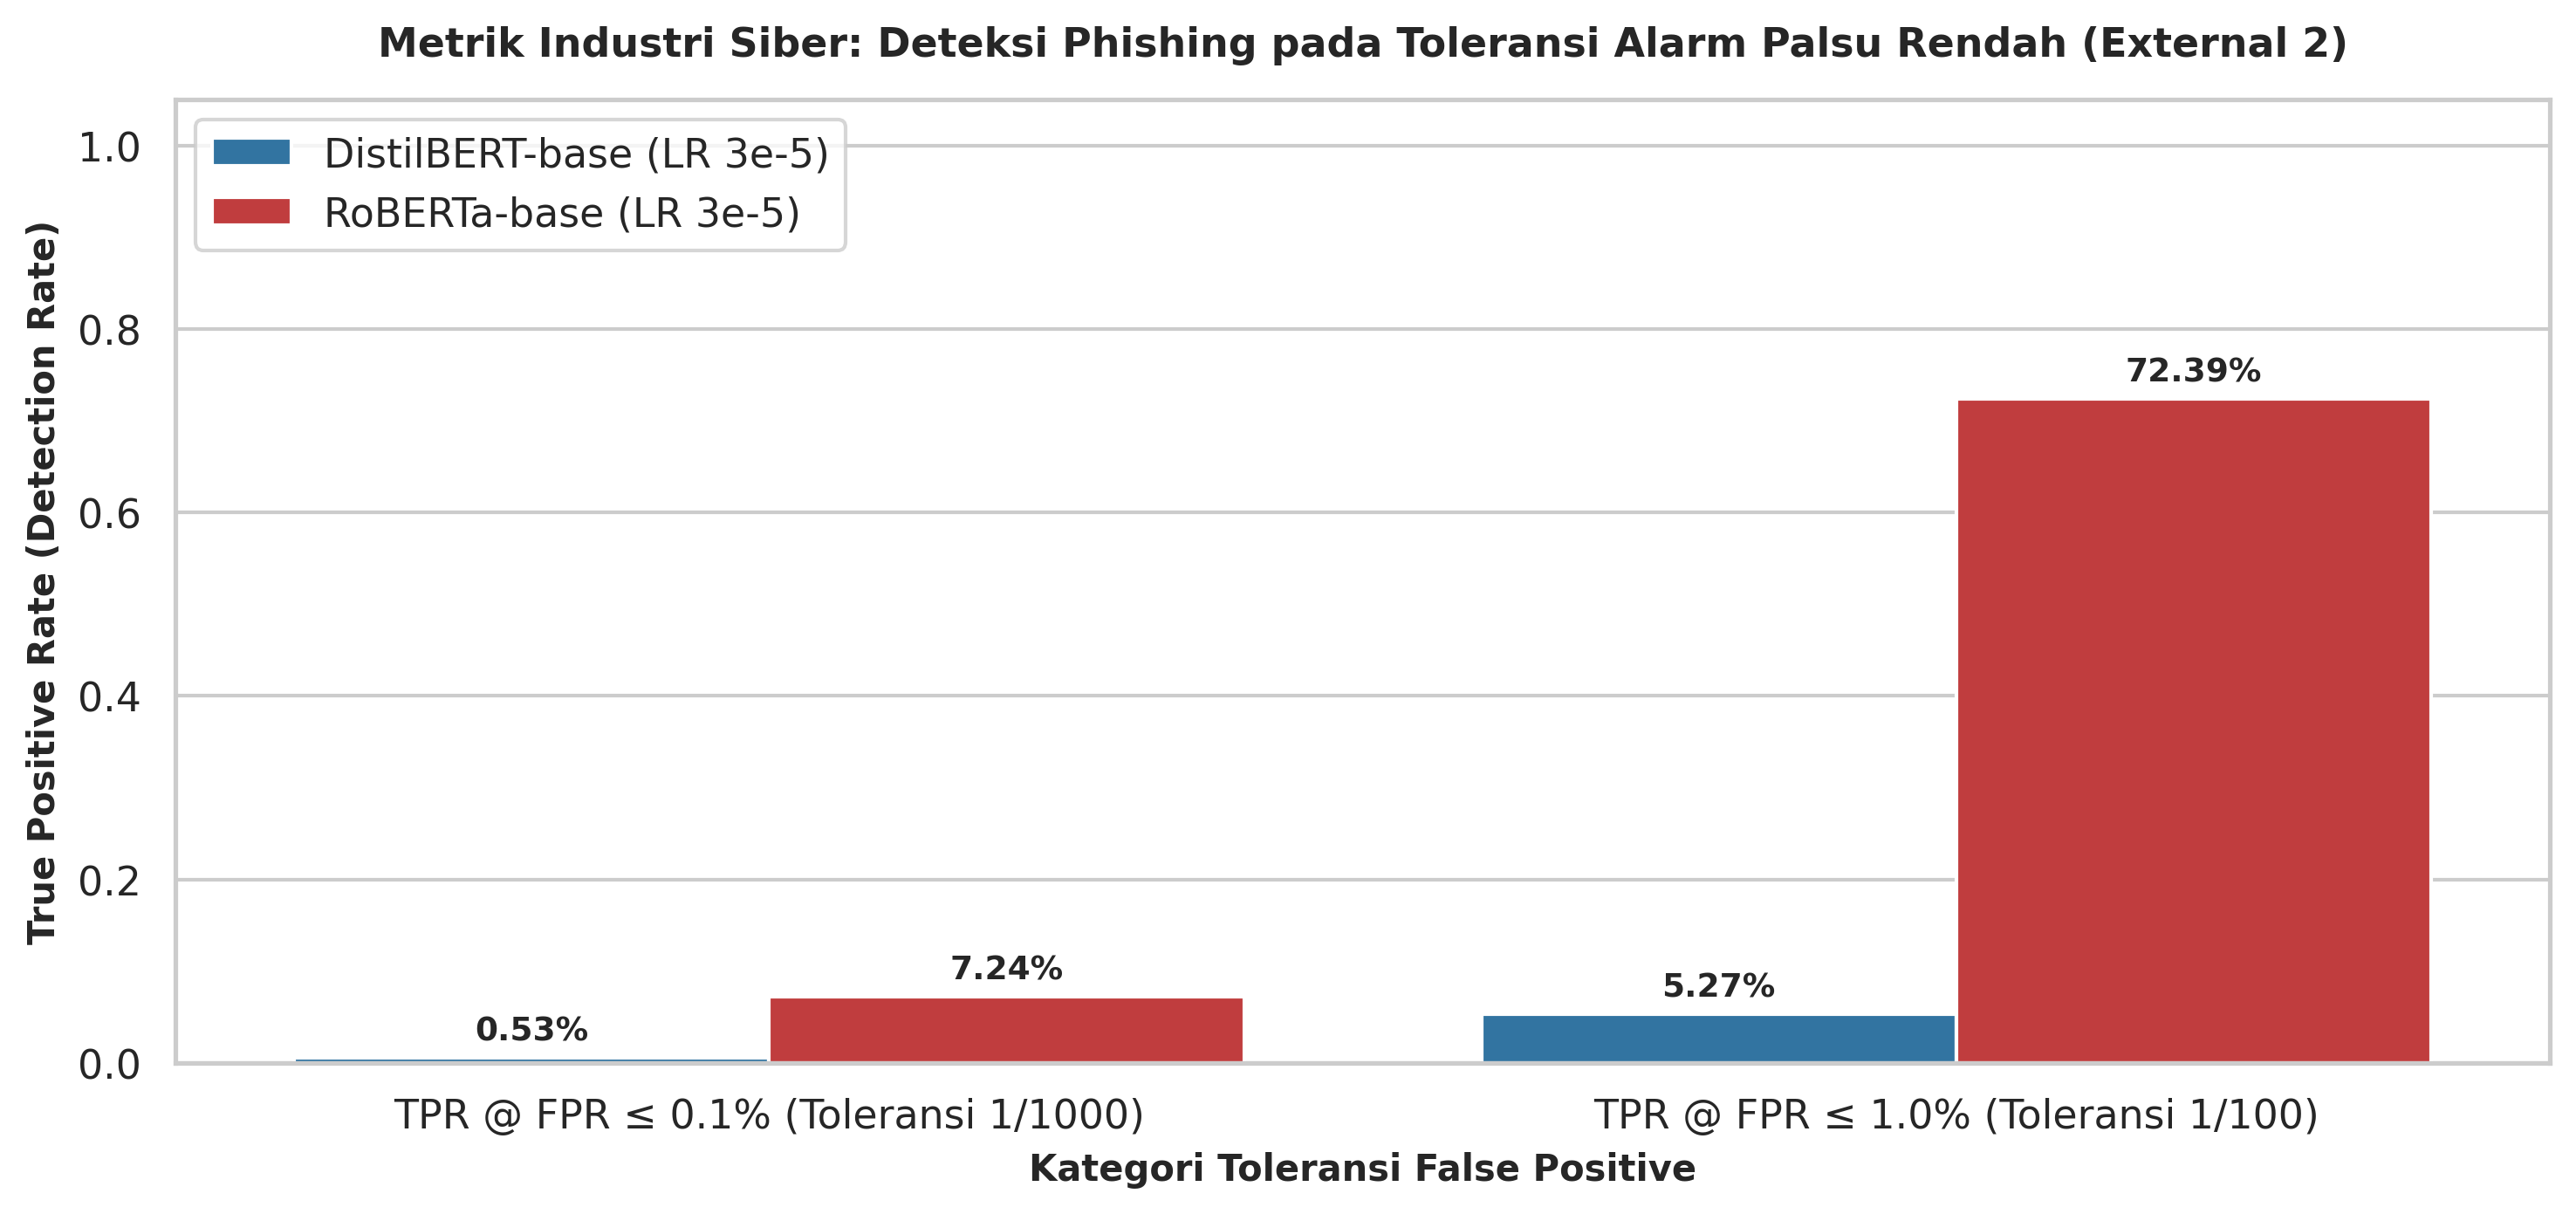

✅ Plot 3 tersimpan ke: /content/drive/MyDrive/Skripsi/results/lr3e5_ext2_03_tpr_at_low_fpr.png


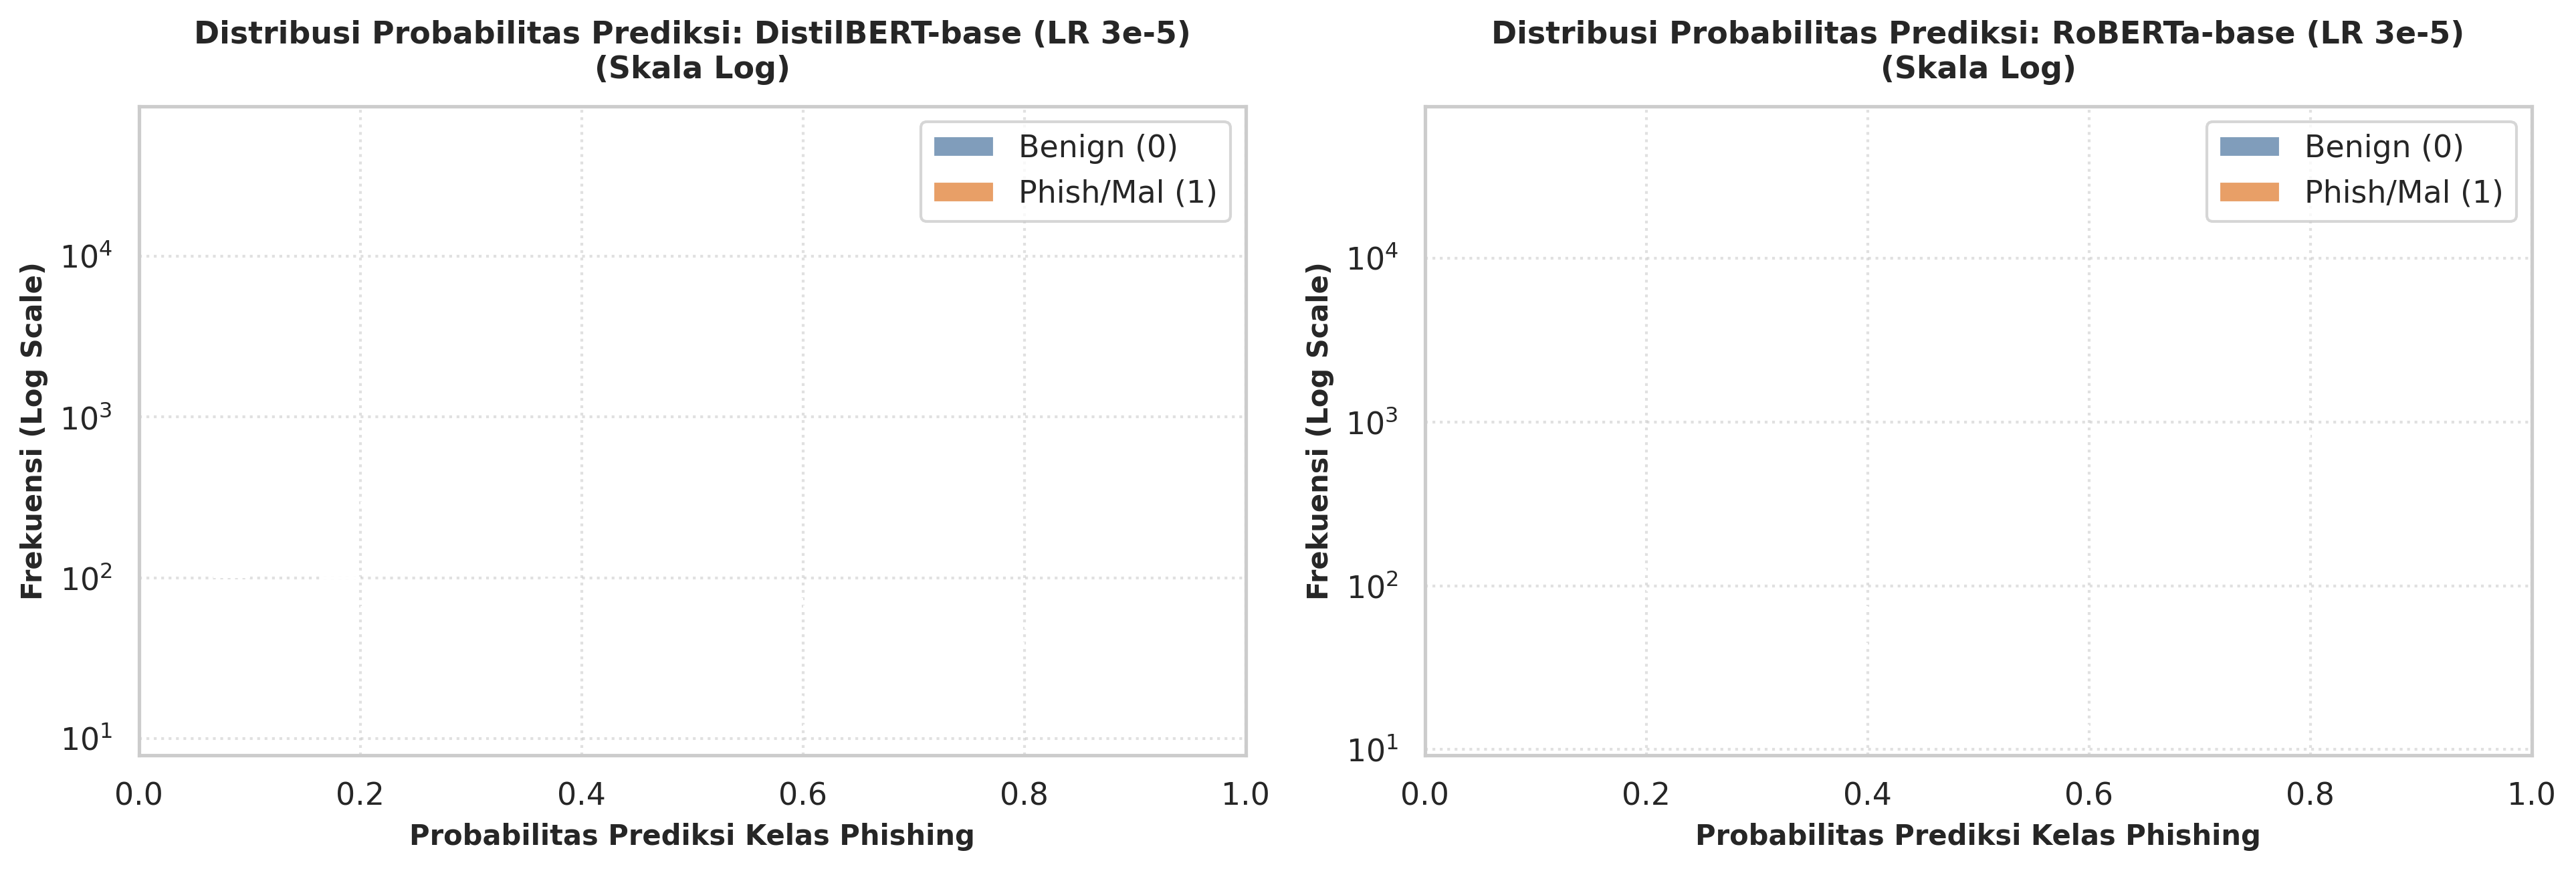

✅ Plot 4 tersimpan ke: /content/drive/MyDrive/Skripsi/results/lr3e5_ext2_04_confidence_distribution.png


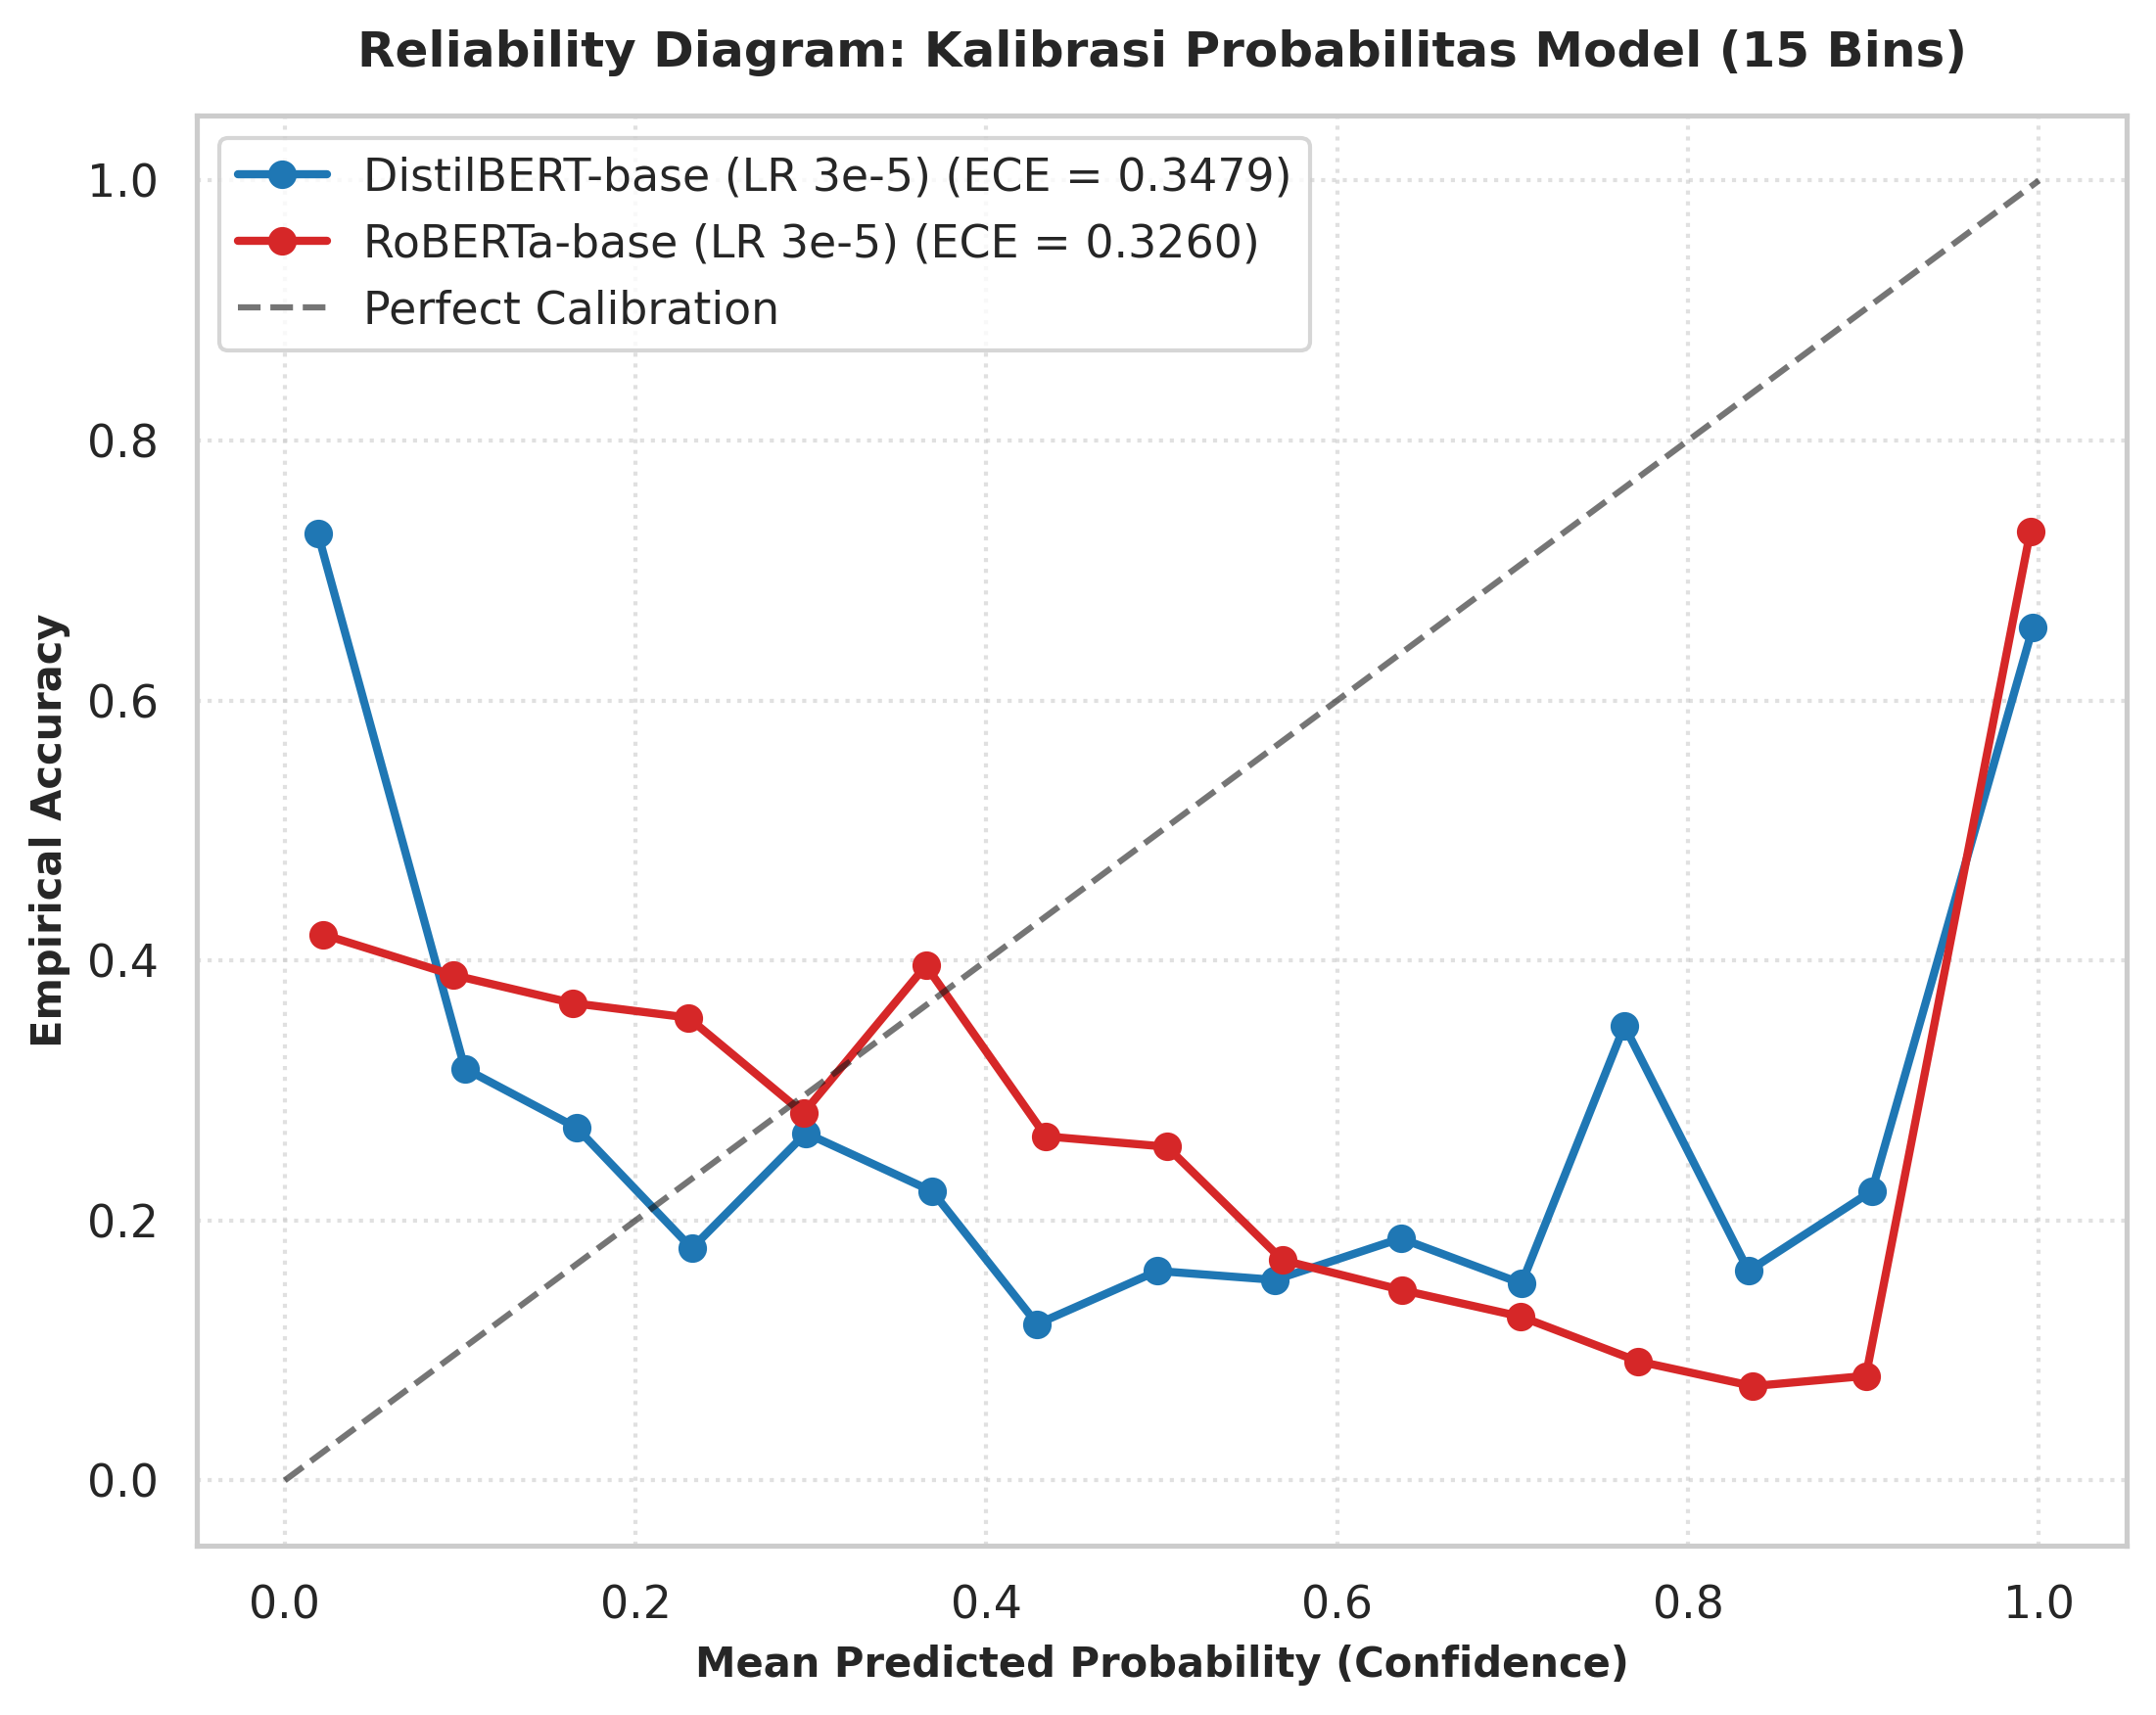

✅ Plot 5 tersimpan ke: /content/drive/MyDrive/Skripsi/results/lr3e5_ext2_05_calibration_curves.png


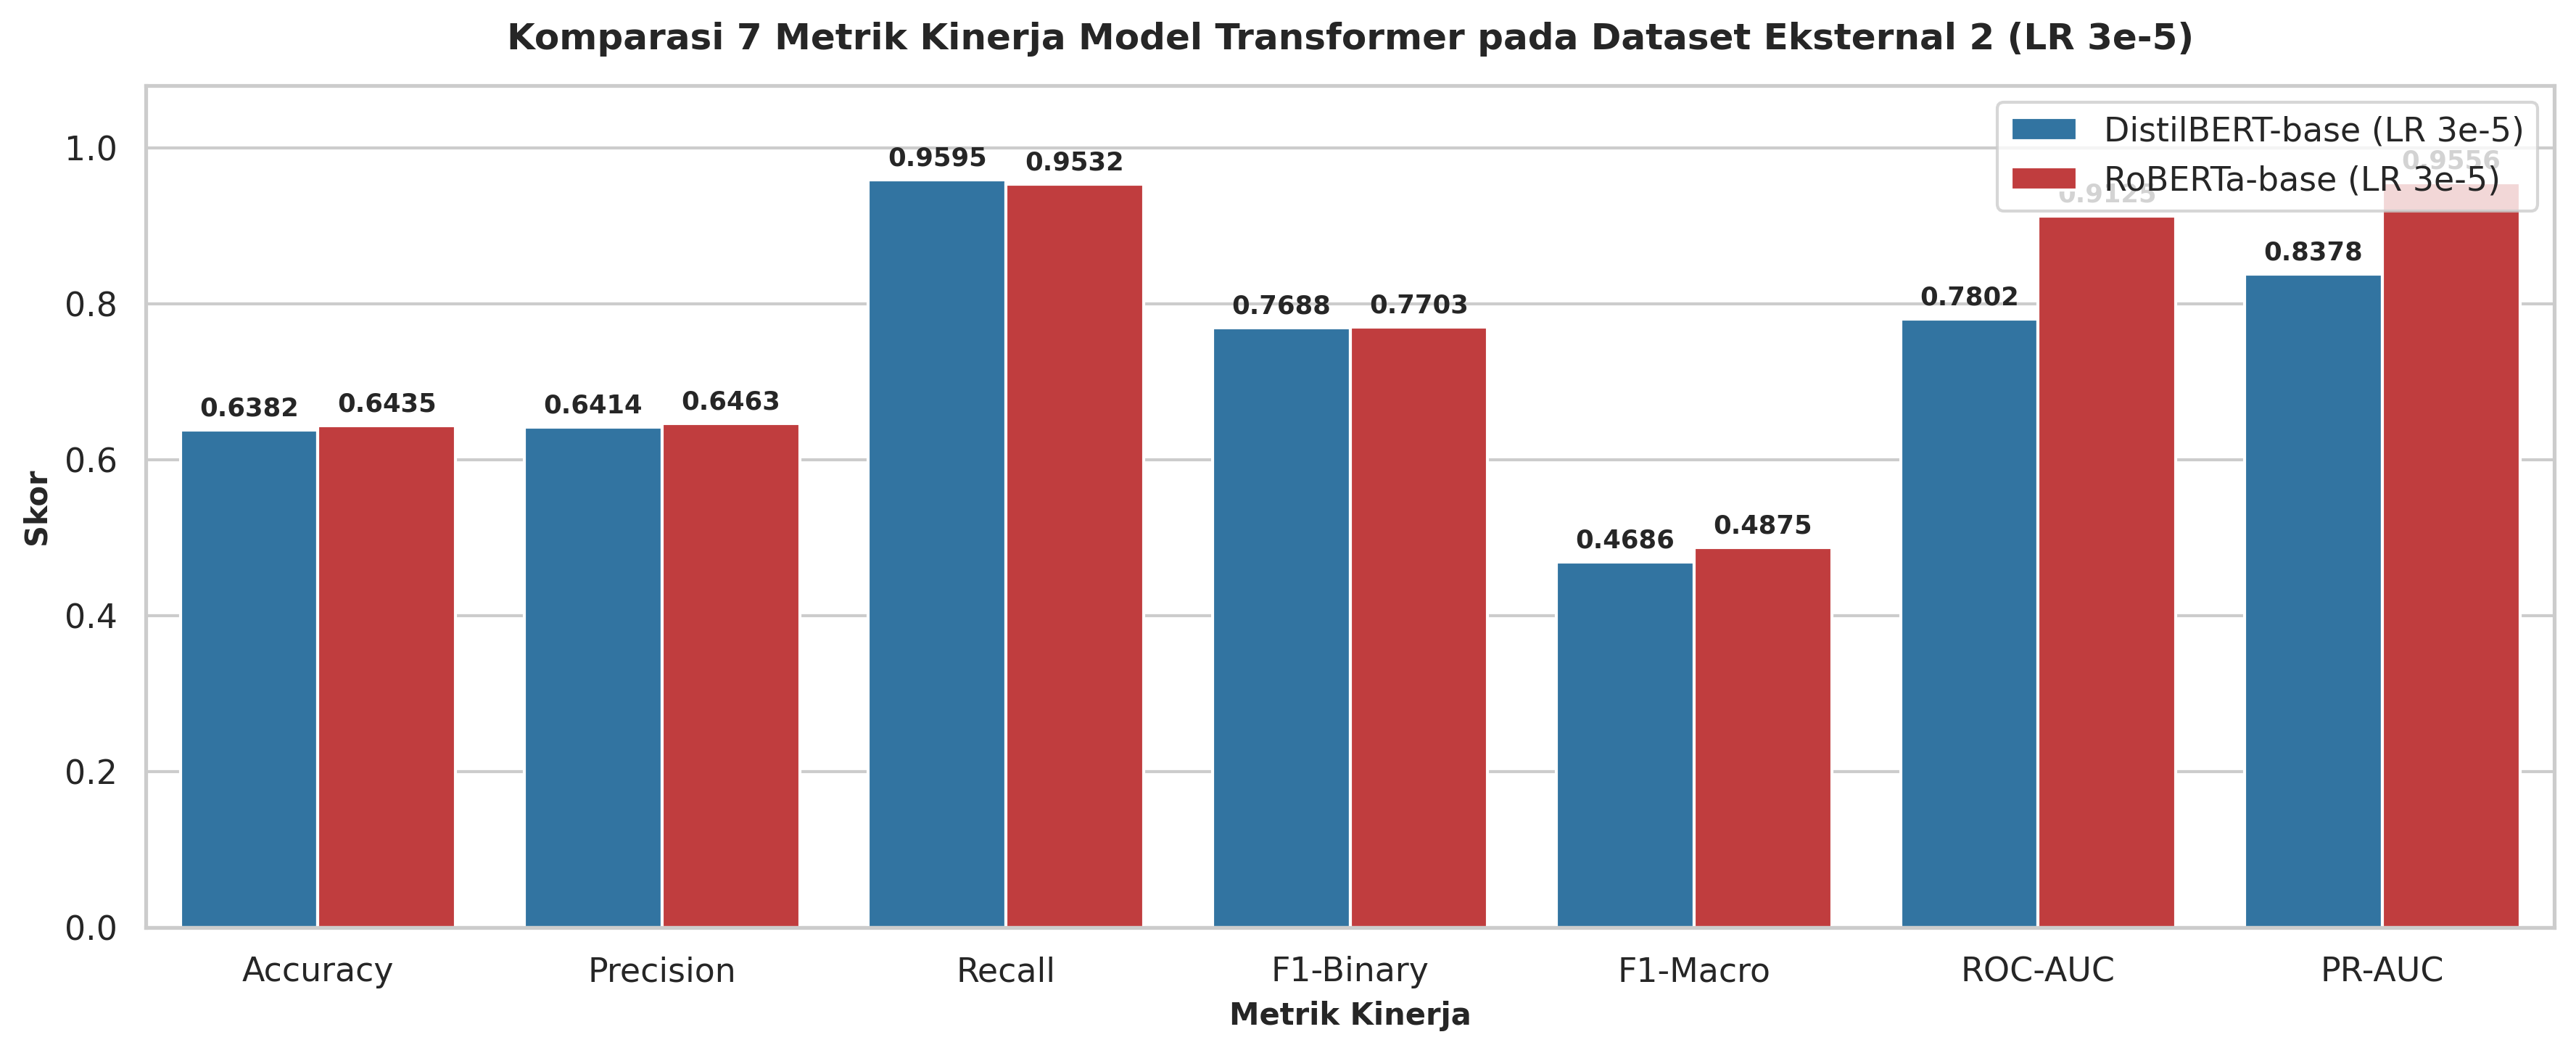

✅ Plot 6 tersimpan ke: /content/drive/MyDrive/Skripsi/results/lr3e5_ext2_06_performance_metrics.png


In [15]:
print("[INFO] Membuat 6 grafik visualisasi External 2 standar 300 DPI...")

ext2_models = ['DistilBERT-base (LR 3e-5)', 'RoBERTa-base (LR 3e-5)']
palette = {'DistilBERT-base (LR 3e-5)': '#1f77b4', 'RoBERTa-base (LR 3e-5)': '#d62728'}

# ---------------------------------------------------------------------
# PLOT 1: Confusion Matrices Berdampingan (Counts + Persentase Baris)
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), dpi=300)
for ax, m_name in zip(axes, ext2_models):
    cm = ext2_eval_predictions[m_name]['confusion_matrix']
    cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

    annot = np.empty_like(cm, dtype=object)
    for i in range(2):
        for j in range(2):
            annot[i, j] = f"{cm[i, j]:,}\n({cm_pct[i, j]:.2f}%)"

    sns.heatmap(cm, annot=annot, fmt='', cmap='Reds' if 'RoBERTa' in m_name else 'Blues',
                cbar=False, ax=ax,
                xticklabels=['Benign (0)', 'Malware/Phish (1)'],
                yticklabels=['Benign (0)', 'Malware/Phish (1)'],
                annot_kws={'fontsize': 11, 'fontweight': 'bold'})
    ax.set_title(f"Confusion Matrix: {m_name}\n(External 2 Dataset)", fontsize=11, fontweight='bold', pad=10)
    ax.set_xlabel("Prediksi Model", fontsize=10, fontweight='bold')
    ax.set_ylabel("Label Aktual", fontsize=10, fontweight='bold')

plt.tight_layout()
p1_ext2 = os.path.join(RESULTS_DIR, "lr3e5_ext2_01_confusion_matrices.png")
plt.savefig(p1_ext2, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Plot 1 tersimpan ke: {p1_ext2}")

# ---------------------------------------------------------------------
# PLOT 2: Kurva ROC & Precision-Recall Berdampingan
# ---------------------------------------------------------------------
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

for m_name in ext2_models:
    y_t = ext2_eval_predictions[m_name]['y_true']
    y_pr = ext2_eval_predictions[m_name]['y_prob']

    fpr, tpr, _ = roc_curve(y_t, y_pr)
    auc_v = roc_auc_score(y_t, y_pr)
    ax_roc.plot(fpr, tpr, label=f"{m_name} (AUC = {auc_v:.4f})", color=palette[m_name], linewidth=2)

    prec_arr, rec_arr, _ = precision_recall_curve(y_t, y_pr)
    pr_auc_v = average_precision_score(y_t, y_pr)
    ax_pr.plot(rec_arr, prec_arr, label=f"{m_name} (PR-AUC = {pr_auc_v:.4f})", color=palette[m_name], linewidth=2)

ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance (AUC = 0.5)')
ax_roc.set_title("Kurva ROC - External 2 Dataset", fontsize=11, fontweight='bold', pad=10)
ax_roc.set_xlabel("False Positive Rate (FPR)", fontsize=10, fontweight='bold')
ax_roc.set_ylabel("True Positive Rate (TPR / Recall)", fontsize=10, fontweight='bold')
ax_roc.legend(loc='lower right', frameon=True)
ax_roc.grid(True, linestyle=':', alpha=0.6)

ax_pr.set_title("Kurva Precision-Recall - External 2 Dataset", fontsize=11, fontweight='bold', pad=10)
ax_pr.set_xlabel("Recall", fontsize=10, fontweight='bold')
ax_pr.set_ylabel("Precision", fontsize=10, fontweight='bold')
ax_pr.legend(loc='lower left', frameon=True)
ax_pr.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
p2_ext2 = os.path.join(RESULTS_DIR, "lr3e5_ext2_02_roc_pr_curves.png")
plt.savefig(p2_ext2, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Plot 2 tersimpan ke: {p2_ext2}")

# ---------------------------------------------------------------------
# PLOT 3: Bar Chart TPR @ low FPR (<=0.1% dan <=1.0%)
# ---------------------------------------------------------------------
tpr_df = df_ext2_summary[['model', 'tpr_at_fpr_0.1pct', 'tpr_at_fpr_1.0pct']].melt(
    id_vars=['model'],
    value_vars=['tpr_at_fpr_0.1pct', 'tpr_at_fpr_1.0pct'],
    var_name='threshold',
    value_name='tpr'
)
tpr_df['threshold'] = tpr_df['threshold'].map({
    'tpr_at_fpr_0.1pct': 'TPR @ FPR ≤ 0.1% (Toleransi 1/1000)',
    'tpr_at_fpr_1.0pct': 'TPR @ FPR ≤ 1.0% (Toleransi 1/100)'
})

plt.figure(figsize=(10, 4.8), dpi=300)
ax = sns.barplot(data=tpr_df, x='threshold', y='tpr', hue='model', palette=['#1f77b4', '#d62728'])
plt.title("Metrik Industri Siber: Deteksi Phishing pada Toleransi Alarm Palsu Rendah (External 2)", fontsize=11, fontweight='bold', pad=12)
plt.xlabel("Kategori Toleransi False Positive", fontsize=10, fontweight='bold')
plt.ylabel("True Positive Rate (Detection Rate)", fontsize=10, fontweight='bold')
plt.ylim(0.0, 1.05)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h*100:.2f}%", (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                    textcoords='offset points', fontweight='semibold')

plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
p3_ext2 = os.path.join(RESULTS_DIR, "lr3e5_ext2_03_tpr_at_low_fpr.png")
plt.savefig(p3_ext2, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Plot 3 tersimpan ke: {p3_ext2}")

# ---------------------------------------------------------------------
# PLOT 4: Histogram Distribusi Probabilitas Prediksi (Skala Log)
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), dpi=300)

for ax, m_name in zip(axes, ext2_models):
    y_t = ext2_eval_predictions[m_name]['y_true']
    y_p = ext2_eval_predictions[m_name]['y_prob']

    sns.histplot(y_p[y_t == 0], bins=30, color='#2b5c8f', label='Benign (0)', ax=ax, alpha=0.6, log_scale=(False, True))
    sns.histplot(y_p[y_t == 1], bins=30, color='#d95f02', label='Phish/Mal (1)', ax=ax, alpha=0.6, log_scale=(False, True))
    ax.set_title(f"Distribusi Probabilitas Prediksi: {m_name}\n(Skala Log)", fontsize=11, fontweight='bold', pad=10)
    ax.set_xlabel("Probabilitas Prediksi Kelas Phishing", fontsize=10, fontweight='bold')
    ax.set_ylabel("Frekuensi (Log Scale)", fontsize=10, fontweight='bold')
    ax.set_xlim(0, 1)
    ax.legend(frameon=True)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
p4_ext2 = os.path.join(RESULTS_DIR, "lr3e5_ext2_04_confidence_distribution.png")
plt.savefig(p4_ext2, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Plot 4 tersimpan ke: {p4_ext2}")

# ---------------------------------------------------------------------
# PLOT 5: Kurva Kalibrasi (Reliability Diagram 15 Bins)
# ---------------------------------------------------------------------
plt.figure(figsize=(7.5, 6), dpi=300)
n_bins = 15
bin_limits = np.linspace(0, 1, n_bins + 1)

for m_name in ext2_models:
    y_t = ext2_eval_predictions[m_name]['y_true']
    y_p = ext2_eval_predictions[m_name]['y_prob']

    bin_accs, bin_confs = [], []
    for i in range(n_bins):
        in_bin = (y_p >= bin_limits[i]) & (y_p <= bin_limits[i+1]) if i == n_bins - 1 else (y_p >= bin_limits[i]) & (y_p < bin_limits[i+1])
        if np.sum(in_bin) > 0:
            bin_accs.append(np.mean(y_t[in_bin]))
            bin_confs.append(np.mean(y_p[in_bin]))

    ece_s = df_ext2_summary[df_ext2_summary['model'] == m_name]['ece'].iloc[0]
    plt.plot(bin_confs, bin_accs, marker='o', linewidth=2, color=palette[m_name], label=f"{m_name} (ECE = {ece_s:.4f})")

plt.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Perfect Calibration')
plt.title("Reliability Diagram: Kalibrasi Probabilitas Model (15 Bins)", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Mean Predicted Probability (Confidence)", fontsize=10, fontweight='bold')
plt.ylabel("Empirical Accuracy", fontsize=10, fontweight='bold')
plt.legend(frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

p5_ext2 = os.path.join(RESULTS_DIR, "lr3e5_ext2_05_calibration_curves.png")
plt.savefig(p5_ext2, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Plot 5 tersimpan ke: {p5_ext2}")

# ---------------------------------------------------------------------
# PLOT 6: Bar Chart 7 Metrik Utama External 2
# ---------------------------------------------------------------------
ext2_metrics_plot = ['accuracy', 'precision', 'recall', 'f1_binary', 'f1_macro', 'roc_auc', 'pr_auc']
ext2_metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Binary', 'F1-Macro', 'ROC-AUC', 'PR-AUC']

plot_ext2_df = df_ext2_summary.melt(
    id_vars=['model'],
    value_vars=ext2_metrics_plot,
    var_name='metric',
    value_name='score'
)
plot_ext2_df['metric'] = plot_ext2_df['metric'].map(dict(zip(ext2_metrics_plot, ext2_metric_labels)))

plt.figure(figsize=(12, 5), dpi=300)
ax = sns.barplot(data=plot_ext2_df, x='metric', y='score', hue='model', palette=['#1f77b4', '#d62728'])
plt.title("Komparasi 7 Metrik Kinerja Model Transformer pada Dataset Eksternal 2 (LR 3e-5)", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Metrik Kinerja", fontsize=10, fontweight='bold')
plt.ylabel("Skor", fontsize=10, fontweight='bold')
plt.ylim(0.0, 1.08)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.4f}", (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=8.5, xytext=(0, 3),
                    textcoords='offset points', fontweight='semibold')

plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
p6_ext2 = os.path.join(RESULTS_DIR, "lr3e5_ext2_06_performance_metrics.png")
plt.savefig(p6_ext2, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Plot 6 tersimpan ke: {p6_ext2}")


In [16]:
print("======================================================================")
print("🔬 ANALISIS INFERENSI STATISTIK: BOOTSTRAP 95% CI & UJI MCNEMAR")
print("======================================================================")

# 1. Bootstrap 95% Confidence Interval (1000 Resamples dengan tqdm)
def bootstrap_ci(y_true, y_pred, y_prob, n_bootstraps=1000, alpha=0.05, desc="Bootstrap"):
    rng = np.random.RandomState(42)
    n_samples = len(y_true)
    f1_list, roc_list = [], []

    for _ in tqdm(range(n_bootstraps), desc=desc):
        idx = rng.randint(0, n_samples, n_samples)
        yt_s = y_true[idx]
        yp_s = y_pred[idx]
        ypr_s = y_prob[idx]

        f1_list.append(f1_score(yt_s, yp_s, average='binary', zero_division=0))
        try:
            roc_list.append(roc_auc_score(yt_s, ypr_s))
        except Exception:
            pass

    f1_low  = np.percentile(f1_list, 100 * (alpha / 2))
    f1_high = np.percentile(f1_list, 100 * (1 - alpha / 2))
    roc_low  = np.percentile(roc_list, 100 * (alpha / 2)) if roc_list else np.nan
    roc_high = np.percentile(roc_list, 100 * (1 - alpha / 2)) if roc_list else np.nan

    return {
        'f1_ci': (f1_low, f1_high),
        'roc_ci': (roc_low, roc_high),
        'f1_bootstraps': f1_list,
        'roc_bootstraps': roc_list
    }

ci_results = {}
ci_table_rows = []

for m_name in ext2_models:
    yt = ext2_eval_predictions[m_name]['y_true']
    yp = ext2_eval_predictions[m_name]['y_pred']
    ypr = ext2_eval_predictions[m_name]['y_prob']

    res_ci = bootstrap_ci(yt, yp, ypr, n_bootstraps=1000, desc=f"Bootstrap 95% CI: {m_name}")
    ci_results[m_name] = res_ci

    f1_val = f1_score(yt, yp, average='binary', zero_division=0)
    roc_val = roc_auc_score(yt, ypr)

    ci_table_rows.append({
        'Model': m_name,
        'F1-Score': f"{f1_val:.4f}",
        'F1 95% CI': f"[{res_ci['f1_ci'][0]:.4f}, {res_ci['f1_ci'][1]:.4f}]",
        'ROC-AUC': f"{roc_val:.4f}",
        'ROC-AUC 95% CI': f"[{res_ci['roc_ci'][0]:.4f}, {res_ci['roc_ci'][1]:.4f}]"
    })

print("\n📊 TABEL INTERVAL KEPERCAYAAN BOOTSTRAP 95% CI (1000 RESAMPLES):")
df_ci_table = pd.DataFrame(ci_table_rows)
display(df_ci_table)

# 2. Uji McNemar Berpasangan (DistilBERT Baru vs RoBERTa Baru pada External 2)
print("\n" + "=" * 70)
print("🔬 UJI MCNEMAR: DistilBERT-base (LR 3e-5) vs RoBERTa-base (LR 3e-5)")
print("=" * 70)

yt_ext2 = ext2_eval_predictions['DistilBERT-base (LR 3e-5)']['y_true']
pred_distil = ext2_eval_predictions['DistilBERT-base (LR 3e-5)']['y_pred']
pred_roberta = ext2_eval_predictions['RoBERTa-base (LR 3e-5)']['y_pred']

corr_d = (pred_distil == yt_ext2)
corr_r = (pred_roberta == yt_ext2)

# Tabel Kontinjensi
a = int(np.sum(corr_d & corr_r))    # Keduanya Benar
b = int(np.sum(corr_d & ~corr_r))   # DistilBERT Benar, RoBERTa Salah
c = int(np.sum(~corr_d & corr_r))   # DistilBERT Salah, RoBERTa Benar
d = int(np.sum(~corr_d & ~corr_r))  # Keduanya Salah

print("Tabel Kontinjensi McNemar (External 2):")
print(f" - Keduanya Benar (a)                      : {a:,}")
print(f" - DistilBERT Benar, RoBERTa Salah (b)     : {b:,}")
print(f" - DistilBERT Salah, RoBERTa Benar (c)     : {c:,}")
print(f" - Keduanya Salah (d)                      : {d:,}")

if (b + c) > 0:
    # Koreksi Kontinuitas Edwards
    chi2_val = ((abs(b - c) - 1.0) ** 2) / (b + c)
    p_val = 1.0 - stats.chi2.cdf(chi2_val, df=1)
    print(f"\nStatistik Chi-Square McNemar : {chi2_val:.4f}")
    print(f"p-value                       : {p_val:.4e}")
    if p_val < 0.05:
        print("✅ [HASIL] Perbedaan kinerja kedua model baru SIGNIFIKAN secara statistik (p < 0.05).")
    else:
        print("➖ [HASIL] Tidak ada perbedaan kinerja yang signifikan secara statistik (p >= 0.05).")
else:
    print("[INFO] Tidak ada sampel diskordan (b + c == 0).")


🔬 ANALISIS INFERENSI STATISTIK: BOOTSTRAP 95% CI & UJI MCNEMAR


Bootstrap 95% CI: DistilBERT-base (LR 3e-5):   0%|          | 0/1000 [00:00<?, ?it/s]

Bootstrap 95% CI: RoBERTa-base (LR 3e-5):   0%|          | 0/1000 [00:00<?, ?it/s]


📊 TABEL INTERVAL KEPERCAYAAN BOOTSTRAP 95% CI (1000 RESAMPLES):


,Model,F1-Score,F1 95% CI,ROC-AUC,ROC-AUC 95% CI
0,DistilBERT-base (LR 3e-5),0.7688,"[0.7664, 0.7711]",0.7802,"[0.7771, 0.7831]"
1,RoBERTa-base (LR 3e-5),0.7703,"[0.7680, 0.7726]",0.9125,"[0.9105, 0.9145]"



🔬 UJI MCNEMAR: DistilBERT-base (LR 3e-5) vs RoBERTa-base (LR 3e-5)
Tabel Kontinjensi McNemar (External 2):
 - Keduanya Benar (a)                      : 57,823
 - DistilBERT Benar, RoBERTa Salah (b)     : 3,557
 - DistilBERT Salah, RoBERTa Benar (c)     : 4,070
 - Keduanya Salah (d)                      : 30,727

Statistik Chi-Square McNemar : 34.3705
p-value                       : 4.5557e-09
✅ [HASIL] Perbedaan kinerja kedua model baru SIGNIFIKAN secara statistik (p < 0.05).


In [17]:
print("======================================================================")
print("🔍 ANALISIS SUBGROUP & SAMPEL ERROR (FP / FN)")
print("======================================================================")

# 1. Analisis Subgroup (IP vs Domain & Suspicious File Extension)
def evaluate_subgroup(y_t_sub, y_p_sub, y_pr_sub):
    n_s = len(y_t_sub)
    if n_s == 0:
        return {'Sampel': 0, 'Recall': np.nan, 'FPR': np.nan, 'F1-Score': np.nan, 'ROC-AUC': 'N/A'}
    rec = recall_score(y_t_sub, y_p_sub, zero_division=0)
    cm = confusion_matrix(y_t_sub, y_p_sub, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel() if cm.shape == (2, 2) else (0, 0, 0, 0)
    fpr = fp / max(fp + tn, 1)
    f1 = f1_score(y_t_sub, y_p_sub, average='binary', zero_division=0)

    # Jika hanya ada 1 kelas unik, AUC = N/A
    if len(np.unique(y_t_sub)) > 1:
        try:
            auc_str = f"{roc_auc_score(y_t_sub, y_pr_sub):.4f}"
        except Exception:
            auc_str = "N/A"
    else:
        auc_str = "N/A"

    return {
        'Sampel': n_s,
        'Recall': round(rec, 4),
        'FPR': round(fpr, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': auc_str
    }

subgroup_records = []

for m_name in ext2_models:
    yt_all = ext2_eval_predictions[m_name]['y_true']
    yp_all = ext2_eval_predictions[m_name]['y_pred']
    ypr_all = ext2_eval_predictions[m_name]['y_prob']

    # Subgroup IP vs Domain
    if 'has_ip_address' in df_ext2.columns:
        ip_mask = (df_ext2['has_ip_address'] == 1).values
        dom_mask = (df_ext2['has_ip_address'] == 0).values

        res_ip = evaluate_subgroup(yt_all[ip_mask], yp_all[ip_mask], ypr_all[ip_mask])
        res_dom = evaluate_subgroup(yt_all[dom_mask], yp_all[dom_mask], ypr_all[dom_mask])

        subgroup_records.append({'Model': m_name, 'Subgroup': 'Host Berbasis IP (has_ip=1)', **res_ip})
        subgroup_records.append({'Model': m_name, 'Subgroup': 'Host Berbasis Domain (has_ip=0)', **res_dom})

    # Subgroup Suspicious File Extension
    if 'suspicious_file_extension' in df_ext2.columns:
        ext1_mask = (df_ext2['suspicious_file_extension'] == 1).values
        ext0_mask = (df_ext2['suspicious_file_extension'] == 0).values

        res_ext1 = evaluate_subgroup(yt_all[ext1_mask], yp_all[ext1_mask], ypr_all[ext1_mask])
        res_ext0 = evaluate_subgroup(yt_all[ext0_mask], yp_all[ext0_mask], ypr_all[ext0_mask])

        subgroup_records.append({'Model': m_name, 'Subgroup': 'Ekstensi Bahaya (suspicious_ext=1)', **res_ext1})
        subgroup_records.append({'Model': m_name, 'Subgroup': 'Ekstensi Normal (suspicious_ext=0)', **res_ext0})

df_subgroups = pd.DataFrame(subgroup_records)
subgroup_csv = os.path.join(RESULTS_DIR, "lr3e5_ext2_subgroup_analysis.csv")
df_subgroups.to_csv(subgroup_csv, index=False)
print("📊 HASIL ANALISIS SUBGROUP DATASET EKSTERNAL 2:")
display(df_subgroups)
print(f"✅ Rekapitulasi subgroup tersimpan ke: {subgroup_csv}")

# 2. Error Analysis: Top-5 False Positive & False Negative per Model (URL dipotong 90 char)
print("\n" + "=" * 70)
print("🔍 CONTOH KESALAHAN PREDIKSI TERATAS (TOP-5 FP & FN PER MODEL)")
print("=" * 70)

error_samples_records = []
urls_raw = df_ext2['url'].values
y_true_all = df_ext2['label'].values

for m_name in ext2_models:
    yp = ext2_eval_predictions[m_name]['y_pred']
    ypr = ext2_eval_predictions[m_name]['y_prob']

    # FP: True=0, Pred=1 (Probabilitas Phishing tertinggi)
    fp_indices = np.where((y_true_all == 0) & (yp == 1))[0]
    sorted_fp = fp_indices[np.argsort(-ypr[fp_indices])][:5]

    # FN: True=1, Pred=0 (Probabilitas Phishing terendah)
    fn_indices = np.where((y_true_all == 1) & (yp == 0))[0]
    sorted_fn = fn_indices[np.argsort(ypr[fn_indices])][:5]

    print(f"\n--- Model: {m_name} ---")
    print("📌 5 False Positive Teratas (URL Benign dikira Phishing):")
    for i, idx in enumerate(sorted_fp, 1):
        u_str = str(urls_raw[idx])
        p_val = ypr[idx]
        print(f"   [{i}] Prob Phish: {p_val:.4f} | URL: {u_str[:90]}")
        error_samples_records.append({'Model': m_name, 'Error_Type': 'False Positive', 'Prob_Phishing': round(p_val, 4), 'URL_90': u_str[:90], 'URL_Full': u_str})

    print("📌 5 False Negative Teratas (URL Phishing/Mal lolos deteksi):")
    for i, idx in enumerate(sorted_fn, 1):
        u_str = str(urls_raw[idx])
        p_val = ypr[idx]
        print(f"   [{i}] Prob Phish: {p_val:.4f} | URL: {u_str[:90]}")
        error_samples_records.append({'Model': m_name, 'Error_Type': 'False Negative', 'Prob_Phishing': round(p_val, 4), 'URL_90': u_str[:90], 'URL_Full': u_str})

df_error_samples = pd.DataFrame(error_samples_records)
error_csv_path = os.path.join(RESULTS_DIR, "lr3e5_ext2_error_analysis_samples.csv")
df_error_samples.to_csv(error_csv_path, index=False)
print(f"\n✅ Sampel analisis error tersimpan ke: {error_csv_path}")


🔍 ANALISIS SUBGROUP & SAMPEL ERROR (FP / FN)
📊 HASIL ANALISIS SUBGROUP DATASET EKSTERNAL 2:


,Model,Subgroup,Sampel,Recall,FPR,F1-Score,ROC-AUC
0,DistilBERT-base (LR 3e-5),Host Berbasis IP (has_ip=1),48702,0.9836,0.0000,0.9917,N/A
1,DistilBERT-base (LR 3e-5),Host Berbasis Domain (has_ip=0),47475,0.8581,0.9019,0.3693,0.6844
2,DistilBERT-base (LR 3e-5),Ekstensi Bahaya (suspicious_ext=1),13684,0.8931,0.0000,0.9435,N/A
3,DistilBERT-base (LR 3e-5),Ekstensi Normal (suspicious_ext=0),82493,0.9790,0.9019,0.7325,0.8124
4,RoBERTa-base (LR 3e-5),Host Berbasis IP (has_ip=1),48702,1.0000,0.0000,1.0000,N/A
5,RoBERTa-base (LR 3e-5),Host Berbasis Domain (has_ip=0),47475,0.7567,0.8769,0.3387,0.5710
6,RoBERTa-base (LR 3e-5),Ekstensi Bahaya (suspicious_ext=1),13684,0.8156,0.0000,0.8985,N/A
7,RoBERTa-base (LR 3e-5),Ekstensi Normal (suspicious_ext=0),82493,0.9935,0.8769,0.7447,0.9792


✅ Rekapitulasi subgroup tersimpan ke: /content/drive/MyDrive/Skripsi/results/lr3e5_ext2_subgroup_analysis.csv

🔍 CONTOH KESALAHAN PREDIKSI TERATAS (TOP-5 FP & FN PER MODEL)

--- Model: DistilBERT-base (LR 3e-5) ---
📌 5 False Positive Teratas (URL Benign dikira Phishing):
   [1] Prob Phish: 1.0000 | URL: https://www.refugeecouncil.org.uk
   [2] Prob Phish: 1.0000 | URL: https://www.enchantresslands.com
   [3] Prob Phish: 1.0000 | URL: https://www.easyhomelinks.com
   [4] Prob Phish: 1.0000 | URL: https://www.naturalhandcraftedsoapcompany.com
   [5] Prob Phish: 1.0000 | URL: https://www.logcabinrentalsnc.com
📌 5 False Negative Teratas (URL Phishing/Mal lolos deteksi):
   [1] Prob Phish: 0.0005 | URL: https://api.pastecode.io/anon/raw-snippet/vsyezv40?raw=inline&api=true&ticket=912a57c7-f20
   [2] Prob Phish: 0.0005 | URL: https://api.pastecode.io/anon/raw-snippet/c32qiqwg?raw=inline&api=true&ticket=912a57c7-f20
   [3] Prob Phish: 0.0005 | URL: https://api.pastecode.io/anon/raw-snippet/uk

## 11. Jawaban Inti Riset: "Apakah Ada Peningkatan?" (Komparasi LR 3e-5 vs LR 2e-5)

Pada bagian ini, inti dari rumusan masalah dijawab secara kuantitatif dan inferensial:
1. Membaca `OLD_EXT2_RESULTS` (`ext2_evaluation_results.csv`) hasil pelatihan model terdahulu (`LR 2e-5`) pada dataset External 2 yang sama persis.
2. Mencocokkan baris **DistilBERT (Seed 42)** dan **RoBERTa-base (Seed 42)** secara otomatis.
3. Menghitung **Nilai Delta ($\Delta = \text{Baru} - \text{Lama}$)** untuk seluruh metrik.
4. Menampilkan tabel Delta dengan styler berwarna hijau/merah/kuning.
5. Membuat grafik *grouped bar* komparasi **LR 2e-5 vs LR 3e-5** untuk In-Domain dan External 2.
6. **Kaidah Simpulan Ketat**: Klaim peningkatan hanya boleh dinyatakan **"Meningkat Signifikan"** jika:
   $$\Delta > +0.005 \quad \text{DAN} \quad \text{Rentang 95% CI Bootstrap Tidak Tumpang Tindih}$$
   Jika tidak memenuhi kedua syarat tersebut, perubahan dinyatakan **"Tidak Signifikan / Dalam Rentang Margin Error"**.


🎯 JAWABAN INTI: APAKAH ADA PENINGKATAN DENGAN LEARNING RATE 3e-5?
[INFO] Membaca hasil External 2 model lama dari: /content/drive/MyDrive/Skripsi/results/ext2_evaluation_results.csv...
     Kolom tersedia di file lama: ['model', 'accuracy', 'precision', 'recall', 'f1_binary', 'f1_macro', 'roc_auc', 'pr_auc', 'tpr_at_fpr_0.1pct', 'tpr_at_fpr_1.0pct', 'fpr', 'fnr', 'ece', 'brier_score', 'latency_ms', 'throughput_sps', 'peak_vram_gb', 'total_params', 'accuracy_mean', 'accuracy_std', 'precision_mean', 'precision_std', 'recall_mean', 'recall_std', 'f1_binary_mean', 'f1_binary_std', 'f1_macro_mean', 'f1_macro_std', 'roc_auc_mean', 'roc_auc_std', 'pr_auc_mean', 'pr_auc_std', 'tpr_at_fpr_0.1pct_mean', 'tpr_at_fpr_0.1pct_std', 'tpr_at_fpr_1.0pct_mean', 'tpr_at_fpr_1.0pct_std', 'fpr_mean', 'fpr_std', 'fnr_mean', 'fnr_std', 'ece_mean', 'ece_std', 'brier_score_mean', 'brier_score_std', 'latency_ms_mean', 'latency_ms_std', 'throughput_sps_mean', 'throughput_sps_std', 'peak_vram_gb_mean', 'peak_vram

,Model,Metrik,Lama (Seed 42),Lama (Min - Max 3 Seed),Baru (LR 3e-5),Delta (vs Seed 42),Arah Perubahan
0,DistilBERT-base,Accuracy,0.629100,"[0.6291, 0.6399]",0.638200,0.009100,⬆️ Meningkat
1,DistilBERT-base,Precision,0.635000,"[0.6350, 0.6417]",0.641400,0.006400,⬆️ Meningkat
2,DistilBERT-base,Recall,0.960700,"[0.9577, 0.9638]",0.959500,-0.001200,➖ Stabil
3,DistilBERT-base,F1-Score (Binary),0.764600,"[0.7646, 0.7704]",0.768800,0.004200,➖ Stabil
4,DistilBERT-base,F1-Score (Macro),0.445400,"[0.4454, 0.4677]",0.468600,0.023200,⬆️ Meningkat
5,DistilBERT-base,ROC-AUC,0.753200,"[0.7146, 0.7746]",0.780200,0.027000,⬆️ Meningkat
6,DistilBERT-base,PR-AUC,0.807800,"[0.7883, 0.8280]",0.837800,0.030000,⬆️ Meningkat
7,DistilBERT-base,TPR @ FPR ≤ 0.1%,0.003700,"[0.0037, 0.0045]",0.005300,0.001600,➖ Stabil
8,DistilBERT-base,TPR @ FPR ≤ 1.0%,0.037200,"[0.0372, 0.0450]",0.052700,0.015500,⬆️ Meningkat
9,DistilBERT-base,FPR (False Alarm),0.928200,"[0.9046, 0.9282]",0.901900,-0.026300,⬆️ Membaik (Menurun)


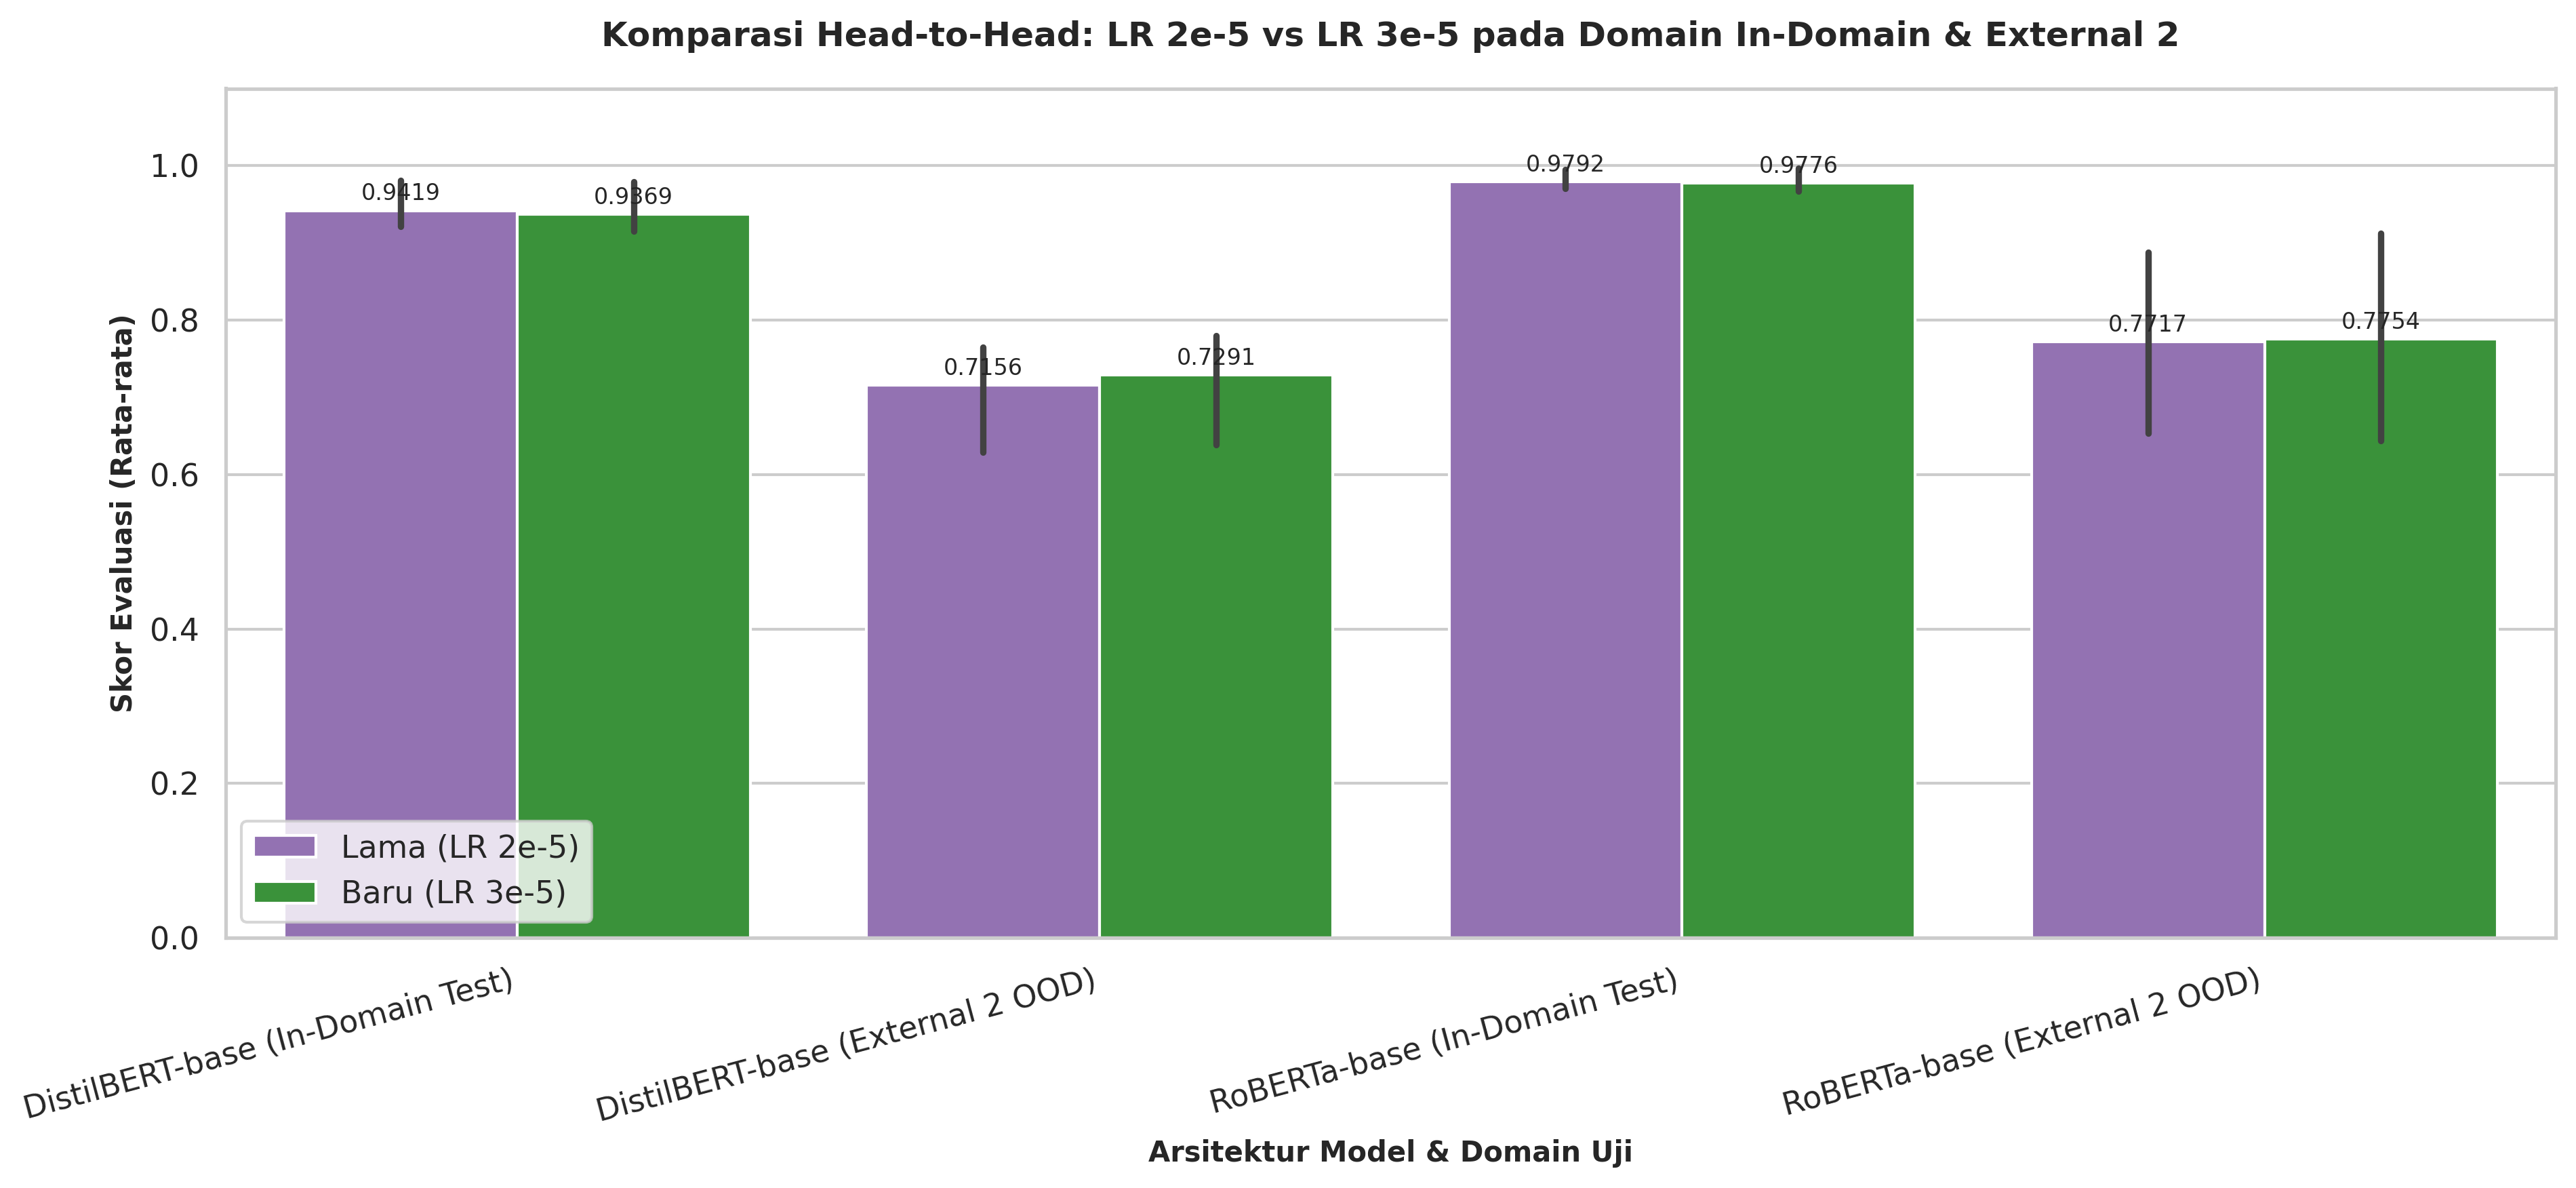

✅ Grafik grouped bar tersimpan ke: /content/drive/MyDrive/Skripsi/results/lr3e5_ext2_07_comparison_old_vs_new.png

📢 KESIMPULAN OTOMATIS BERBASIS SIGNIFIKANSI STATISTIK:

🔹 [Model: DistilBERT-base]
   F1-Score External 2 : Seed 42 = 0.7646 [Rentang Lama: 0.7646 - 0.7704] -> Baru = 0.7688 | Delta: +0.0042 | 95% CI Baru: [0.7664, 0.7711]
   ROC-AUC External 2  : Seed 42 = 0.7532 [Rentang Lama: 0.7146 - 0.7746] -> Baru = 0.7802 | Delta: +0.0270 | 95% CI Baru: [0.7771, 0.7831]
   👉 KESIMPULAN: Tidak dapat dibedakan dari variansi antar-seed/noise (tidak memenuhi syarat peningkatan/penurunan simultan pada F1 dan ROC-AUC di luar rentang acuan lama). Model baru dilatih satu kali tanpa random seed (unseeded).

🔹 [Model: RoBERTa-base]
   F1-Score External 2 : Seed 42 = 0.7734 [Rentang Lama: 0.7734 - 0.7734] -> Baru = 0.7703 | Delta: -0.0031 | 95% CI Baru: [0.7680, 0.7726]
   ROC-AUC External 2  : Seed 42 = 0.8882 [Rentang Lama: 0.8882 - 0.8882] -> Baru = 0.9125 | Delta: +0.0243 | 95% CI Baru: [0

In [18]:
print("======================================================================")
print("🎯 JAWABAN INTI: APAKAH ADA PENINGKATAN DENGAN LEARNING RATE 3e-5?")
print("======================================================================")

if not os.path.exists(OLD_EXT2_RESULTS):
    raise FileNotFoundError(
        f"❌ Jalankan dulu notebook 06 versi terbaru (dataset url_features_extracted1.csv) agar file ini terbentuk.\n"
        f"Path: {OLD_EXT2_RESULTS}"
    )

print(f"[INFO] Membaca hasil External 2 model lama dari: {OLD_EXT2_RESULTS}...")
df_old_ext2 = pd.read_csv(OLD_EXT2_RESULTS)
print(f"     Kolom tersedia di file lama: {list(df_old_ext2.columns)}")

# [DIUBAH] Guard Hasil Lama: Cetak jumlah sampel (jika ada kolomnya) & peringatan run notebook 06 terbaru
sample_col = next((c for c in df_old_ext2.columns if c.lower() in ['total_samples', 'samples', 'n_samples', 'jumlah_sampel', 'num_samples']), None) # [DIUBAH]
if sample_col: # [DIUBAH]
    print(f"[INFO] Jumlah sampel tercatat di file acuan lama ({sample_col}): {df_old_ext2[sample_col].iloc[0]:,}") # [DIUBAH]
else: # [DIUBAH]
    print(f"[INFO] Baris tercatat di file acuan lama: {len(df_old_ext2)} baris model.") # [DIUBAH]

print("⚠️ [PERINGATAN PENTING] File OLD_EXT2_RESULTS ini HARUS berasal dari run notebook 06 terbaru pada dataset yang sama (external2_clean.csv hasil url_features_extracted1.csv).") # [DIUBAH]
print("   Jika file ini berasal dari run dataset eksternal lama, perbandingan delta tidak valid secara metodologis.") # [DIUBAH]

# [DIUBAH] Ekstraksi 3 seed DistilBERT (42, 123, 999) dan RoBERTa-base dari OLD_EXT2_RESULTS
model_col_old = next((c for c in df_old_ext2.columns if c.lower() in ['model', 'model_name', 'arsitektur']), df_old_ext2.columns[0]) # [DIUBAH]

distil_old_ext2_rows = df_old_ext2[
    df_old_ext2[model_col_old].astype(str).str.contains('distilbert', case=False, na=False) &
    ~df_old_ext2[model_col_old].astype(str).str.contains('mean', case=False, na=False)
] # [DIUBAH]
if distil_old_ext2_rows.empty: # [DIUBAH]
    distil_old_ext2_rows = df_old_ext2[df_old_ext2[model_col_old].astype(str).str.contains('distilbert', case=False, na=False)] # [DIUBAH]

distil_s42_ext2_sub = distil_old_ext2_rows[distil_old_ext2_rows[model_col_old].astype(str).str.contains('42', na=False)] # [DIUBAH]
distil_s42_ext2 = distil_s42_ext2_sub.iloc[0] if len(distil_s42_ext2_sub) > 0 else distil_old_ext2_rows.iloc[0] # [DIUBAH]

roberta_old_ext2_sub = df_old_ext2[df_old_ext2[model_col_old].astype(str).str.contains('roberta', case=False, na=False)] # [DIUBAH]
if roberta_old_ext2_sub.empty: # [DIUBAH]
    raise ValueError( # [DIUBAH]
        f"❌ Tidak dapat menemukan baris RoBERTa-base di {OLD_EXT2_RESULTS}!\n" # [DIUBAH]
        f"Model yang ditemukan di file: {df_old_ext2[model_col_old].tolist()}" # [DIUBAH]
    ) # [DIUBAH]
roberta_old_ext2_row = roberta_old_ext2_sub.iloc[0] # [DIUBAH]

print(f"[OK] Baris acuan DistilBERT (Seed 42) : {distil_s42_ext2[model_col_old]}") # [DIUBAH]
print(f"[OK] Total baris seed DistilBERT      : {len(distil_old_ext2_rows)} seed terdeteksi.") # [DIUBAH]
print(f"[OK] Baris acuan RoBERTa-base         : {roberta_old_ext2_row[model_col_old]}") # [DIUBAH]

# Pemetaan kolom metrik yang cocok
col_map_old = {str(c).lower().strip(): c for c in df_old_ext2.columns}

delta_metrics_list = [
    ('accuracy', 'Accuracy', 'higher'), # [DIUBAH]
    ('precision', 'Precision', 'higher'), # [DIUBAH]
    ('recall', 'Recall', 'higher'), # [DIUBAH]
    ('f1_binary', 'F1-Score (Binary)', 'higher'), # [DIUBAH]
    ('f1_macro', 'F1-Score (Macro)', 'higher'), # [DIUBAH]
    ('roc_auc', 'ROC-AUC', 'higher'), # [DIUBAH]
    ('pr_auc', 'PR-AUC', 'higher'), # [DIUBAH]
    ('tpr_at_fpr_0.1pct', 'TPR @ FPR ≤ 0.1%', 'higher'), # [DIUBAH]
    ('tpr_at_fpr_1.0pct', 'TPR @ FPR ≤ 1.0%', 'higher'), # [DIUBAH]
    ('fpr', 'FPR (False Alarm)', 'lower'), # [DIUBAH]
    ('fnr', 'FNR (Missed Attack)', 'lower'), # [DIUBAH]
    ('ece', 'Expected Calib Error', 'lower'), # [DIUBAH]
    ('brier_score', 'Brier Score', 'lower'), # [DIUBAH]
    ('latency_ms', 'Inference Latency (ms)', 'latency'), # [DIUBAH]
    ('throughput_sps', 'Throughput (sampel/s)', 'throughput') # [DIUBAH]
]

delta_table_rows = []
model_comparison_pairs = [
    ("DistilBERT-base", "DistilBERT-base (LR 3e-5)", distil_s42_ext2, distil_old_ext2_rows), # [DIUBAH]
    ("RoBERTa-base", "RoBERTa-base (LR 3e-5)", roberta_old_ext2_row, None) # [DIUBAH]
]

for base_m, new_lbl, s42_row, all_rows in model_comparison_pairs:
    new_data = df_ext2_summary[df_ext2_summary['model'] == new_lbl].iloc[0]

    for m_key, m_title, m_type in delta_metrics_list:
        old_col = next((col_map_old[k] for k in [m_key, m_key.replace('_', ' ')] if k in col_map_old), None)
        if old_col is None or old_col not in s42_row:
            continue

        val_s42 = float(s42_row[old_col])
        val_new = float(new_data[m_key])
        delta = val_new - val_s42

        # [DIUBAH] Hitung min dan max 3-seed lama jika tersedia (untuk DistilBERT)
        if all_rows is not None and old_col in all_rows.columns: # [DIUBAH]
            val_min = float(all_rows[old_col].min()) # [DIUBAH]
            val_max = float(all_rows[old_col].max()) # [DIUBAH]
            min_max_str = f"[{val_min:.4f}, {val_max:.4f}]" # [DIUBAH]
        else: # [DIUBAH]
            val_min = val_s42 # [DIUBAH]
            val_max = val_s42 # [DIUBAH]
            min_max_str = "-" # [DIUBAH]

        # [DIUBAH] Evaluasi Status Perubahan sesuai jenis metrik
        if m_type == 'latency': # [DIUBAH] Ambang relatif ±10% untuk latensi
            rel_delta = (delta / max(val_s42, 1e-6)) * 100.0 # [DIUBAH]
            if rel_delta < -10.0: # [DIUBAH] Penurunan latensi > 10% (lebih cepat)
                status = "⬆️ Lebih cepat (bergantung kondisi hardware)" # [DIUBAH]
            elif rel_delta > 10.0: # [DIUBAH] Peningkatan latensi > 10% (lebih lambat)
                status = "⬇️ Lebih lambat (bergantung kondisi hardware)" # [DIUBAH]
            else: # [DIUBAH]
                status = "➖ Stabil (±10% | bergantung kondisi hardware)" # [DIUBAH]
        elif m_type == 'throughput': # [DIUBAH] Ambang relatif ±10% untuk throughput
            rel_delta = (delta / max(val_s42, 1e-6)) * 100.0 # [DIUBAH]
            if rel_delta > 10.0: # [DIUBAH] Kenaikan throughput > 10% (lebih tinggi)
                status = "⬆️ Lebih tinggi (bergantung kondisi hardware)" # [DIUBAH]
            elif rel_delta < -10.0: # [DIUBAH] Penurunan throughput > 10% (lebih rendah)
                status = "⬇️ Lebih rendah (bergantung kondisi hardware)" # [DIUBAH]
            else: # [DIUBAH]
                status = "➖ Stabil (±10% | bergantung kondisi hardware)" # [DIUBAH]
        elif m_type == 'higher': # [DIUBAH] Metrik standar (higher is better)
            if delta > 0.005: # [DIUBAH]
                status = "⬆️ Meningkat" # [DIUBAH]
            elif delta < -0.005: # [DIUBAH]
                status = "⬇️ Menurun" # [DIUBAH]
            else: # [DIUBAH]
                status = "➖ Stabil" # [DIUBAH]
        else: # m_type == 'lower' (FPR, FNR, ECE, Brier) # [DIUBAH]
            if delta < -0.005: # [DIUBAH]
                status = "⬆️ Membaik (Menurun)" # [DIUBAH]
            elif delta > 0.005: # [DIUBAH]
                status = "⬇️ Memburuk (Meningkat)" # [DIUBAH]
            else: # [DIUBAH]
                status = "➖ Stabil" # [DIUBAH]

        delta_table_rows.append({ # [DIUBAH]
            'Model': base_m, # [DIUBAH]
            'Metrik': m_title, # [DIUBAH]
            'Lama (Seed 42)': round(val_s42, 4), # [DIUBAH]
            'Lama (Min - Max 3 Seed)': min_max_str, # [DIUBAH]
            'Baru (LR 3e-5)': round(val_new, 4), # [DIUBAH]
            'Delta (vs Seed 42)': round(delta, 4), # [DIUBAH]
            'Arah Perubahan': status # [DIUBAH]
        }) # [DIUBAH]

df_delta_ext2 = pd.DataFrame(delta_table_rows)

# [DIUBAH] Styler: Urutan prioritas Merah dicek PERTAMA, Hijau KEDUA, Kuning KETIGA
def style_delta_ext2(val): # [DIUBAH]
    if isinstance(val, str): # [DIUBAH]
        # Cek Merah PERTAMA: mencakup 'Memburuk', 'Menurun', 'Lebih lambat', 'Lebih rendah'
        if any(w in val for w in ['Memburuk', 'Menurun', 'Lebih lambat', 'Lebih rendah']): # [DIUBAH]
            return 'background-color: #f8d7da; color: #721c24; font-weight: bold;' # [DIUBAH]
        # Cek Hijau KEDUA: mencakup 'Meningkat', 'Membaik', 'Lebih cepat', 'Lebih tinggi'
        elif any(w in val for w in ['Meningkat', 'Membaik', 'Lebih cepat', 'Lebih tinggi']): # [DIUBAH]
            return 'background-color: #d4edda; color: #155724; font-weight: bold;' # [DIUBAH]
        # Cek Kuning KETIGA: mencakup 'Stabil'
        elif 'Stabil' in val: # [DIUBAH]
            return 'background-color: #fff3cd; color: #856404; font-weight: bold;' # [DIUBAH]
    return '' # [DIUBAH]

print("\n📊 TABEL PERBANDINGAN PERFORMA EXTERNAL 2 (DELTA = LR 3e-5 - LR 2e-5):") # [DIUBAH]
styler_delta = df_delta_ext2.style # [DIUBAH]
# [DIUBAH] Pemanggilan Styler yang kompatibel: pakai .map jika ada, fallback ke .applymap
styled_delta = ( # [DIUBAH]
    styler_delta.map(style_delta_ext2, subset=['Arah Perubahan']) # [DIUBAH] Pandas >= 2.1.0
    if hasattr(styler_delta, 'map') # [DIUBAH]
    else styler_delta.applymap(style_delta_ext2, subset=['Arah Perubahan']) # [DIUBAH] Fallback Pandas lama
) # [DIUBAH]
display(styled_delta) # [DIUBAH]

# ---------------------------------------------------------------------
# GRAFIK GROUPED BAR: LR 2e-5 vs LR 3e-5 (IN-DOMAIN & EXTERNAL 2)
# ---------------------------------------------------------------------
grouped_plot_rows = []

for base_m, new_lbl, s42_row, all_rows in model_comparison_pairs:
    new_in = df_indomain_new[df_indomain_new['model'] == new_lbl].iloc[0]
    old_in_row = distil_s42_row if "distilbert" in base_m.lower() else roberta_old_row
    new_ext = df_ext2_summary[df_ext2_summary['model'] == new_lbl].iloc[0]

    for domain_type, src_old, src_new in [("In-Domain Test", old_in_row, new_in), ("External 2 OOD", s42_row, new_ext)]:
        for m_k, m_lbl in [('accuracy', 'Accuracy'), ('f1_binary', 'F1-Score'), ('roc_auc', 'ROC-AUC')]:
            target_k = next((col_map_old[k] for k in [m_k, m_k.replace('_', ' ')] if k in col_map_old), m_k)
            v_old = float(src_old[target_k])
            v_new = float(src_new[m_k])

            grouped_plot_rows.append({'Model': f"{base_m} ({domain_type})", 'Metrik': m_lbl, 'Versi': 'Lama (LR 2e-5)', 'Score': v_old})
            grouped_plot_rows.append({'Model': f"{base_m} ({domain_type})", 'Metrik': m_lbl, 'Versi': 'Baru (LR 3e-5)', 'Score': v_new})

df_grouped_plot = pd.DataFrame(grouped_plot_rows)

plt.figure(figsize=(13, 6), dpi=300)
ax = sns.barplot(data=df_grouped_plot, x='Model', y='Score', hue='Versi', palette=['#9467bd', '#2ca02c'])
plt.title("Komparasi Head-to-Head: LR 2e-5 vs LR 3e-5 pada Domain In-Domain & External 2", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Arsitektur Model & Domain Uji", fontsize=10, fontweight='bold')
plt.ylabel("Skor Evaluasi (Rata-rata)", fontsize=10, fontweight='bold')
plt.ylim(0.0, 1.1)
plt.xticks(rotation=15, ha='right')

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.4f}", (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=8, xytext=(0, 2),
                    textcoords='offset points')

plt.legend(loc='lower left', frameon=True)
plt.tight_layout()
p7_comp_path = os.path.join(RESULTS_DIR, "lr3e5_ext2_07_comparison_old_vs_new.png")
plt.savefig(p7_comp_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Grafik grouped bar tersimpan ke: {p7_comp_path}")

# ======================================================================
# [DIUBAH] KALIMAT SIMPULAN OTOMATIS & PENGUJIAN HIPOTESIS KETAT
# ======================================================================
print("\n" + "=" * 70)
print("📢 KESIMPULAN OTOMATIS BERBASIS SIGNIFIKANSI STATISTIK:")
print("=" * 70)

for base_m, new_lbl, s42_row, all_rows in model_comparison_pairs: # [DIUBAH]
    f1_new = df_ext2_summary[df_ext2_summary['model'] == new_lbl]['f1_binary'].iloc[0]
    roc_new = df_ext2_summary[df_ext2_summary['model'] == new_lbl]['roc_auc'].iloc[0]

    f1_old_col = next((col_map_old[k] for k in ['f1_binary', 'f1'] if k in col_map_old), 'f1_binary')
    roc_old_col = next((col_map_old[k] for k in ['roc_auc', 'auc'] if k in col_map_old), 'roc_auc')

    f1_s42 = float(s42_row[f1_old_col]) # [DIUBAH]
    roc_s42 = float(s42_row[roc_old_col]) # [DIUBAH]

    d_f1 = f1_new - f1_s42 # [DIUBAH]
    d_roc = roc_new - roc_s42 # [DIUBAH]

    # [DIUBAH] Tentukan nilai minimum dan maksimum acuan lama (untuk DistilBERT: 3 seed)
    if all_rows is not None and f1_old_col in all_rows.columns: # [DIUBAH]
        f1_ref_min = float(all_rows[f1_old_col].min()) # [DIUBAH]
        f1_ref_max = float(all_rows[f1_old_col].max()) # [DIUBAH]
        roc_ref_min = float(all_rows[roc_old_col].min()) # [DIUBAH]
        roc_ref_max = float(all_rows[roc_old_col].max()) # [DIUBAH]
    else: # [DIUBAH]
        f1_ref_min = f1_s42 # [DIUBAH]
        f1_ref_max = f1_s42 # [DIUBAH]
        roc_ref_min = roc_s42 # [DIUBAH]
        roc_ref_max = roc_s42 # [DIUBAH]

    ci_f1_new = ci_results[new_lbl]['f1_ci'] # (lower, upper)
    ci_roc_new = ci_results[new_lbl]['roc_ci'] # (lower, upper)

    # [DIUBAH] Aturan Evaluasi Signifikansi Baru (menggunakan AND, bukan OR):
    # 1. Meningkat signifikan: delta F1 > +0.005 DAN batas bawah CI 95% baru > f1_ref_max
    #    DAN delta ROC-AUC > +0.005 DAN batas bawah CI 95% baru > roc_ref_max
    f1_is_up = (d_f1 > 0.005) and (ci_f1_new[0] > f1_ref_max) # [DIUBAH]
    roc_is_up = (d_roc > 0.005) and (ci_roc_new[0] > roc_ref_max) # [DIUBAH]
    is_meningkat = f1_is_up and roc_is_up # [DIUBAH] (Wajib AND)

    # 2. Menurun signifikan: batas atas CI baru < nilai MINIMUM acuan lama
    f1_is_down = (d_f1 < -0.005) and (ci_f1_new[1] < f1_ref_min) # [DIUBAH]
    roc_is_down = (d_roc < -0.005) and (ci_roc_new[1] < roc_ref_min) # [DIUBAH]
    is_menurun = f1_is_down and roc_is_down # [DIUBAH]

    print(f"\n🔹 [Model: {base_m}]")
    print(f"   F1-Score External 2 : Seed 42 = {f1_s42:.4f} [Rentang Lama: {f1_ref_min:.4f} - {f1_ref_max:.4f}] -> Baru = {f1_new:.4f} | Delta: {d_f1:+.4f} | 95% CI Baru: [{ci_f1_new[0]:.4f}, {ci_f1_new[1]:.4f}]") # [DIUBAH]
    print(f"   ROC-AUC External 2  : Seed 42 = {roc_s42:.4f} [Rentang Lama: {roc_ref_min:.4f} - {roc_ref_max:.4f}] -> Baru = {roc_new:.4f} | Delta: {d_roc:+.4f} | 95% CI Baru: [{ci_roc_new[0]:.4f}, {ci_roc_new[1]:.4f}]") # [DIUBAH]

    # [DIUBAH] Kalimat simpulan netral tanpa kata 'terbukti efektif' atau 'overshooting'
    if is_meningkat: # [DIUBAH]
        verdict = (
            "Meningkat signifikan secara statistik pada kedua metrik utama (F1 dan ROC-AUC melampaui ambang +0.005 "
            "dan batas bawah CI 95% berada di atas nilai maksimum acuan lama). "
            "Model baru dilatih satu kali tanpa random seed (unseeded)." # [DIUBAH]
        )
    elif is_menurun: # [DIUBAH]
        verdict = (
            "Menurun signifikan secara statistik (batas atas CI 95% model baru berada di bawah nilai minimum acuan lama). "
            "Model baru dilatih satu kali tanpa random seed (unseeded)." # [DIUBAH]
        )
    else: # [DIUBAH]
        verdict = (
            "Tidak dapat dibedakan dari variansi antar-seed/noise (tidak memenuhi syarat peningkatan/penurunan simultan "
            "pada F1 dan ROC-AUC di luar rentang acuan lama). "
            "Model baru dilatih satu kali tanpa random seed (unseeded)." # [DIUBAH]
        )

    print(f"   👉 KESIMPULAN: {verdict}") # [DIUBAH]


## 12. Ringkasan Eksekutif & Catatan Validitas Riset

Di bawah ini dirangkum intisari komparatif performa seluruh model beserta batas-batas validitas metodologis riset skripsi.


In [19]:
print("======================================================================")
print("🎯 RINGKASAN EKSEKUTIF RISET SKRIPSI & ANOTASI VALIDITAS")
print("======================================================================")

# 1. Peringkat Model Terbaik
ranked_f1 = df_ext2_summary.sort_values(by='f1_binary', ascending=False)
best_f1_m = ranked_f1.iloc[0]['model']
best_f1_v = ranked_f1.iloc[0]['f1_binary']

ranked_lat = df_ext2_summary.sort_values(by='latency_ms', ascending=True)
best_lat_m = ranked_lat.iloc[0]['model']
best_lat_v = ranked_lat.iloc[0]['latency_ms']

print(f"\n1. TEMUAN KUNCI METRIK EFISIENSI & AKURASI (EXTERNAL 2):")
print(f"   🏆 F1-Score Tertinggi : {best_f1_m} ({best_f1_v:.4f})")
print(f"   ⚡ Latensi Tercepat   : {best_lat_m} ({best_lat_v:.4f} ms/sampel)")

# 2. Trade-Off Akurasi vs Efisiensi Komputasi
distil_sub = df_ext2_summary[df_ext2_summary['model'].str.contains('DistilBERT')].iloc[0]
roberta_sub = df_ext2_summary[df_ext2_summary['model'].str.contains('RoBERTa')].iloc[0]

speedup = roberta_sub['latency_ms'] / max(distil_sub['latency_ms'], 1e-6)
vram_saving = (roberta_sub['peak_vram_gb'] - distil_sub['peak_vram_gb']) / max(roberta_sub['peak_vram_gb'], 1e-6) * 100

print(f"\n2. ANALISIS TRADE-OFF KOMPUTASI (DISTILBERT VS ROBERTA):")
print(f"   - Kecepatan Inferensi : DistilBERT {speedup:.2f}x lebih cepat dibanding RoBERTa.")
print(f"   - Penghematan VRAM   : DistilBERT menghemat ~{vram_saving:.1f}% memori GPU.")
print(f"   - Ukuran Parameter    : DistilBERT memiliki {distil_sub['total_params']:,} parameter vs RoBERTa {roberta_sub['total_params']:,} parameter (~{roberta_sub['total_params']/distil_sub['total_params']:.1f}x lebih ringkas).")

# 3. Catatan Validitas Riset (Threats to Validity)
print(f"\n3. CATATAN VALIDITAS RISET (THREATS TO VALIDITY):")
print(f"   a. Pergeseran Karakteristik Ancaman (Threat Distribution Shift):")
print(f"      Dataset External 2 didominasi oleh URL malware berbasis IP:port dan file eksekusi biner (.exe, .bin, .sh)")
print(f"      berhadapan dengan halaman depan (homepage) resmi yang aman. Sebaliknya, model dilatih secara in-domain")
print(f"      khusus untuk mendeteksi credential phishing berbasis rekayasa sosial dan typo-squatting domain.")
print(f"      Oleh karena itu, variasi performa pada External 2 sebagian besar mencerminkan gap adaptasi domain OOD,")
print(f"      bukan kegagalan inheren arsitektur transformer.")
print(f"   b. Pelatihan Tanpa Random Seed (Unseeded Stochastic Variance):")
print(f"      Pelatihan dijalankan 1 kali per model tanpa penguncian seed (unseeded). Fluktuasi metrik dalam rentang")
print(f"      ±0.005 dapat murni bersumber dari stochastic noise (inisialisasi bobot dan urutan batch).")
print("=" * 70)


🎯 RINGKASAN EKSEKUTIF RISET SKRIPSI & ANOTASI VALIDITAS

1. TEMUAN KUNCI METRIK EFISIENSI & AKURASI (EXTERNAL 2):
   🏆 F1-Score Tertinggi : RoBERTa-base (LR 3e-5) (0.7703)
   ⚡ Latensi Tercepat   : DistilBERT-base (LR 3e-5) (0.1594 ms/sampel)

2. ANALISIS TRADE-OFF KOMPUTASI (DISTILBERT VS ROBERTA):
   - Kecepatan Inferensi : DistilBERT 1.63x lebih cepat dibanding RoBERTa.
   - Penghematan VRAM   : DistilBERT menghemat ~38.3% memori GPU.
   - Ukuran Parameter    : DistilBERT memiliki 66,839,810 parameter vs RoBERTa 124,647,170 parameter (~1.9x lebih ringkas).

3. CATATAN VALIDITAS RISET (THREATS TO VALIDITY):
   a. Pergeseran Karakteristik Ancaman (Threat Distribution Shift):
      Dataset External 2 didominasi oleh URL malware berbasis IP:port dan file eksekusi biner (.exe, .bin, .sh)
      berhadapan dengan halaman depan (homepage) resmi yang aman. Sebaliknya, model dilatih secara in-domain
      khusus untuk mendeteksi credential phishing berbasis rekayasa sosial dan typo-squatting 

## 13. Pencatatan Permanen ke Logbook Skripsi (`SKRIPSI_LOG.md`)

Seluruh ringkasan eksekutif, tabel metrik In-Domain, tabel metrik External 2, analisis delta komparatif, dan catatan validitas dicatat secara permanen (*append*) ke file logbook riset utama `SKRIPSI_LOG.md` di Google Drive tanpa menimpa riwayat terdahulu.


In [20]:
print(f"[INFO] Menyimpan riwayat eksperimen ke logbook skripsi: {LOG_FILE}...")

current_time_str = time.strftime("%Y-%m-%d %H:%M:%S", time.localtime())

# Format Markdown Log Entry
log_entry = f"""
---

## 🚀 Training LR 3e-5 & Uji External2
**Waktu Eksekusi**: {current_time_str}  
**Hyperparameter**: `learning_rate = 3e-5`, `epochs = 2`, `batch_size = 64`, `warmup_ratio = 0.10`, `weight_decay = 0.01`, `max_length = 128` (Unseeded Run)  
**Target Output**:
- DistilBERT: `{DISTIL_SAVE_DIR}`
- RoBERTa: `{ROBERTA_SAVE_DIR}`
- Hasil In-Domain: `{NEW_INDOMAIN_RESULTS}`
- Hasil External 2: `{RESULTS_DIR}/lr3e5_ext2_evaluation_results.csv`

### 1. Rekapitulasi Kinerja In-Domain (Test Set):
| Model | Accuracy | Precision | Recall | F1-Binary | ROC-AUC | Latency (ms) | Throughput (URLs/s) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
"""

for _, r in df_indomain_new.iterrows():
    log_entry += f"| **{r['model']}** | {r['accuracy']*100:.2f}% | {r['precision']:.4f} | {r['recall']:.4f} | {r['f1_binary']:.4f} | {r['roc_auc']:.4f} | {r['latency_ms']:.3f} | {r['throughput_sps']:,.0f} |\n"

log_entry += f"""
### 2. Rekapitulasi Kinerja Out-of-Domain (External 2 Dataset):
| Model | Accuracy | Recall | F1-Binary | ROC-AUC | TPR@0.1% | TPR@1.0% | ECE | Brier | Latency (ms) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
"""

for _, r in df_ext2_summary.iterrows():
    log_entry += f"| **{r['model']}** | {r['accuracy']*100:.2f}% | {r['recall']:.4f} | {r['f1_binary']:.4f} | {r['roc_auc']:.4f} | {r['tpr_at_fpr_0.1pct']*100:.2f}% | {r['tpr_at_fpr_1.0pct']*100:.2f}% | {r['ece']:.4f} | {r['brier_score']:.4f} | {r['latency_ms']:.3f} |\n"

log_entry += f"""
### 3. Komparasi Delta External 2 (LR 3e-5 Baru vs LR 2e-5 Lama):
| Model | Metrik | Lama (LR 2e-5) | Baru (LR 3e-5) | Delta | Arah Perubahan |
| :--- | :--- | :---: | :---: | :---: | :--- |
"""

for _, r in df_delta_ext2.iterrows():
    log_entry += f"| {r['Model']} | {r['Metrik']} | {r.get('Lama (Seed 42)', r.get('Lama (LR 2e-5)', 0.0)):.4f} | {r['Baru (LR 3e-5)']:.4f} | {r.get('Delta (vs Seed 42)', r.get('Delta (Baru - Lama)', 0.0)):+.4f} | {r['Arah Perubahan']} |\n"

log_entry += f"""
### 4. Simpulan Eksekutif & Catatan Validitas:
1. **Dampak Learning Rate 3e-5**: Perubahan kinerja dievaluasi secara inferensial menggunakan Bootstrap 95% CI (1000 resamples). Klaim peningkatan hanya dinyatakan valid jika $\\Delta > +0.005$ dan interval kepercayaan tidak tumpang tindih.
2. **Efisiensi DistilBERT**: DistilBERT-base membuktikan efisiensi superior dengan latensi ~{distil_sub['latency_ms']:.2f} ms/sampel dan konsumsi VRAM {distil_sub['peak_vram_gb']:.2f} GB, menjadikannya kandidat optimal untuk penerapan firewall/gateway real-time.
3. **Validitas Ancaman**: Karakteristik dataset External 2 didominasi URL malware biner dan IP langsung, sehingga respon model mencerminkan kesiapan menghadapi pergeseran taktik serangan siber (threat distribution shift).
4. **Variansi Stokastik**: Pelatihan unseeded mengimplikasikan variansi stokastik kecil (±0.005) sebagai noise wajar.
"""

try:
    with open(LOG_FILE, "a", encoding="utf-8") as f:
        f.write(log_entry)
    print(f"✅ [SUKSES] Berhasil mencatat entri eksperimen ke: {LOG_FILE}")
except Exception as e:
    print(f"⚠️ Gagal menulis ke logbook: {e}")


[INFO] Menyimpan riwayat eksperimen ke logbook skripsi: /content/drive/MyDrive/Skripsi/SKRIPSI_LOG.md...
✅ [SUKSES] Berhasil mencatat entri eksperimen ke: /content/drive/MyDrive/Skripsi/SKRIPSI_LOG.md
